# ISO 13606 and openEHR in Health Informatics: A Bibliometric and Thematic Analysis across Three Major Databases

<!-- TOC start -->
- [Dataset Overview and Preprocessing](#dataset-overview-and-preprocessing)
   * [Dataset Description](#dataset-description)
   * [Descriptive Statistics of the Corpus and Bibliometric Indicators](#descriptive-statistics-of-the-corpus-and-bibliometric-indicators)
- [Temporal Analysis](#temporal-analysis)
   * [Temporal Trends and Growth Phase Detection](#temporal-trends-and-growth-phase-detection)
   * [Growth Rate Analysis (CAGR) ](#growth-rate-analysis-cagr)
   * [Annual and Cumulative Publication Trends](#annual-and-cumulative-publication-trends)
- [Citation Analysis](#citation-analysis)
   * [Top-Cited Publications](#top-cited-publications)
   * [Publication–Citation Dynamics Over Time](#publicationcitation-dynamics-over-time)
   * [Normalized Citation Impact Over Time](#normalized-citation-impact-over-time)
- [Geographic Analysis](#geographic-analysis)
   * [Leading Contributing Countries](#leading-contributing-countries)
   * [Global Distribution of Publications and Citation Impact](#global-distribution-of-publications-and-citation-impact)
   * [Cartogram of Country-Level Publication Intensity](#cartogram-of-country-level-publication-intensity)
- [Collaboration Analysis](#collaboration-analysis)
   * [International Collaboration Rate (ICR) Over Time](#international-collaboration-rate-icr-over-time)
   * [Country Co-occurrence Network (VOSviewer Visualization)](#country-co-occurrence-network-vosviewer-visualization)
- [Author and Journal Analysis](#author-and-journal-analysis)
   * [Most Influential Authors](#most-influential-authors)
   * [Lotka’s Law of Scientific Productivity](#lotkas-law-of-scientific-productivity)
   * [Goodness-of-Fit Evaluation of Lotka Model](#goodness-of-fit-evaluation-of-lotka-model)
   * [Top Journals by Citation Performance](#top-journals-by-citation-performance)
   * [Journal Productivity vs. Citation Impact](#journal-productivity-vs-citation-impact)
   * [Journal Quartile Distribution](#journal-quartile-distribution)
   * [Bradford’s Law and Core Journal Identification](#bradfords-law-and-core-journal-identification)
- [Thematic Analysis](#thematic-analysis)
   * [Thematic Category Distribution](#thematic-category-distribution)
   * [Distribution of Research Themes](#distribution-of-research-themes)
   * [Cross-national Distribution of Research Themes](#cross-national-distribution-of-research-themes)
   * [Temporal Evolution of Thematic Diversity (Shannon Index) ](#temporal-evolution-of-thematic-diversity-shannon-index)
   * [Thematic Evolution Sankey Diagram ](#thematic-evolution-sankey-diagram)
   * [Thematic Strategic Diagram (Category-Based)](#thematic-strategic-diagram-category-based)
   * [Temporal Trends of High-Frequency Keywords](#temporal-trends-of-high-frequency-keywords)
   * [Temporal Trends of Top Growing Keywords](#temporal-trends-of-top-growing-keywords)
   * [Decomposition of Thematic Diversity (Richness and Evenness)](#decomposition-of-thematic-diversity-richness-and-evenness)
- [Network and Thematic Structures](#network-and-thematic-structures)
   * [Keyword Co-occurrence Network (VOSviewer Visualization)](#keyword-co-occurrence-network-vosviewer-visualization)
   * [Thematic Co-occurrence Heatmap](#thematic-co-occurrence-heatmap)
   * [Three-Field Plot (Authors–Keywords–Journals)](#three-field-plot-authorskeywordsjournals)

## Dataset Overview and Preprocessing

### Dataset Description
This section describes the construction of the dataset, including data sources (PubMed, Scopus, Web of Science) and integration via OpenAlex, along with preprocessing steps such as cleaning, normalization, and deduplication.

| Field Name                       | Description                                                                                                    |
| -------------------------------- | -------------------------------------------------------------------------------------------------------------- |
| **bank**                         | Numeric identifier for the data source. Mapping: **1 = PUBMED**, **3 = Web of Science (WOS)**, **4 = Scopus**. |
| **title**                        | Title of the article or study.                                                                                 |
| **year**                         | Year of publication.                                                                                           |
| **publisher**                    | Journal/source title as provided by the originating bibliographic database. Despite the field name, this variable represents the publication source rather than the publishing company.                                            |
| **journal_issn**                 | International Standard Serial Number (ISSN) of the journal, used for unique identification.                    |
| **language**                     | Language of the publication (e.g., *eng* for English).                                                         |
| **publication_type**             | Type of publication (e.g., Journal Article, Review, Conference Paper). Stored as a list.                       |
| **doi**                          | Digital Object Identifier (DOI), a persistent identifier used to uniquely identify and access the article.     |
| **pmid**                         | PubMed ID, a unique identifier used in the PubMed database.                                                    |
| **url**                          | Direct link to the article page (e.g., PubMed or publisher website).                                           |
| **abstract**                     | Summary of the article, including objectives, methods, and key findings.                                       |
| **citation_count**               | Number of times the article has been cited.                                                                    |
| **authors**                      | List of authors of the publication.                                                                            |
| **keywords**                     | Keywords associated with the article for thematic categorization.                                              |
| **affiliation_country**          | Country of the authors’ institutional affiliations.                                                            |
| **affiliation_city**             | City of the authors’ institutional affiliations.                                                               |
| **affiliation_text**             | Full textual description of author affiliations (institution, department, etc.).                               |
| **before_screen_exclude**        | Indicates whether the article was excluded before the screening phase (Yes/No).                                |
| **before_screen_exclude_Reason** | Reason for exclusion before screening (if applicable).                                                         |
| **final_inclusion_decision**     | Final decision on whether the article is included in the study (Include/Exclude).                              |
| **assigned_category**            | Thematic category assigned to the article.                                                                     |
| **DBUID**                        | Unique identifier for the record in your internal database.                                                    |


### Descriptive Statistics of the Corpus and Bibliometric Indicators
We report key descriptive metrics of the corpus, including publication counts, authorship patterns, and citation statistics to provide a global overview of the dataset.

CPA is defined as total citations divided by total publications and reflects average citation impact. Median and IQR of abstract length are used to characterize distribution and dispersion of textual content.

In [1]:
import pandas as pd

from src.config import SAVE_MODE
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv


# ============================================================
# Load dataset
# ============================================================

df = DATASET()


# ============================================================
# Citation data
# ============================================================

# Convert citation_count to numeric.
# IMPORTANT: Keep missing citation values as NaN.
df['citation_count'] = pd.to_numeric(
    df['citation_count'],
    errors='coerce'
)

# Use only publications with available citation data
valid_citations = df['citation_count'].dropna()

n_citation_available = len(valid_citations)
n_citation_missing = df['citation_count'].isna().sum()

citation_data_coverage_pct = (
    n_citation_available / len(df) * 100
    if len(df) > 0
    else 0.0
)

# Total and average citations
total_citations = valid_citations.sum()

average_citations = (
    valid_citations.mean()
    if n_citation_available > 0
    else 0.0
)

# Citation per Article (CPA)
# Denominator includes only publications with available citation data.
cpa = (
    total_citations / n_citation_available
    if n_citation_available > 0
    else 0.0
)

# Citation distribution
median_citations = (
    valid_citations.median()
    if n_citation_available > 0
    else 0.0
)

citation_q1 = (
    valid_citations.quantile(0.25)
    if n_citation_available > 0
    else 0.0
)

citation_q3 = (
    valid_citations.quantile(0.75)
    if n_citation_available > 0
    else 0.0
)

# Cited and uncited publications
# Percentages are calculated only among publications
# with available citation data.
uncited_docs_pct = (
    (valid_citations == 0).mean() * 100
    if n_citation_available > 0
    else 0.0
)

cited_docs_pct = (
    (valid_citations > 0).mean() * 100
    if n_citation_available > 0
    else 0.0
)


# ============================================================
# Ensure list-type columns
# ============================================================

def ensure_list_column(dataframe, column):
    if column in dataframe.columns:
        dataframe[column] = dataframe[column].apply(
            lambda x: x if isinstance(x, list) else []
        )
    else:
        dataframe[column] = [[] for _ in range(len(dataframe))]


ensure_list_column(df, 'authors')
ensure_list_column(df, 'keywords')
ensure_list_column(df, 'affiliation_country')
ensure_list_column(df, 'affiliation_institution')


# ============================================================
# General bibliographic statistics
# ============================================================

unique_countries = df['affiliation_country'].explode().dropna().nunique()

unique_journals = (
    df['journal_title'].dropna().nunique()
    if 'journal_title' in df.columns
    else 0
)

unique_authors = df['authors'].explode().dropna().nunique()


# ============================================================
# Abstract statistics
# ============================================================

if 'abstract' in df.columns:
    df['abstract_word_count'] = (
        df['abstract']
        .fillna('')
        .apply(lambda x: len(str(x).split()))
    )
else:
    df['abstract_word_count'] = 0

median_abstract_length = df['abstract_word_count'].median()
abstract_q1 = df['abstract_word_count'].quantile(0.25)
abstract_q3 = df['abstract_word_count'].quantile(0.75)


# ============================================================
# Publication year statistics
# ============================================================

df['year'] = pd.to_numeric(
    df['year'],
    errors='coerce'
)

yearly_counts = (
    df.dropna(subset=['year'])
    .groupby('year')
    .size()
    .sort_index()
)

if len(yearly_counts) > 1 and yearly_counts.iloc[0] > 0:
    first_year = yearly_counts.index[0]
    last_year = yearly_counts.index[-1]

    n_periods = int(last_year - first_year)

    if n_periods > 0:
        agr = (
            (yearly_counts.iloc[-1] / yearly_counts.iloc[0])
            ** (1 / n_periods)
            - 1
        ) * 100
    else:
        agr = 0.0
else:
    agr = 0.0

avg_docs_per_year = (
    len(df) / len(yearly_counts)
    if len(yearly_counts) > 0
    else 0.0
)


# ============================================================
# Authorship statistics
# ============================================================

authors_per_doc = df['authors'].apply(len)

avg_authors_per_doc = (
    authors_per_doc.mean()
    if len(df) > 0
    else 0.0
)

multi_author_pct = (
    (authors_per_doc > 1).mean() * 100
    if len(df) > 0
    else 0.0
)

single_author_pct = (
    (authors_per_doc == 1).mean() * 100
    if len(df) > 0
    else 0.0
)


# ============================================================
# Citation indices
# ============================================================

citations_sorted = (
    valid_citations
    .sort_values(ascending=False)
    .tolist()
)


# h-index
h_index = 0

for i, citation_count in enumerate(citations_sorted, start=1):
    if citation_count >= i:
        h_index = i
    else:
        break


# g-index
g_index = 0
cumulative_citations = 0

for i, citation_count in enumerate(citations_sorted, start=1):
    cumulative_citations += citation_count

    if cumulative_citations >= i ** 2:
        g_index = i
    else:
        break


# i10-index
i10_index = int(
    (valid_citations >= 10).sum()
)


# ============================================================
# Keyword statistics
# ============================================================

keywords_per_doc = df['keywords'].apply(len)

avg_keywords_per_doc = (
    keywords_per_doc.mean()
    if len(df) > 0
    else 0.0
)

unique_keywords_count = (
    df['keywords']
    .explode()
    .dropna()
    .nunique()
)


# ============================================================
# International collaboration
# ============================================================

country_counts_per_doc = df['affiliation_country'].apply(
    lambda countries: len({
        country
        for country in countries
        if pd.notna(country)
    })
)

intl_collab_pct = (
    (country_counts_per_doc > 1).mean() * 100
    if len(df) > 0
    else 0.0
)


# ============================================================
# General information table
# ============================================================

general_data = {
    'Index': [
        'Total Publications',
        'Total Countries',
        'Total Journals',
        'Total Authors',

        'Publications with Citation Data',
        'Publications with Missing Citation Data',
        'Citation Data Coverage (%)',

        'Total Citations',
        'Average Citations',
        'Citation per Article (CPA)',
        'Median Citations per Publication',
        'IQR Citations per Publication',
        'Uncited Publications (%)',
        'Cited Publications (%)',

        'Median Abstract Length (words)',
        'IQR Abstract Length (words)',

        'Annual Growth Rate (%)',
        'Average Documents per Year',

        'Authors per Document',
        'Multi-Author Documents (%)',
        'Single-Author Documents (%)',

        'h-index (Corpus)',
        'g-index (Corpus)',
        'i10-index (Corpus)',

        'Average Keywords per Document',
        'Unique Keywords Count',

        'International Collaboration Rate (%)'
    ],

    'Value': [
        len(df),
        unique_countries,
        unique_journals,
        unique_authors,

        n_citation_available,
        n_citation_missing,
        round(citation_data_coverage_pct, 2),

        int(total_citations),
        round(average_citations, 2),
        round(cpa, 2),
        round(median_citations, 2),
        f"{round(citation_q1, 2)}-{round(citation_q3, 2)}",
        round(uncited_docs_pct, 2),
        round(cited_docs_pct, 2),

        round(median_abstract_length),
        f"{round(abstract_q1)}-{round(abstract_q3)}",

        round(agr, 2),
        round(avg_docs_per_year, 2),

        round(avg_authors_per_doc, 2),
        round(multi_author_pct, 2),
        round(single_author_pct, 2),

        h_index,
        g_index,
        i10_index,

        round(avg_keywords_per_doc, 2),
        int(unique_keywords_count),

        round(intl_collab_pct, 2)
    ]
}


# ============================================================
# Create output DataFrame
# ============================================================

general_df = pd.DataFrame(general_data)


# ============================================================
# Save output
# ============================================================

if SAVE_MODE:
    dataframe_to_csv(
        general_df,
        "general_info_with_bibliometrics.csv"
    )


# Display results
general_df.head(30)

✅ `general_info_with_bibliometrics.csv` as CSV saved. 


,Index,Value
0,Total Publications,544
1,Total Countries,64
2,Total Journals,210
3,Total Authors,1642
4,Publications with Citation Data,522
5,Publications with Missing Citation Data,22
6,Citation Data Coverage (%),95.96
7,Total Citations,5832
8,Average Citations,11.17
9,Citation per Article (CPA),11.17


In [7]:
import pandas as pd
from src.lib_dataset import DATASET

# Load dataset fresh
df = DATASET()

col = df['citation_count']

print("=== citation_count inspection ===")
print(f"Total rows: {len(df)}")
print(f"Original dtype: {col.dtype}")

print("\n--- Missing values in original data ---")
print(f"NaN / None count: {col.isna().sum()}")

# Empty or whitespace-only strings
empty_strings = (
    col.astype('string')
       .str.strip()
       .eq('')
       .fillna(False)
)

print(f"Empty string count: {empty_strings.sum()}")

# Convert to numeric WITHOUT fillna(0)
numeric_col = pd.to_numeric(col, errors='coerce')

# Values that could not be converted to numeric
invalid_numeric = col.notna() & numeric_col.isna()

print("\n--- Numeric conversion ---")
print(f"Valid numeric values: {numeric_col.notna().sum()}")
print(f"Non-numeric values: {invalid_numeric.sum()}")

print("\n--- Citation values ---")
print(f"Exact zero citations: {(numeric_col == 0).sum()}")
print(f"Positive citations: {(numeric_col > 0).sum()}")
print(f"Missing after numeric conversion: {numeric_col.isna().sum()}")

# Percentages
total = len(df)

print("\n--- Percentages ---")
if total > 0:
    print(f"Original missing (%): {col.isna().mean() * 100:.2f}")
    print(f"Zero citations (%): {(numeric_col == 0).mean() * 100:.2f}")
    print(f"Positive citations (%): {(numeric_col > 0).mean() * 100:.2f}")

# Show problematic raw values
print("\n--- Examples of values that became NaN after numeric conversion ---")
problematic = df.loc[invalid_numeric, ['citation_count']].head(30)
print(problematic)

# Show frequency of original values
print("\n--- Most common original citation_count values ---")
print(col.value_counts(dropna=False).head(30))

=== citation_count inspection ===
Total rows: 544
Original dtype: float64

--- Missing values in original data ---
NaN / None count: 22
Empty string count: 0

--- Numeric conversion ---
Valid numeric values: 522
Non-numeric values: 0

--- Citation values ---
Exact zero citations: 98
Positive citations: 424
Missing after numeric conversion: 22

--- Percentages ---
Original missing (%): 4.04
Zero citations (%): 18.01
Positive citations (%): 77.94

--- Examples of values that became NaN after numeric conversion ---
Empty DataFrame
Columns: [citation_count]
Index: []

--- Most common original citation_count values ---
citation_count
0.0     98
1.0     59
3.0     34
2.0     34
5.0     30
4.0     29
6.0     24
NaN     22
10.0    18
8.0     17
9.0     16
7.0     11
12.0    11
18.0     9
19.0     9
13.0     8
11.0     8
26.0     8
14.0     7
16.0     7
15.0     5
22.0     5
29.0     4
24.0     4
34.0     4
17.0     4
21.0     4
20.0     3
25.0     3
41.0     3
Name: count, dtype: int64


## Temporal Analysis

### Temporal Trends and Growth Phase Detection
Annual publication counts were analyzed to identify temporal patterns. Growth phases were detected using breakpoint analysis based on significant changes in annual growth rates.

Automatically selected number of phases: 2
Detected phases and their statistics:
Phase 1: 1999–2004 | years=5, total=12, mean/year=2.40, min/year=2, max/year=3
Phase 2: 2005–2025 | years=21, total=532, mean/year=25.33, min/year=6, max/year=46


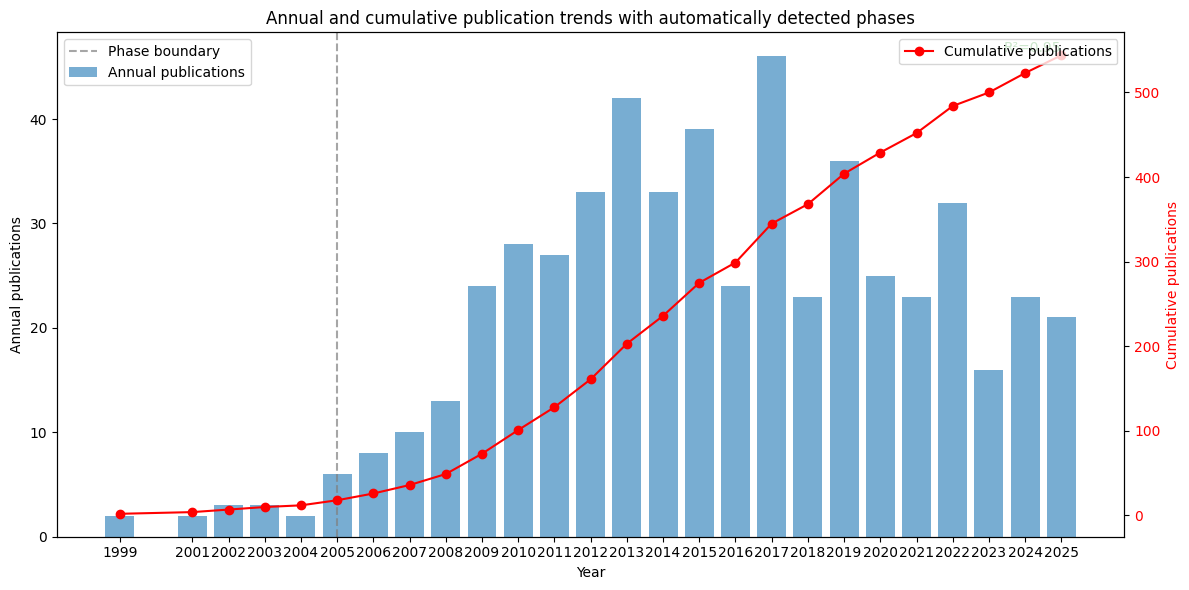

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# Helper functions
def auto_detect_num_phases(annual_df, growth_col="growth_pct", min_phases=1, max_phases=6):
    jumps = annual_df[growth_col].abs().dropna().to_numpy()
    if jumps.size == 0:
        return 1

    threshold = 0.5 * jumps.max()
    phases = int((jumps > threshold).sum()) + 1
    return max(min_phases, min(phases, max_phases))


def detect_phases_auto(annual_df, year_col="year", growth_col="growth_pct", max_phases=3):
    years = annual_df[year_col].tolist()
    growth = annual_df[growth_col].tolist()

    if not years:
        return [], []

    if max_phases <= 1:
        return [(years[0], years[-1])], []

    valid_indices = [i for i in range(1, len(years)) if not np.isnan(growth[i])]
    if not valid_indices:
        return [(years[0], years[-1])], []

    num_breakpoints = min(max_phases - 1, len(valid_indices))
    if num_breakpoints <= 0:
        return [(years[0], years[-1])], []

    growth_values = np.abs([growth[i] for i in valid_indices])
    top_indices = np.argsort(-np.array(growth_values))[:num_breakpoints]
    breakpoints = sorted(years[valid_indices[i]] for i in top_indices)

    phases = []
    start_year = years[0]
    for bp in breakpoints:
        phases.append((start_year, bp - 1))
        start_year = bp
    phases.append((start_year, years[-1]))

    return phases, breakpoints


def summarize_phase(annual_df, start_year, end_year, year_col="year"):
    subset = annual_df[
        (annual_df[year_col] >= start_year) &
        (annual_df[year_col] <= end_year)
    ]

    if subset.empty:
        return {
            "start": int(start_year),
            "end": int(end_year),
            "n_years": 0,
            "total_pubs": 0,
            "mean_per_year": 0.0,
            "min_per_year": 0,
            "max_per_year": 0,
        }

    annual_count = subset["annual_count"]
    return {
        "start": int(start_year),
        "end": int(end_year),
        "n_years": int(len(subset)),
        "total_pubs": int(annual_count.sum()),
        "mean_per_year": float(annual_count.mean()),
        "min_per_year": int(annual_count.min()),
        "max_per_year": int(annual_count.max()),
    }


# ----------------------Main Use-------------------------
df = DATASET()

df = df[df["year"].notna()].copy()
df["year"] = df["year"].astype(str).str.strip()
df = df[df["year"] != ""].copy()
df["year"] = df["year"].astype(int)

annual_counts = (
    df.groupby("year")
    .size()
    .reset_index(name="annual_count")
    .sort_values("year")
    .reset_index(drop=True)
)

annual_counts["cumulative_count"] = annual_counts["annual_count"].cumsum()
annual_counts["growth_pct"] = annual_counts["annual_count"].pct_change() * 100

X = annual_counts[["year"]].to_numpy()
y = annual_counts["cumulative_count"].to_numpy()

model = LinearRegression()
model.fit(X, y)
r2 = r2_score(y, model.predict(X))

auto_num_phases = auto_detect_num_phases(annual_counts)
print(f"Automatically selected number of phases: {auto_num_phases}")

phases, breakpoints = detect_phases_auto(annual_counts, max_phases=auto_num_phases)
phase_stats = [summarize_phase(annual_counts, start, end) for start, end in phases]
phase_stats_df = pd.DataFrame(phase_stats)

print("Detected phases and their statistics:")
for i, stats in enumerate(phase_stats, start=1):
    print(
        f"Phase {i}: {stats['start']}–{stats['end']} | "
        f"years={stats['n_years']}, total={stats['total_pubs']}, "
        f"mean/year={stats['mean_per_year']:.2f}, "
        f"min/year={stats['min_per_year']}, "
        f"max/year={stats['max_per_year']}"
    )

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    annual_counts["year"],
    annual_counts["annual_count"],
    alpha=0.6,
    label="Annual publications",
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Annual publications")
ax1.tick_params(axis="y")

ax2 = ax1.twinx()
ax2.plot(
    annual_counts["year"],
    annual_counts["cumulative_count"],
    color="red",
    marker="o",
    label="Cumulative publications",
)
ax2.set_ylabel("Cumulative publications", color="red")
ax2.tick_params(axis="y", labelcolor="red")

for i, bp in enumerate(breakpoints):
    ax1.axvline(
        x=bp,
        linestyle="--",
        color="gray",
        alpha=0.7,
        label="Phase boundary" if i == 0 else None,
    )

plt.title("Annual and cumulative publication trends with automatically detected phases")
plt.xticks(annual_counts["year"], rotation=45, ha="right")

ax2.text(
    annual_counts["year"].iloc[-1],
    annual_counts["cumulative_count"].iloc[-1],
    f"R²={r2:.2f}",
    color="green",
    fontsize=10,
    ha="right",
    va="bottom",
)

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()
plt_savefig(plt, "publication_trends_with_auto_phases.png")
plt.show()

### Growth Rate Analysis (CAGR) 
CAGR quantifies the average annual growth rate of publications over time using a compound growth model: 


$$
CAGR = \left( \frac{V_{final}}{V_{initial}} \right)^{\frac{1}{n-1}} - 1
$$

    year  annual_count  cagr_from_start
0   1999             2              NaN
1   2000             0        -1.000000
2   2001             2         0.000000
3   2002             3         0.144714
4   2003             3         0.106682
5   2004             2         0.000000
6   2005             6         0.200937
7   2006             8         0.219014
8   2007            10         0.222845
9   2008            13         0.231186
10  2009            24         0.282089
11  2010            28         0.271140
12  2011            27         0.242208
13  2012            33         0.240660
14  2013            42         0.242923
15  2014            33         0.205496
16  2015            39         0.204002
17  2016            24         0.157394
18  2017            46         0.190287
19  2018            23         0.137172
20  2019            36         0.155483
21  2020            25         0.127804
22  2021            23         0.117413
23  2022            32         0.128114


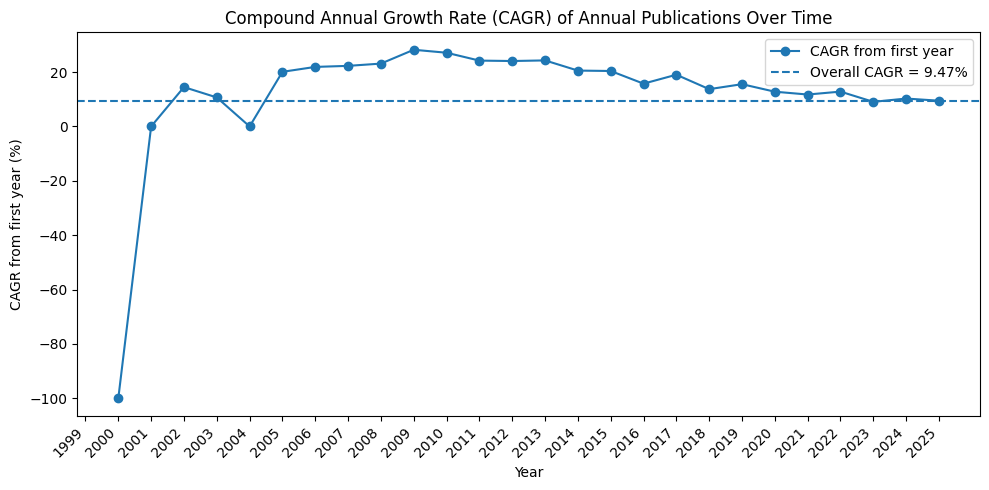

The compound annual growth rate (CAGR) of annual publications over the study period was 9.47%.


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# Load and clean dataset
df = DATASET()

df = df[df["year"].notna()].copy()

df["year"] = pd.to_numeric(
    df["year"].astype(str).str.strip(),
    errors="coerce"
)

df = df[df["year"].notna()].copy()
df["year"] = df["year"].astype(int)


# ---------------------------------------------------------
# Compute annual publication counts
# ---------------------------------------------------------

annual_counts = (
    df.groupby("year")
    .size()
    .rename("annual_count")
)


# ---------------------------------------------------------
# Add missing years with zero publications
# ---------------------------------------------------------

first_year = df["year"].min()
last_year = df["year"].max()

all_years = np.arange(first_year, last_year + 1)

annual_counts = (
    annual_counts
    .reindex(all_years, fill_value=0)
    .rename_axis("year")
    .reset_index()
)


# ---------------------------------------------------------
# Compute overall CAGR
# ---------------------------------------------------------

first_value = annual_counts["annual_count"].iloc[0]
last_value = annual_counts["annual_count"].iloc[-1]

# Actual number of calendar years
n_years = last_year - first_year

overall_cagr = (
    (last_value / first_value) ** (1 / n_years) - 1
    if first_value > 0 and n_years > 0
    else np.nan
)


# ---------------------------------------------------------
# Compute CAGR from the first year to each subsequent year
# ---------------------------------------------------------

annual_counts["cagr_from_start"] = np.nan

for i in range(1, len(annual_counts)):

    current_value = annual_counts.loc[i, "annual_count"]
    current_year = annual_counts.loc[i, "year"]

    elapsed_years = current_year - first_year

    if first_value > 0 and elapsed_years > 0:

        annual_counts.loc[i, "cagr_from_start"] = (
            (current_value / first_value) ** (1 / elapsed_years) - 1
        )


print(annual_counts)

print(f"Overall CAGR (decimal): {overall_cagr:.4f}")
print(f"Overall CAGR (percent): {overall_cagr * 100:.2f}%")


# ---------------------------------------------------------
# Plot CAGR
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    annual_counts["year"],
    annual_counts["cagr_from_start"] * 100,
    marker="o",
    linestyle="-",
    label="CAGR from first year",
)

if not np.isnan(overall_cagr):

    plt.axhline(
        y=overall_cagr * 100,
        linestyle="--",
        label=f"Overall CAGR = {overall_cagr * 100:.2f}%",
    )


plt.xlabel("Year")
plt.ylabel("CAGR from first year (%)")

plt.title(
    "Compound Annual Growth Rate (CAGR) of Annual Publications Over Time"
)

plt.xticks(
    annual_counts["year"],
    rotation=45,
    ha="right"
)

plt.legend()
plt.tight_layout()

plt_savefig(
    plt,
    "cagr_over_time.png"
)

plt.show()


# ---------------------------------------------------------
# Manuscript sentence
# ---------------------------------------------------------

if not np.isnan(overall_cagr):

    print(
        f"The compound annual growth rate (CAGR) of annual publications "
        f"over the study period was {overall_cagr * 100:.2f}%."
    )

### Annual and Cumulative Publication Trends
This analysis compares yearly publication counts with cumulative growth trajectories to assess long-term expansion trends in the field.

R2 is 0.9517619737872406


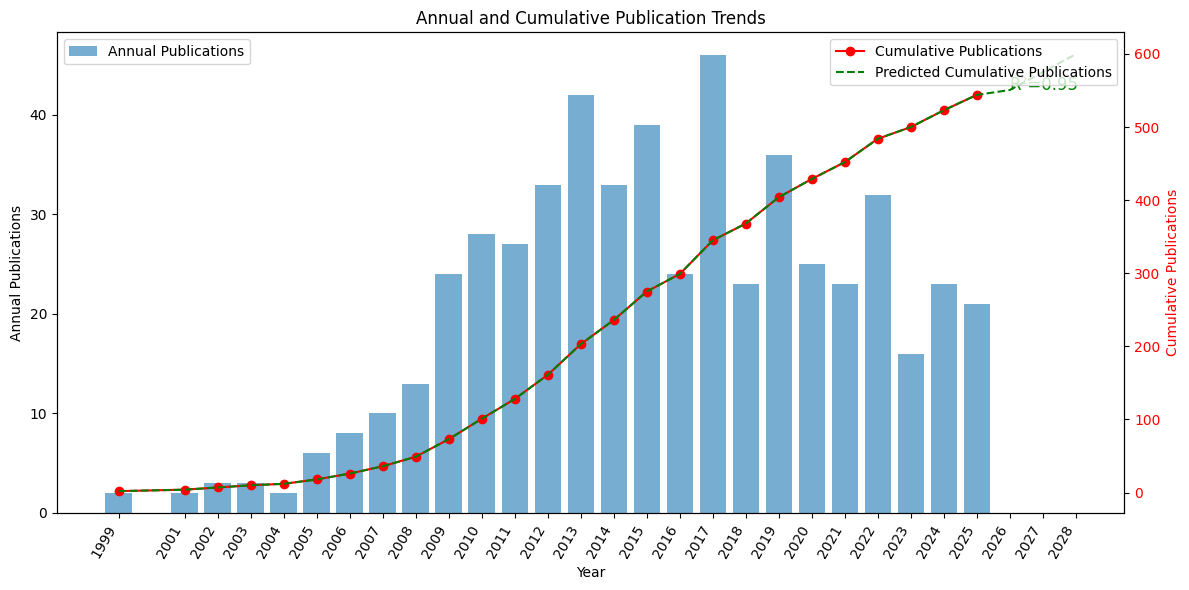

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# ----------------------Main Use-------------------------
df = DATASET()

df = df[df["year"].notna()].copy()
df["year"] = pd.to_numeric(df["year"].astype(str).str.strip(), errors="coerce")
df = df[df["year"].notna()].copy()
df["year"] = df["year"].astype(int)

annual_counts = (
    df.groupby("year")
    .size()
    .reset_index(name="annual_count")
    .sort_values("year")
    .reset_index(drop=True)
)
annual_counts["cumulative_count"] = annual_counts["annual_count"].cumsum()

X = annual_counts[["year"]].to_numpy()
y = annual_counts["cumulative_count"].to_numpy()

model = LinearRegression().fit(X, y)
r2 = r2_score(y, model.predict(X))

last_year = annual_counts["year"].max()
future_years = np.arange(last_year + 1, last_year + 4).reshape(-1, 1)
future_predictions = model.predict(future_years)

predicted_years = np.concatenate([annual_counts["year"].to_numpy(), future_years.ravel()])
predicted_cumulative = np.concatenate([y, future_predictions])

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    annual_counts["year"],
    annual_counts["annual_count"],
    alpha=0.6,
    label="Annual Publications",
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Annual Publications")

ax2 = ax1.twinx()
ax2.plot(
    annual_counts["year"],
    annual_counts["cumulative_count"],
    color="red",
    marker="o",
    label="Cumulative Publications",
)
ax2.plot(
    predicted_years,
    predicted_cumulative,
    color="green",
    linestyle="dashed",
    label="Predicted Cumulative Publications",
)
ax2.set_ylabel("Cumulative Publications", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Annual and Cumulative Publication Trends")
ax1.set_xticks(np.sort(predicted_years))
ax1.set_xticklabels(np.sort(predicted_years), rotation=60, ha="right")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
ax2.text(
    future_years[0, 0],
    future_predictions[0],
    f"R²={r2:.2f}",
    color="green",
    fontsize=12,
)

plt.tight_layout()

print(f"R2 is {r2}" )
plt_savefig(plt, "annual_and_cumulative_publication_trends.png")
plt.show()

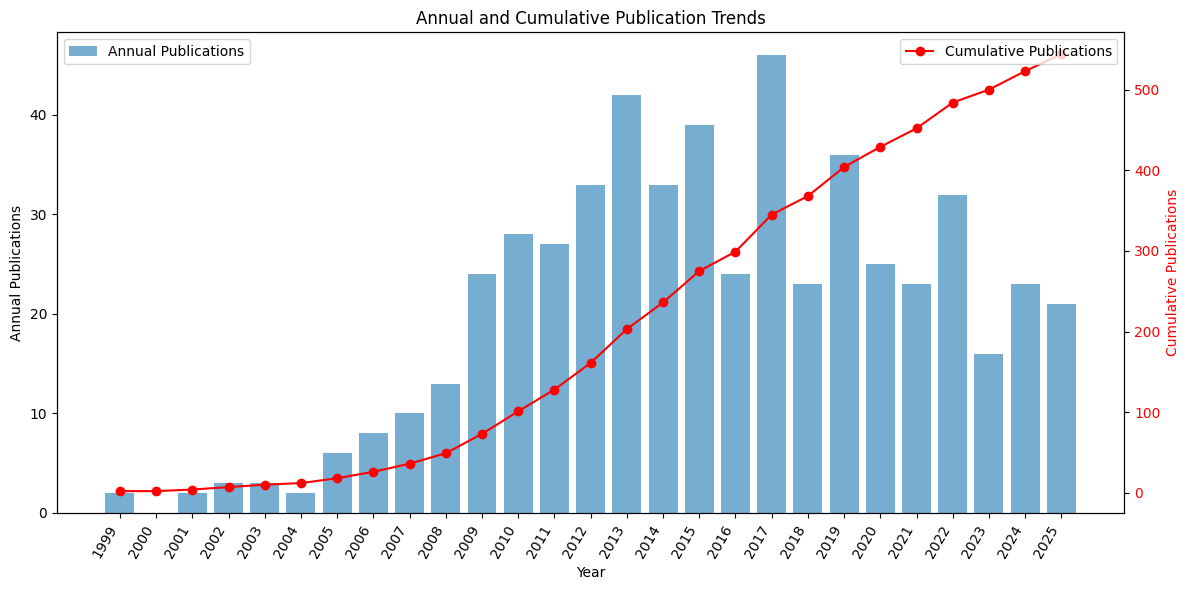

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# ---------------------- Main Use -------------------------

df = DATASET()

# Clean the year column
df = df[df["year"].notna()].copy()

df["year"] = pd.to_numeric(
    df["year"].astype(str).str.strip(),
    errors="coerce"
)

df = df[df["year"].notna()].copy()
df["year"] = df["year"].astype(int)


# ---------------------------------------------------------
# Count publications for each year
# ---------------------------------------------------------

annual_counts = (
    df.groupby("year")
    .size()
    .rename("annual_count")
)


# ---------------------------------------------------------
# Add missing years with zero publications
# ---------------------------------------------------------

min_year = df["year"].min()
max_year = df["year"].max()

all_years = np.arange(min_year, max_year + 1)

annual_counts = (
    annual_counts
    .reindex(all_years, fill_value=0)
    .rename_axis("year")
    .reset_index()
)


# ---------------------------------------------------------
# Calculate cumulative publications
# ---------------------------------------------------------

annual_counts["cumulative_count"] = (
    annual_counts["annual_count"].cumsum()
)


# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(12, 6))


# Annual publications
ax1.bar(
    annual_counts["year"],
    annual_counts["annual_count"],
    alpha=0.6,
    label="Annual Publications",
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Annual Publications")


# Cumulative publications
ax2 = ax1.twinx()

ax2.plot(
    annual_counts["year"],
    annual_counts["cumulative_count"],
    color="red",
    marker="o",
    label="Cumulative Publications",
)

ax2.set_ylabel(
    "Cumulative Publications",
    color="red"
)

ax2.tick_params(
    axis="y",
    labelcolor="red"
)


# ---------------------------------------------------------
# Figure settings
# ---------------------------------------------------------

plt.title(
    "Annual and Cumulative Publication Trends"
)

# Show every year on the X-axis
ax1.set_xticks(annual_counts["year"])

ax1.set_xticklabels(
    annual_counts["year"],
    rotation=60,
    ha="right"
)

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()


# ---------------------------------------------------------
# Save figure
# ---------------------------------------------------------

plt_savefig(
    plt,
    "annual_and_cumulative_publication_trends.png"
)

plt.show()

## Citation Analysis

### Top-Cited Publications
The most highly cited articles are identified to highlight influential works shaping the field. Citation counts serve as a proxy for scientific impact.

✅ `top_most_cited_article.csv` as CSV saved. 


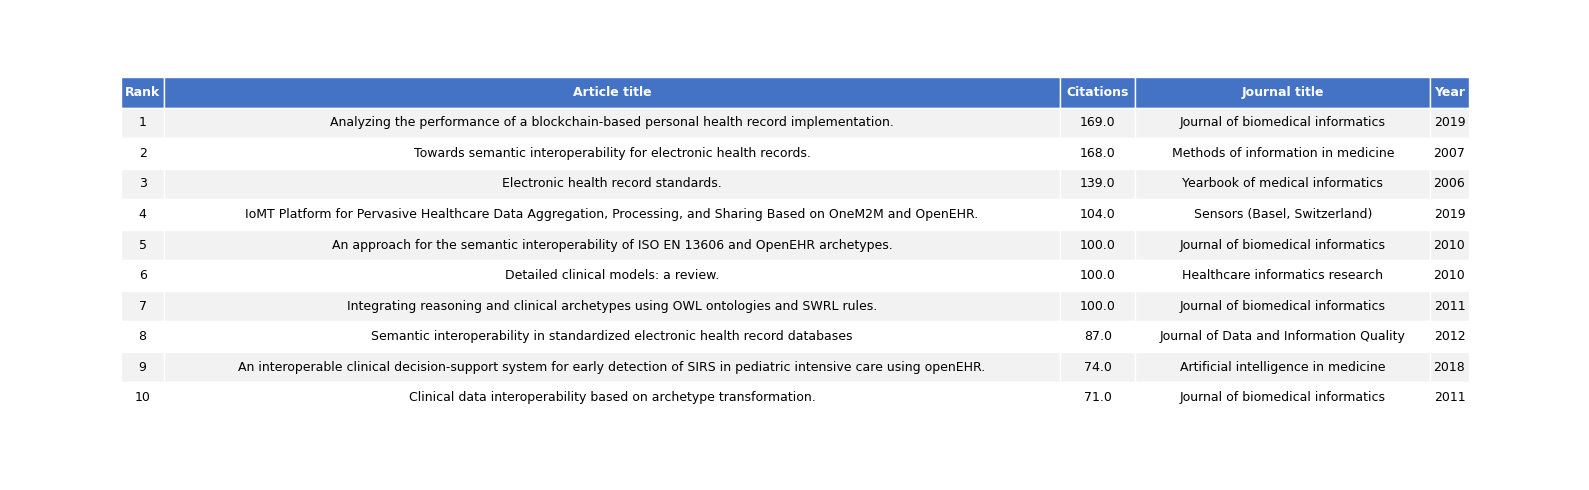

In [2]:
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv, plt_savefig


# ----------------------Main Use-------------------------
df = DATASET()

top_df = (
    df.sort_values("citation_count", ascending=False)
    .reset_index(drop=True)
)

top_df["Rank"] = top_df.index + 1

dataframe_to_csv(top_df, "top_most_cited_article.csv")

top10 = top_df.head(10)[["Rank", "title", "citation_count", "publisher", "year"]]
top10.columns = ["Rank", "Article title", "Citations", "Journal title", "Year"]

fig, ax = plt.subplots(figsize=(16, 5))
ax.axis("off")

table = ax.table(
    cellText=top10.values,
    colLabels=top10.columns,
    cellLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("w")
    if row == 0:
        cell.set_facecolor("#4472C4")
        cell.set_text_props(weight="bold", color="w")
    elif row % 2 == 1:
        cell.set_facecolor("#F2F2F2")

table.auto_set_column_width(col=list(range(len(top10.columns))))

plt.tight_layout()
plt_savefig(plt, "top_most_cited_article.png")
plt.show()

### Year-specific citation info

✅ `year_specific_citation_info.csv` as CSV saved. 


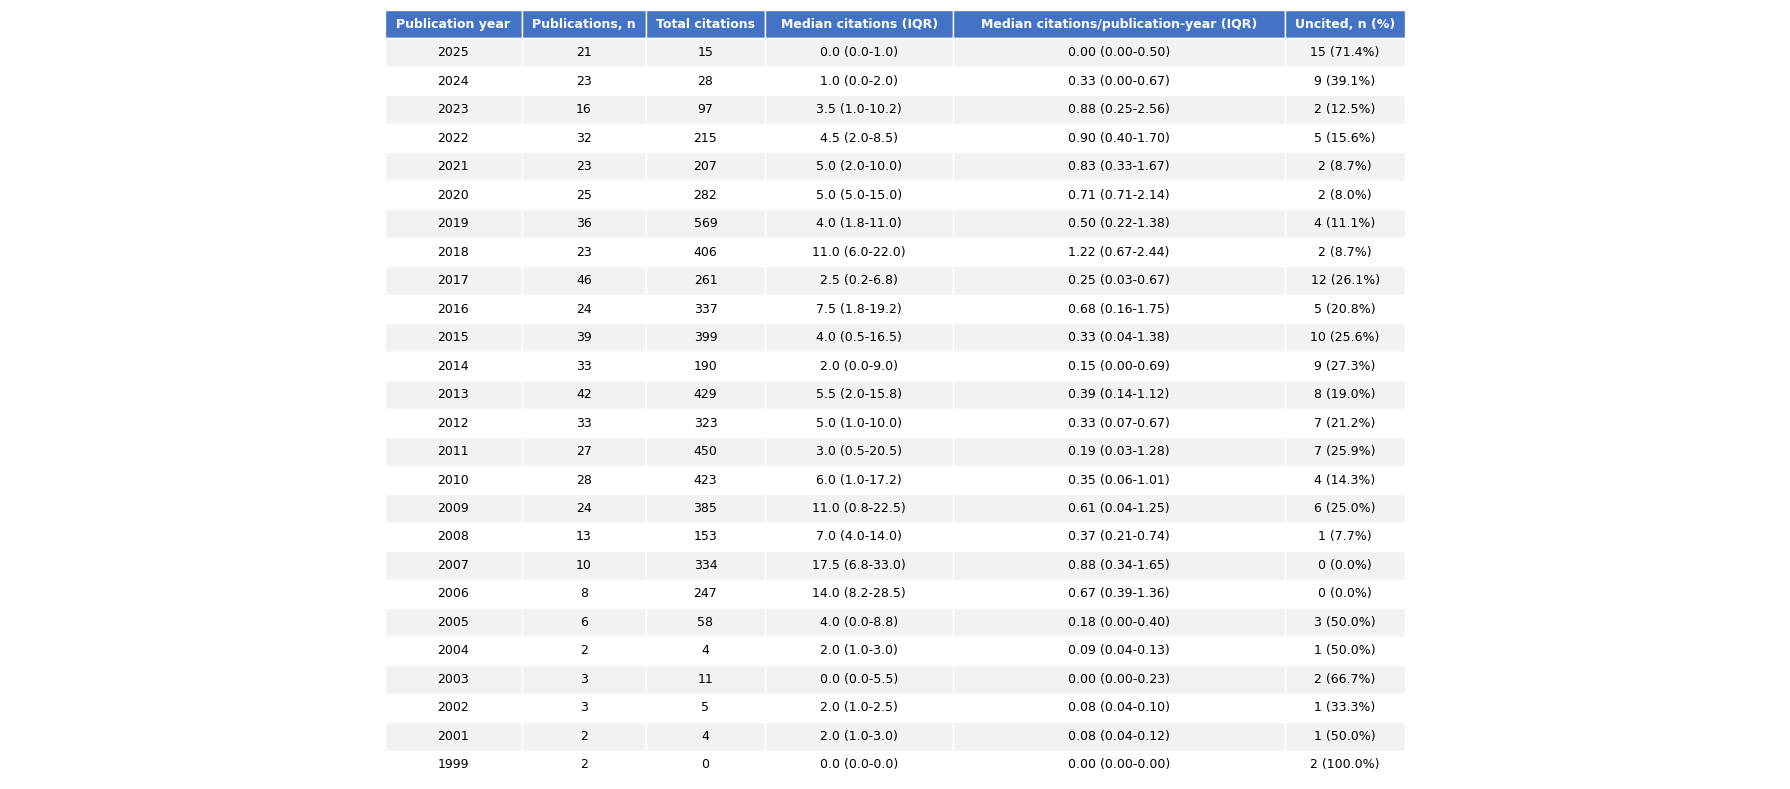

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv, plt_savefig


# ----------------------Main Use-------------------------
df = DATASET()

ANALYSIS_YEAR = 2026

# Convert required columns to numeric
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["citation_count"] = pd.to_numeric(
    df["citation_count"],
    errors="coerce"
)

# Remove rows without a valid publication year
df = df.dropna(subset=["year"]).copy()

# Convert year to integer
df["year"] = df["year"].astype(int)

# Replace missing citation counts with 0
df["citation_count"] = df["citation_count"].fillna(0)

# Calculate publication age
df["publication_age"] = ANALYSIS_YEAR - df["year"] + 1

# Calculate citations per publication-year
df["citations_per_publication_year"] = (
    df["citation_count"] / df["publication_age"]
)

df["citations_per_publication_year"] = (
    df["citation_count"] / df["publication_age"]
)


def median_iqr(series):
    series = series.dropna()

    median = series.median()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    return median, q1, q3


rows = []

for year, group in df.groupby("year"):

    publications_n = len(group)

    # Citation statistics
    citation_median, citation_q1, citation_q3 = median_iqr(
        group["citation_count"]
    )

    # Citation / publication-year statistics
    yearly_median, yearly_q1, yearly_q3 = median_iqr(
        group["citations_per_publication_year"]
    )

    # Uncited publications
    uncited_n = (group["citation_count"] == 0).sum()
    uncited_percent = (uncited_n / publications_n) * 100

    rows.append(
        {
            "Publication year": int(year),
            "Publications, n": publications_n,
            "Total citations": int(group["citation_count"].sum()),
            "Median citations (IQR)": (
                f"{citation_median:.1f} "
                f"({citation_q1:.1f}-{citation_q3:.1f})"
            ),
            "Median citations/publication-year (IQR)": (
                f"{yearly_median:.2f} "
                f"({yearly_q1:.2f}-{yearly_q3:.2f})"
            ),
            "Uncited, n (%)": (
                f"{uncited_n} ({uncited_percent:.1f}%)"
            ),
        }
    )


year_df = pd.DataFrame(rows)

year_df = (
    year_df.sort_values("Publication year", ascending=False)
    .reset_index(drop=True)
)


# Save CSV
dataframe_to_csv(
    year_df,
    "year_specific_citation_info.csv"
)


# ----------------------Table-------------------------
fig, ax = plt.subplots(figsize=(18, 8))
ax.axis("off")

table = ax.table(
    cellText=year_df.values,
    colLabels=year_df.columns,
    cellLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)


for (row, col), cell in table.get_celld().items():

    cell.set_edgecolor("w")

    if row == 0:
        cell.set_facecolor("#4472C4")
        cell.set_text_props(
            weight="bold",
            color="w"
        )

    elif row % 2 == 1:
        cell.set_facecolor("#F2F2F2")


table.auto_set_column_width(
    col=list(range(len(year_df.columns)))
)

plt.tight_layout()

plt_savefig(
    plt,
    "year_specific_citation_info.png"
)

plt.show()

### Publication–Citation Dynamics Over Time
This analysis examines the relationship between publication volume and citation accumulation over time, revealing lag effects and impact trends.

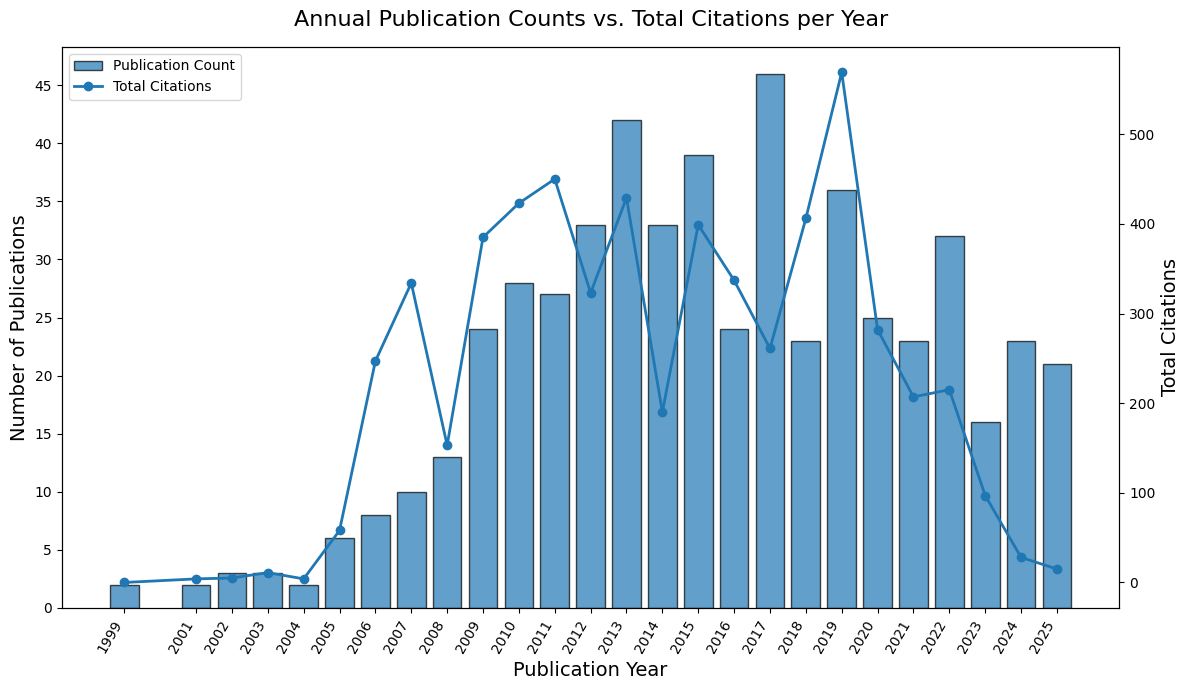

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# ----------------------Main Use-------------------------
df = DATASET()

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0).astype(int)

df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

annual_metrics_df = (
    df.groupby("year", as_index=False)
    .agg(
        Publication_Count=("DBUID", "count"),
        Total_Citations=("citation_count", "sum"),
    )
    .sort_values("year")
)

annual_metrics_df["Publication_Count"] = annual_metrics_df["Publication_Count"].astype(int)
annual_metrics_df["Total_Citations"] = annual_metrics_df["Total_Citations"].astype(int)

years = annual_metrics_df["year"]
pub_counts = annual_metrics_df["Publication_Count"]
total_cites = annual_metrics_df["Total_Citations"]

fig, ax1 = plt.subplots(figsize=(12, 7))

bars = ax1.bar(years, pub_counts, alpha=0.7, edgecolor="black", label="Publication Count")
ax1.set_xlabel("Publication Year", fontsize=14)
ax1.set_ylabel("Number of Publications", fontsize=14)
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.set_xticks(years)
ax1.set_xticklabels(years, rotation=60, ha="right")

ax2 = ax1.twinx()
line = ax2.plot(years, total_cites, marker="o", linewidth=2, label="Total Citations")
ax2.set_ylabel("Total Citations", fontsize=14)

ax1.legend([bars, line[0]], ["Publication Count", "Total Citations"], loc="upper left")

plt.title("Annual Publication Counts vs. Total Citations per Year", fontsize=16, pad=15)
plt.tight_layout()

plt_savefig(plt, "annual_publications_vs_citations_dual_axis.png")
plt.show()
plt.close()

### Normalized Citation Impact Over Time
To reduce the temporal bias inherent in raw citation counts, citation impact was normalized by article age. For each publication, citations per year were calculated as total citations divided by the number of years since publication. Annual mean and median normalized citation impact were then plotted alongside publication counts to compare research output with age-adjusted scholarly influence over time.

$$
\text{Citations per Year} = \frac{\text{Total Citations}}{\text{2025 - Publication Year + 1}}
$$

✅ `normalized_citation_impact_by_year.csv` as CSV saved. 


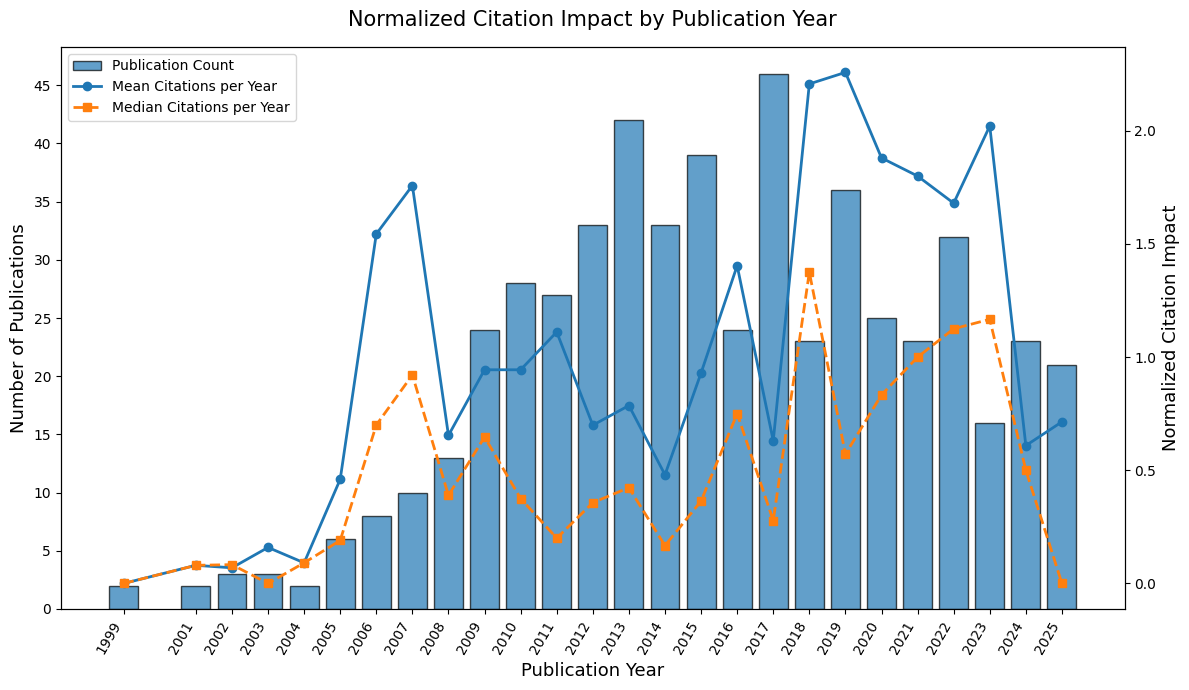

The highest mean normalized citation impact was observed in 2019 (2.26 citations per year).
The highest median normalized citation impact was observed in 2018 (1.38 citations per year).


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
END_YEAR = 2025

df = DATASET()

# Load and clean
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

df = df[(df["year"] > 0) & (df["year"] <= END_YEAR)].copy()

if df.empty:
    raise ValueError("No valid publication years found for normalized citation analysis.")

# Compute normalized citations
df["article_age"] = END_YEAR - df["year"] + 1
df["citations_per_year"] = df["citation_count"] / df["article_age"]

# Aggregate by publication year
yearly_norm_df = (
    df.groupby("year", as_index=False)
    .agg(
        Publication_Count=("DBUID", "count"),
        Total_Citations=("citation_count", "sum"),
        Mean_Citations_Per_Year=("citations_per_year", "mean"),
        Median_Citations_Per_Year=("citations_per_year", "median"),
    )
    .sort_values("year")
    .reset_index(drop=True)
)

yearly_norm_df["Publication_Count"] = yearly_norm_df["Publication_Count"].astype(int)
yearly_norm_df["Total_Citations"] = yearly_norm_df["Total_Citations"].round(2)
yearly_norm_df["Mean_Citations_Per_Year"] = yearly_norm_df["Mean_Citations_Per_Year"].round(3)
yearly_norm_df["Median_Citations_Per_Year"] = yearly_norm_df["Median_Citations_Per_Year"].round(3)

dataframe_to_csv(yearly_norm_df, "normalized_citation_impact_by_year.csv")

# Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

bars = ax1.bar(
    yearly_norm_df["year"],
    yearly_norm_df["Publication_Count"],
    alpha=0.7,
    edgecolor="black",
    label="Publication Count"
)

ax1.set_xlabel("Publication Year", fontsize=13)
ax1.set_ylabel("Number of Publications", fontsize=13)
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.set_xticks(yearly_norm_df["year"])
ax1.set_xticklabels(yearly_norm_df["year"], rotation=60, ha="right")

ax2 = ax1.twinx()

line1 = ax2.plot(
    yearly_norm_df["year"],
    yearly_norm_df["Mean_Citations_Per_Year"],
    marker="o",
    linewidth=2,
    label="Mean Citations per Year"
)

line2 = ax2.plot(
    yearly_norm_df["year"],
    yearly_norm_df["Median_Citations_Per_Year"],
    marker="s",
    linewidth=2,
    linestyle="--",
    label="Median Citations per Year"
)

ax2.set_ylabel("Normalized Citation Impact", fontsize=13)

handles = [bars, line1[0], line2[0]]
labels = ["Publication Count", "Mean Citations per Year", "Median Citations per Year"]
ax1.legend(handles, labels, loc="upper left")

plt.title("Normalized Citation Impact by Publication Year", fontsize=15, pad=15)
plt.tight_layout()

plt_savefig(plt, "normalized_citation_impact_by_year.png")
plt.show()
plt.close()

# Manuscript text
peak_mean_row = yearly_norm_df.loc[yearly_norm_df["Mean_Citations_Per_Year"].idxmax()]
peak_median_row = yearly_norm_df.loc[yearly_norm_df["Median_Citations_Per_Year"].idxmax()]

print(
    f"The highest mean normalized citation impact was observed in {int(peak_mean_row['year'])} "
    f"({peak_mean_row['Mean_Citations_Per_Year']:.2f} citations per year)."
)

print(
    f"The highest median normalized citation impact was observed in {int(peak_median_row['year'])} "
    f"({peak_median_row['Median_Citations_Per_Year']:.2f} citations per year)."
)

## Geographic Analysis

### Leading Contributing Countries
Countries are ranked based on publication output, with additional metrics including citation counts and percentage contribution.

✅ `countries_by_publication.csv` as CSV saved. 


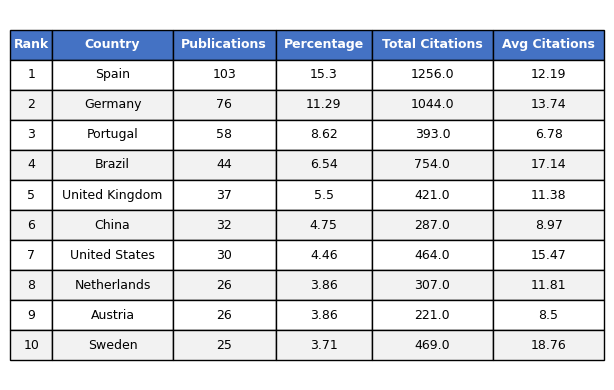

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

country_stats = (
    df.explode("affiliation_country")
    .groupby("affiliation_country", dropna=False)
    .agg(Publications=("title", "count"), **{"Total Citations": ("citation_count", "sum")})
    .reset_index()
)

total_publications = country_stats["Publications"].sum()
country_stats["Percentage"] = country_stats["Publications"] / total_publications * 100
country_stats["Avg Citations"] = (
    country_stats["Total Citations"] / country_stats["Publications"]
)

dataframe_to_csv(country_stats, "countries_by_publication.csv")

country_stats = (
    country_stats.sort_values("Publications", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

country_stats["Rank"] = country_stats.index + 1
country_stats = country_stats[
    ["Rank", "affiliation_country", "Publications", "Percentage", "Total Citations", "Avg Citations"]
].rename(columns={"affiliation_country": "Country"})

numeric_columns = ["Publications", "Percentage", "Total Citations", "Avg Citations"]
country_stats[numeric_columns] = (
    country_stats[numeric_columns].apply(pd.to_numeric, errors="coerce").round(2)
)

fig, ax = plt.subplots(figsize=(5, 4))
ax.axis("off")

table = ax.table(
    cellText=country_stats.values,
    colLabels=country_stats.columns,
    loc="center",
    cellLoc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
table.auto_set_column_width(col=list(range(len(country_stats.columns))))

for j in range(len(country_stats.columns)):
    cell = table[(0, j)]
    cell.set_facecolor("#4472C4")
    cell.set_text_props(color="white", weight="bold")

for i in range(1, len(country_stats) + 1):
    for j in range(len(country_stats.columns)):
        table[(i, j)].set_facecolor("#F2F2F2" if i % 2 == 0 else "white")

plt.tight_layout()
plt_savefig(plt, "top_10_countries_by_publication.png")
plt.show()

### Global Distribution of Publications and Citation Impact
A choropleth map visualizes publication distribution across countries, while bubble overlays represent average citation impact, highlighting geographic disparities.

In [ ]:
import ast
import pandas as pd
import plotly.express as px
import pycountry

from src.config import OUTPUT_DIR
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv


# ============================================================
# Settings
# ============================================================

CHOROPLETH_MIN_PUBLICATIONS = 1
BUBBLE_MIN_PUBLICATIONS = 2


# ============================================================
# Load dataset
# ============================================================

df = DATASET().copy()


# ============================================================
# Required columns
# ============================================================

required_columns = {
    "affiliation_country",
    "citation_count",
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Required column(s) missing from dataset: "
        f"{sorted(missing_columns)}"
    )


# ============================================================
# Create a reliable publication ID
# ============================================================
#
# DBUID is preferred if available.
# If DBUID is missing for some records, a row-based ID is used.
#
# ============================================================

df = df.reset_index(drop=True)

if "DBUID" in df.columns:

    publication_id = (
        df["DBUID"]
        .astype("string")
        .str.strip()
    )

    missing_id = (
        publication_id.isna()
        | publication_id.eq("")
    )

    df["_publication_id"] = publication_id.astype(object)

    df.loc[
        missing_id,
        "_publication_id"
    ] = [
        f"__row_{i}"
        for i in df.index[missing_id]
    ]

else:

    df["_publication_id"] = [
        f"__row_{i}"
        for i in df.index
    ]


# ============================================================
# Helper: safely convert affiliation-country values to lists
# ============================================================

def safe_eval_list(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if pd.isna(value):
        return []

    if not isinstance(value, str):
        return [value]

    value = value.strip()

    if value == "":
        return []

    try:

        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, (tuple, set)):
            return list(parsed)

        return [parsed]

    except (ValueError, SyntaxError):

        # If the value is simply a normal country name
        # such as "Germany", keep it as one item.
        return [value]


# ============================================================
# Country-name normalization
# ============================================================
#
# pycountry handles most country names.
# The manual mapping handles common bibliographic variants.
#
# Values in this dictionary are canonical names that
# pycountry can resolve reliably.
#
# ============================================================

from src.lib_dataset import COUNTRY_ALIASES

# ============================================================
# Normalize country and resolve ISO-3
# ============================================================

def normalize_country(country):

    if pd.isna(country):
        return None

    country = str(country).strip()

    if country == "":
        return None

    # Collapse repeated whitespace
    country = " ".join(country.split())

    alias = COUNTRY_ALIASES.get(
        country.lower(),
        country
    )

    try:

        matched = pycountry.countries.lookup(alias)

        return {
            "Country": matched.name,
            "ISO3": matched.alpha_3,
        }

    except LookupError:

        return {
            "Country": country,
            "ISO3": None,
        }


# ============================================================
# Prepare affiliation countries
# ============================================================

df["affiliation_country"] = (
    df["affiliation_country"]
    .apply(safe_eval_list)
)


# ============================================================
# Citation data
# ============================================================
#
# IMPORTANT:
# Missing citation values remain NaN.
#
# NaN != zero citations
#
# ============================================================

df["citation_count"] = pd.to_numeric(
    df["citation_count"],
    errors="coerce"
)


# ============================================================
# Explode countries
# ============================================================

country_long = (
    df[
        [
            "_publication_id",
            "affiliation_country",
            "citation_count",
        ]
    ]
    .explode("affiliation_country")
    .copy()
)


country_long["affiliation_country"] = (
    country_long["affiliation_country"]
    .astype("string")
    .str.strip()
)


country_long = country_long[
    country_long["affiliation_country"].notna()
].copy()


country_long = country_long[
    country_long["affiliation_country"] != ""
].copy()


if country_long.empty:

    raise ValueError(
        "No valid affiliation-country data were found."
    )


# ============================================================
# Normalize country names and assign ISO-3
# ============================================================

country_info = (
    country_long["affiliation_country"]
    .apply(normalize_country)
)


country_long["Country"] = country_info.apply(
    lambda x: x["Country"] if x else None
)

country_long["ISO3"] = country_info.apply(
    lambda x: x["ISO3"] if x else None
)


# ============================================================
# Report unresolved country names
# ============================================================

unresolved_df = (
    country_long[
        country_long["ISO3"].isna()
    ][
        ["affiliation_country"]
    ]
    .drop_duplicates()
    .rename(
        columns={
            "affiliation_country":
                "Unresolved_Country_Name"
        }
    )
    .sort_values(
        "Unresolved_Country_Name"
    )
    .reset_index(drop=True)
)


if not unresolved_df.empty:

    print(
        "\nWARNING: The following country names "
        "could not be converted to ISO-3:"
    )

    print(
        unresolved_df.to_string(
            index=False
        )
    )

    dataframe_to_csv(
        unresolved_df,
        "unresolved_country_names.csv"
    )


# ============================================================
# Keep only countries with valid ISO-3 codes
# ============================================================

country_long = country_long.dropna(
    subset=[
        "Country",
        "ISO3"
    ]
).copy()


if country_long.empty:

    raise ValueError(
        "No country names could be resolved to valid ISO-3 codes."
    )


# ============================================================
# Remove duplicate country occurrences within each publication
# ============================================================
#
# Example:
#
# Publication A:
#
# ["Germany", "Germany", "Austria"]
#
# becomes:
#
# Germany -> 1 publication
# Austria -> 1 publication
#
# instead of counting Germany twice.
#
# ============================================================

country_long = (
    country_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "ISO3"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Country-level bibliometric statistics
# ============================================================
#
# Whole-counting approach:
#
# A multinational publication contributes one publication
# to every participating country.
#
# Citations are therefore also attributed to each participating
# country.
#
# ============================================================

country_stats_df = (
    country_long
    .groupby(
        ["ISO3", "Country"],
        as_index=False
    )
    .agg(

        Publication_Count=(
            "_publication_id",
            "nunique"
        ),

        Citation_Data_Available=(
            "citation_count",
            "count"
        ),

        Total_Citations=(
            "citation_count",
            "sum"
        ),

        Mean_Citations=(
            "citation_count",
            "mean"
        ),

        Median_Citations=(
            "citation_count",
            "median"
        ),
    )
)


# ============================================================
# Citation-data coverage
# ============================================================

country_stats_df["Citation_Coverage_%"] = (

    100
    * country_stats_df[
        "Citation_Data_Available"
    ]
    / country_stats_df[
        "Publication_Count"
    ]

).round(2)


# ============================================================
# Clean output types
# ============================================================

country_stats_df["Publication_Count"] = (
    country_stats_df["Publication_Count"]
    .astype(int)
)


country_stats_df["Citation_Data_Available"] = (
    country_stats_df[
        "Citation_Data_Available"
    ]
    .astype(int)
)


country_stats_df["Total_Citations"] = (
    country_stats_df["Total_Citations"]
    .fillna(0)
    .round(0)
    .astype(int)
)


country_stats_df["Mean_Citations"] = (
    country_stats_df[
        "Mean_Citations"
    ]
    .round(2)
)


country_stats_df["Median_Citations"] = (
    country_stats_df[
        "Median_Citations"
    ]
    .round(2)
)


# ============================================================
# Sort and save full country table
# ============================================================

country_stats_df = (
    country_stats_df
    .sort_values(
        [
            "Publication_Count",
            "Total_Citations"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


dataframe_to_csv(
    country_stats_df,
    "global_country_publication_citation_statistics.csv"
)


# ============================================================
# Basic validation
# ============================================================

print(
    f"\nNumber of countries with valid ISO-3 codes: "
    f"{country_stats_df['ISO3'].nunique()}"
)

print(
    f"Total country-publication links: "
    f"{country_stats_df['Publication_Count'].sum()}"
)

print(
    "Note: The total above can exceed the number of articles "
    "because multinational publications are counted once "
    "for each participating country (whole counting)."
)


# ============================================================
# Choropleth data
# ============================================================

choropleth_df = country_stats_df[
    country_stats_df["Publication_Count"]
    >= CHOROPLETH_MIN_PUBLICATIONS
].copy()


if choropleth_df.empty:

    raise ValueError(
        "No countries satisfy the minimum publication "
        "threshold for the choropleth map."
    )


# ============================================================
# Bubble data
# ============================================================
#
# Mean citation impact is only meaningful when citation
# information is available.
#
# ============================================================

bubble_df = country_stats_df[
    (
        country_stats_df["Publication_Count"]
        >= BUBBLE_MIN_PUBLICATIONS
    )
    &
    (
        country_stats_df[
            "Citation_Data_Available"
        ] > 0
    )
    &
    (
        country_stats_df[
            "Mean_Citations"
        ].notna()
    )
].copy()


# ============================================================
# Choropleth
# ============================================================

fig = px.choropleth(

    choropleth_df,

    locations="ISO3",

    locationmode="ISO-3",

    color="Publication_Count",

    hover_name="Country",

    hover_data={
        "ISO3": False,
        "Publication_Count": True,
        "Total_Citations": True,
        "Mean_Citations": ":.2f",
        "Median_Citations": ":.2f",
        "Citation_Coverage_%": ":.1f",
    },

    color_continuous_scale="Viridis",

    labels={
        "Publication_Count":
            "Publication Count",

        "Total_Citations":
            "Total Citations",

        "Mean_Citations":
            "Mean Citations",

        "Median_Citations":
            "Median Citations",

        "Citation_Coverage_%":
            "Citation Coverage (%)",
    },
)


# ============================================================
# Citation-impact bubbles
# ============================================================
#
# Bubble AREA is proportional to mean citations.
#
# Zero mean-citation countries will not create visible bubbles.
#
# ============================================================

if not bubble_df.empty:

    # Plotly requires non-negative bubble sizes.
    # Mean citation counts satisfy this assumption.

    fig_bubble = px.scatter_geo(

        bubble_df,

        locations="ISO3",

        locationmode="ISO-3",

        size="Mean_Citations",

        hover_name="Country",

        hover_data={
            "ISO3": False,
            "Publication_Count": True,
            "Total_Citations": True,
            "Mean_Citations": ":.2f",
            "Median_Citations": ":.2f",
            "Citation_Data_Available": True,
            "Citation_Coverage_%": ":.1f",
        },

        size_max=35,

    )


    for trace in fig_bubble.data:

        trace.name = "Mean Citation Impact"

        trace.showlegend = True

        fig.add_trace(trace)


# ============================================================
# Figure layout
# ============================================================

fig.update_geos(

    showcoastlines=True,

    showcountries=True,

    showframe=False,

    projection_type="natural earth",
)


fig.update_layout(

    title={
        "text":
            "Global Distribution of Publications and Citation Impact",

        "x": 0.5,
    },

    margin=dict(
        l=0,
        r=0,
        t=60,
        b=0,
    ),
)


# ============================================================
# Save interactive HTML
# ============================================================

html_path = (
    OUTPUT_DIR
    / "world_choropleth_publications_mean_citations.html"
)


fig.write_html(
    str(html_path)
)


print(
    "Saved interactive HTML: "
    "world_choropleth_publications_mean_citations.html"
)


# ============================================================
# Save PNG
# ============================================================
#
# Plotly static export requires Kaleido.
#
# ============================================================

png_path = (
    OUTPUT_DIR
    / "world_choropleth_publications_mean_citations.png"
)


try:

    fig.write_image(
        str(png_path),
        format="png",
        scale=2,
    )

    print(
        "Saved PNG: "
        "world_choropleth_publications_mean_citations.png"
    )

except Exception as e:

    print(
        "Could not save PNG. "
        "Plotly static export may require Kaleido."
    )

    print(
        f"Error: {e}"
    )


# ============================================================
# Display figure
# ============================================================

fig.show()

✅ `global_country_publication_citation_statistics.csv` as CSV saved. 

Number of countries with valid ISO-3 codes: 61
Total country-publication links: 667
Note: The total above can exceed the number of articles because multinational publications are counted once for each participating country (whole counting).
Saved interactive HTML: world_choropleth_publications_mean_citations.html
Saved PNG: world_choropleth_publications_mean_citations.png


![world_choropleth_publications_mean_citations](./output/world_choropleth_publications_mean_citations.png)

### Cartogram of Country-Level Publication Intensity
A cartogram distorts country sizes proportionally to publication output, emphasizing dominant contributors in the global research landscape.

Use [SCImago Graphica](https://www.graphica.app/)
A cartogram is a map in which the size and shape of the different regions are distorted to depict the values of a quantitative variable.

To create a cartogram:
- Link a geographic variable (Country) to 'unit' and in Marks select 'filled map'.
- Link a quantitative variable to ‘Size’.

![cartogram](./output/Cartogram.jpg)

In [ ]:
import ast
import pandas as pd
import numpy as np
import pycountry

from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv


# ============================================================
# Settings
# ============================================================

OUTPUT_FILENAME = "country_list_for_cartogram.csv"


# ============================================================
# Load dataset
# ============================================================

df = DATASET().copy()


# ============================================================
# Required columns
# ============================================================

required_columns = {
    "affiliation_country",
    "citation_count",
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Required column(s) missing from dataset: "
        f"{sorted(missing_columns)}"
    )


# ============================================================
# Create publication identifier
# ============================================================
#
# DBUID is preferred because country counts should be based
# on unique publications rather than affiliation occurrences.
#
# If DBUID is unavailable or missing for a row, a unique
# row-based identifier is generated.
#
# ============================================================

df = df.reset_index(drop=True)

if "DBUID" in df.columns:

    publication_id = (
        df["DBUID"]
        .astype("string")
        .str.strip()
    )

    missing_id = (
        publication_id.isna()
        | publication_id.eq("")
    )

    df["_publication_id"] = publication_id.astype(object)

    df.loc[
        missing_id,
        "_publication_id"
    ] = [
        f"__row_{i}"
        for i in df.index[missing_id]
    ]

else:

    df["_publication_id"] = [
        f"__row_{i}"
        for i in df.index
    ]


# ============================================================
# Helper: safely convert country values to a list
# ============================================================

def safe_eval_list(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if pd.isna(value):
        return []

    if not isinstance(value, str):
        return [value]

    value = value.strip()

    if value == "":
        return []

    try:

        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, (tuple, set)):
            return list(parsed)

        return [parsed]

    except (ValueError, SyntaxError):

        # Normal single country name such as "Germany"
        return [value]


# ============================================================
# Country aliases
# ============================================================
#
# These aliases convert common bibliographic variants to
# country names that pycountry can resolve reliably.
#
# IMPORTANT:
# "Korea" is treated as South Korea / Republic of Korea,
# consistent with the original dataset processing.
#
# ============================================================

from src.lib_dataset import COUNTRY_ALIASES


# ============================================================
# Friendly display names
# ============================================================
#
# pycountry uses official ISO names such as
# "Korea, Republic of".
#
# For tables / SCImago Graphica, more familiar display names
# can be preferable.
#
# ISO-3 codes remain unchanged.
#
# ============================================================


from src.lib_dataset import DISPLAY_NAMES


# ============================================================
# Normalize country and obtain ISO-3
# ============================================================

def resolve_country(country):

    if pd.isna(country):
        return None

    country = str(country).strip()

    if country == "":
        return None

    # Normalize repeated whitespace
    country = " ".join(country.split())

    lookup_name = COUNTRY_ALIASES.get(
        country.lower(),
        country
    )

    try:

        matched = pycountry.countries.lookup(
            lookup_name
        )

        iso3 = matched.alpha_3

        display_name = DISPLAY_NAMES.get(
            iso3,
            matched.name
        )

        return {
            "country": display_name,
            "iso3": iso3,
            "original_country": country,
        }

    except LookupError:

        return {
            "country": country,
            "iso3": None,
            "original_country": country,
        }


# ============================================================
# Prepare country lists
# ============================================================

df["affiliation_country"] = (
    df["affiliation_country"]
    .apply(safe_eval_list)
)


# ============================================================
# Prepare citation data
# ============================================================
#
# CRITICAL:
#
# Missing citation values remain NaN.
#
#     0   = citation information is available and the
#           publication has zero citations
#
#     NaN = citation information is unavailable
#
# These two cases must NOT be treated as equivalent.
#
# ============================================================

df["citation_count"] = pd.to_numeric(
    df["citation_count"],
    errors="coerce"
)


# ============================================================
# Citation-data diagnostic
# ============================================================

n_total_records = len(df)

n_citation_available = int(
    df["citation_count"].notna().sum()
)

n_citation_missing = int(
    df["citation_count"].isna().sum()
)

citation_coverage = (
    100 * n_citation_available / n_total_records
    if n_total_records > 0
    else 0.0
)


print("\n=== Citation data ===")

print(
    f"Total records: {n_total_records}"
)

print(
    f"Citation data available: "
    f"{n_citation_available}"
)

print(
    f"Citation data missing: "
    f"{n_citation_missing}"
)

print(
    f"Citation data coverage: "
    f"{citation_coverage:.2f}%"
)


# ============================================================
# Explode country affiliations
# ============================================================

country_long = (
    df[
        [
            "_publication_id",
            "affiliation_country",
            "citation_count",
        ]
    ]
    .explode("affiliation_country")
    .copy()
)


country_long["affiliation_country"] = (
    country_long["affiliation_country"]
    .astype("string")
    .str.strip()
)


country_long = country_long[
    country_long["affiliation_country"].notna()
].copy()


country_long = country_long[
    country_long["affiliation_country"] != ""
].copy()


if country_long.empty:

    raise ValueError(
        "No valid affiliation-country data were found."
    )


# ============================================================
# Resolve country names
# ============================================================

resolved = (
    country_long["affiliation_country"]
    .apply(resolve_country)
)


country_long["country"] = resolved.apply(
    lambda x:
        x["country"]
        if x is not None
        else None
)


country_long["iso3"] = resolved.apply(
    lambda x:
        x["iso3"]
        if x is not None
        else None
)


# ============================================================
# Identify unresolved country names
# ============================================================

unresolved_df = (
    country_long[
        country_long["iso3"].isna()
    ][
        ["affiliation_country"]
    ]
    .drop_duplicates()
    .rename(
        columns={
            "affiliation_country":
                "Unresolved_Country_Name"
        }
    )
    .sort_values(
        "Unresolved_Country_Name"
    )
    .reset_index(drop=True)
)


if not unresolved_df.empty:

    print(
        "\nWARNING: The following country names "
        "could not be converted to ISO-3:"
    )

    print(
        unresolved_df.to_string(
            index=False
        )
    )

    dataframe_to_csv(
        unresolved_df,
        "unresolved_country_names_cartogram.csv"
    )


# ============================================================
# Keep only geographically resolved countries
# ============================================================

country_long = (
    country_long
    .dropna(
        subset=[
            "country",
            "iso3"
        ]
    )
    .copy()
)


if country_long.empty:

    raise ValueError(
        "No country names could be resolved "
        "to valid ISO-3 codes."
    )


# ============================================================
# Remove duplicate country occurrences within a publication
# ============================================================
#
# Example:
#
# Article A affiliations:
#
#     Germany
#     Germany
#     Austria
#
# Correct whole-counting result:
#
#     Germany = 1 publication
#     Austria = 1 publication
#
# Germany must NOT be counted twice.
#
# ============================================================

country_long = (
    country_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "iso3"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Country-level aggregation
# ============================================================
#
# Whole counting is used:
#
# A multinational publication contributes once to every
# participating country.
#
# Citation statistics are also attributed to each country,
# but only when citation data are actually available.
#
# ============================================================

country_df = (
    country_long
    .groupby(
        [
            "iso3",
            "country"
        ],
        as_index=False
    )
    .agg(

        # Number of unique publications assigned to country
        n_publications=(
            "_publication_id",
            "nunique"
        ),

        # Publications with known citation information
        citation_data_available=(
            "citation_count",
            "count"
        ),

        # Sum ONLY available citation values.
        #
        # min_count=1 ensures that if every citation value
        # for a country is missing, the result stays NaN
        # instead of incorrectly becoming 0.
        total_citations=(
            "citation_count",
            lambda x: x.sum(
                min_count=1
            )
        ),

        mean_citations=(
            "citation_count",
            "mean"
        ),

        median_citations=(
            "citation_count",
            "median"
        ),
    )
)


# ============================================================
# Missing citation information by country
# ============================================================

country_df["citation_data_missing"] = (

    country_df["n_publications"]
    -
    country_df["citation_data_available"]

)


# ============================================================
# Citation coverage by country
# ============================================================

country_df["citation_coverage_pct"] = (

    100
    *
    country_df["citation_data_available"]
    /
    country_df["n_publications"]

).round(2)


# ============================================================
# Percentage of publications with missing citation data
# ============================================================

country_df["citation_missing_pct"] = (

    100
    *
    country_df["citation_data_missing"]
    /
    country_df["n_publications"]

).round(2)


# ============================================================
# Clean numeric types
# ============================================================

country_df["n_publications"] = (
    country_df["n_publications"]
    .astype(int)
)


country_df["citation_data_available"] = (
    country_df["citation_data_available"]
    .astype(int)
)


country_df["citation_data_missing"] = (
    country_df["citation_data_missing"]
    .astype(int)
)


# DO NOT fill missing total citations with zero.
#
# If all citation values for a country are unavailable,
# total_citations must remain NaN.

country_df["total_citations"] = (
    country_df["total_citations"]
    .round(0)
)


country_df["mean_citations"] = (
    country_df["mean_citations"]
    .round(2)
)


country_df["median_citations"] = (
    country_df["median_citations"]
    .round(2)
)


# ============================================================
# Sort by publication intensity
# ============================================================

country_df = (
    country_df
    .sort_values(
        [
            "n_publications",
            "total_citations"
        ],
        ascending=[
            False,
            False
        ],
        na_position="last"
    )
    .reset_index(drop=True)
)


# ============================================================
# Rank
# ============================================================

country_df.insert(
    0,
    "rank",
    range(
        1,
        len(country_df) + 1
    )
)


# ============================================================
# Validation
# ============================================================

if country_df["iso3"].isna().any():

    raise ValueError(
        "Invalid ISO-3 codes remained in cartogram output."
    )


if country_df["iso3"].duplicated().any():

    duplicates = (
        country_df.loc[
            country_df["iso3"].duplicated(
                keep=False
            ),
            [
                "iso3",
                "country"
            ]
        ]
    )

    raise ValueError(
        "Duplicate ISO-3 codes were found:\n"
        f"{duplicates}"
    )


if (
    country_df["citation_data_available"]
    >
    country_df["n_publications"]
).any():

    raise ValueError(
        "Citation-data count exceeds publication count "
        "for one or more countries."
    )


# ============================================================
# Summary checks
# ============================================================

print(
    "\n=== Cartogram country statistics ==="
)


print(
    f"Countries included: "
    f"{len(country_df)}"
)


print(
    f"Total country-publication links: "
    f"{country_df['n_publications'].sum()}"
)


print(
    "Note: This value can exceed the number of publications "
    "in the corpus because whole counting is used for "
    "multinational publications."
)


countries_with_missing_citations = int(
    (
        country_df[
            "citation_data_missing"
        ] > 0
    ).sum()
)


print(
    f"Countries with at least one publication "
    f"having missing citation data: "
    f"{countries_with_missing_citations}"
)


# ============================================================
# Save CSV for SCImago Graphica
# ============================================================

dataframe_to_csv(
    country_df,
    OUTPUT_FILENAME
)


print(
    f"\nSaved: {OUTPUT_FILENAME}"
)




=== Citation data ===
Total records: 544
Citation data available: 522
Citation data missing: 22
Citation data coverage: 95.96%

=== Cartogram country statistics ===
Countries included: 61
Total country-publication links: 667
Note: This value can exceed the number of publications in the corpus because whole counting is used for multinational publications.
Countries with at least one publication having missing citation data: 12
✅ `country_list_for_cartogram.csv` as CSV saved. 

Saved: country_list_for_cartogram.csv


## Collaboration Analysis

### International Collaboration Rate (ICR) Over Time
ICR is defined as the proportion of publications with authors from multiple countries.

To quantify the degree of cross-national research cooperation, we computed the **International Collaboration Rate (ICR)**, which measures the share of publications co-authored by researchers affiliated with **two or more distinct countries**. An article is classified as internationally collaborative if its affiliation list includes contributors from at least two different national origins. The ICR is formally defined as:

$$
ICR = \frac{N_{\text{international}}}{N_{\text{total}}}
$$

where $ N_{\text{international}} $ denotes the number of internationally co-authored articles, and $ N_{\text{total}} $ represents the total number of articles in the dataset. Higher ICR values indicate stronger global interconnectedness and a greater reliance on cross-border scholarly collaboration.

Overall International Collaboration Rate (ICR): 0.169


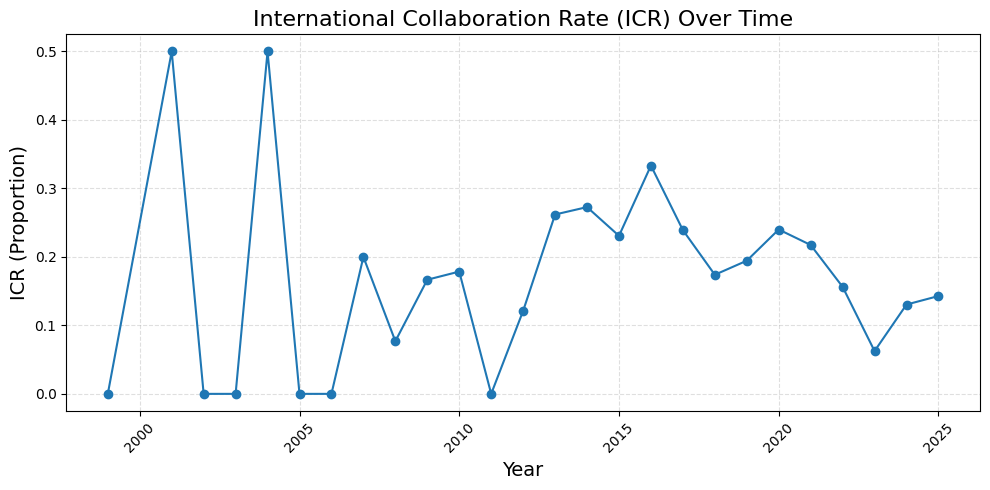

✅ `international_collaboration_rate_over_time.csv` as CSV saved. 


In [12]:
import ast

import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "affiliation_integration_country": "affiliation_country",
    }
)

df["affiliation_country"] = df["affiliation_country"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

icr_df = (
    df.assign(
        is_international=df["affiliation_country"].apply(
            lambda countries: len({c for c in countries if isinstance(c, str) and c.strip()}) >= 2
        )
    )
    .groupby("year", as_index=False)["is_international"]
    .mean()
    .rename(columns={"year": "Year", "is_international": "ICR"})
    .sort_values("Year")
)

overall_icr = icr_df["ICR"].mean() if not icr_df.empty else 0.0
print(f"Overall International Collaboration Rate (ICR): {overall_icr:.3f}")

plt.figure(figsize=(10, 5))
plt.plot(icr_df["Year"], icr_df["ICR"], marker="o")
plt.title("International Collaboration Rate (ICR) Over Time", fontsize=16)
plt.xlabel("Year", fontsize=14)
plt.ylabel("ICR (Proportion)", fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt_savefig(plt, "international_collaboration_rate_over_time.png")
plt.show()
plt.close()

dataframe_to_csv(icr_df, "international_collaboration_rate_over_time.csv")

International publications: 100/544
Overall International Collaboration Rate (ICR): 0.184
Overall International Collaboration Rate (ICR): 18.4%
✅ `international_collaboration_rate_over_time.csv` as CSV saved. 


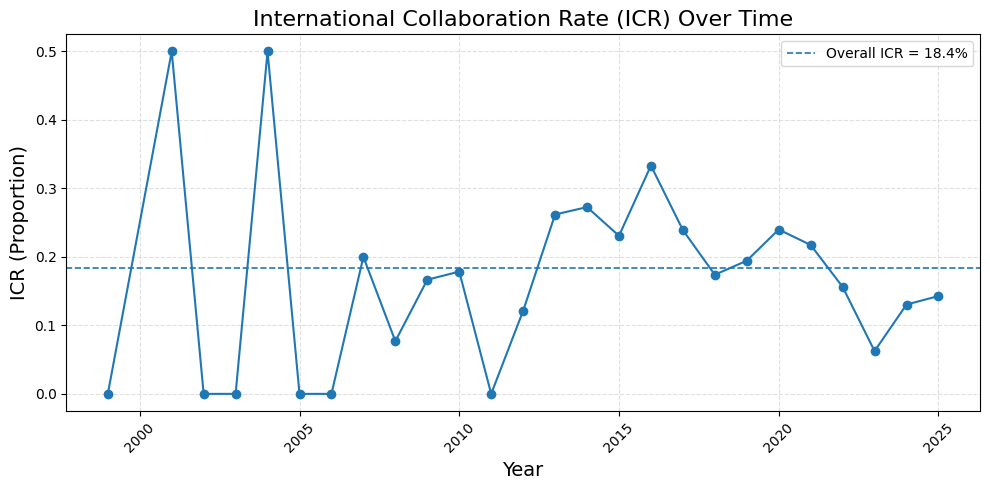

In [18]:
import ast

import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv


# ============================================================
# Load dataset
# ============================================================

df = DATASET().copy()


# ============================================================
# Helper function
# ============================================================

def safe_eval(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]

    value = value.strip()

    if value == "":
        return []

    try:

        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, (tuple, set)):
            return list(parsed)

        return [parsed]

    except (ValueError, SyntaxError):

        return [value]


# ============================================================
# Prepare affiliation-country column
# ============================================================

# Rename only if needed
if (
    "affiliation_country" not in df.columns
    and "affiliation_integration_country" in df.columns
):

    df = df.rename(
        columns={
            "affiliation_integration_country":
                "affiliation_country"
        }
    )


if "affiliation_country" not in df.columns:

    raise ValueError(
        "Column 'affiliation_country' is required "
        "for international collaboration analysis."
    )


df["affiliation_country"] = (
    df["affiliation_country"]
    .apply(safe_eval)
)


# ============================================================
# Clean year
# ============================================================

df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)


df = df.dropna(
    subset=["year"]
).copy()


df["year"] = df["year"].astype(int)


if df.empty:

    raise ValueError(
        "No valid publication-year data available."
    )


# ============================================================
# Count distinct countries per publication
# ============================================================

def count_distinct_countries(countries):

    cleaned_countries = {

        str(country).strip()

        for country in countries

        if (
            pd.notna(country)
            and str(country).strip() != ""
        )

    }

    return len(cleaned_countries)


df["n_countries"] = (
    df["affiliation_country"]
    .apply(count_distinct_countries)
)


# ============================================================
# Define international collaboration
# ============================================================
#
# A publication is internationally collaborative
# if it contains affiliations from >= 2 distinct countries.
#
# ============================================================

df["is_international"] = (
    df["n_countries"] >= 2
)


# ============================================================
# Overall ICR
# ============================================================
#
# CORRECT DEFINITION:
#
# International publications
# --------------------------
# All publications
#
# ============================================================

n_total = len(df)

n_international = int(
    df["is_international"].sum()
)


overall_icr = (
    n_international / n_total
    if n_total > 0
    else 0.0
)


print(
    f"International publications: "
    f"{n_international}/{n_total}"
)

print(
    f"Overall International Collaboration Rate (ICR): "
    f"{overall_icr:.3f}"
)

print(
    f"Overall International Collaboration Rate (ICR): "
    f"{overall_icr * 100:.1f}%"
)


# ============================================================
# Annual ICR
# ============================================================

icr_df = (
    df
    .groupby(
        "year",
        as_index=False
    )
    .agg(

        Total_Publications=(
            "is_international",
            "size"
        ),

        International_Publications=(
            "is_international",
            "sum"
        )

    )
    .rename(
        columns={
            "year": "Year"
        }
    )
    .sort_values("Year")
    .reset_index(drop=True)
)


icr_df["International_Publications"] = (
    icr_df["International_Publications"]
    .astype(int)
)


icr_df["Total_Publications"] = (
    icr_df["Total_Publications"]
    .astype(int)
)


icr_df["ICR"] = (
    icr_df["International_Publications"]
    /
    icr_df["Total_Publications"]
)


icr_df["ICR_Percent"] = (
    icr_df["ICR"] * 100
).round(2)


# ============================================================
# Validation check
# ============================================================
#
# Weighted mean of annual ICR must equal overall ICR.
#
# ============================================================

weighted_icr = (

    (
        icr_df["ICR"]
        *
        icr_df["Total_Publications"]
    ).sum()

    /
    icr_df["Total_Publications"].sum()

)


assert np.isclose(
    weighted_icr,
    overall_icr
), "Overall and weighted annual ICR values do not match."


# ============================================================
# Save table
# ============================================================

dataframe_to_csv(
    icr_df,
    "international_collaboration_rate_over_time.csv"
)


# ============================================================
# Plot
# ============================================================

plt.figure(
    figsize=(10, 5)
)


plt.plot(
    icr_df["Year"],
    icr_df["ICR"],
    marker="o"
)


# Overall corpus-level ICR
plt.axhline(
    y=overall_icr,
    linestyle="--",
    linewidth=1.2,
    label=(
        f"Overall ICR = "
        f"{overall_icr * 100:.1f}%"
    )
)


plt.title(
    "International Collaboration Rate (ICR) Over Time",
    fontsize=16
)


plt.xlabel(
    "Year",
    fontsize=14
)


plt.ylabel(
    "ICR (Proportion)",
    fontsize=14
)


plt.xticks(
    rotation=45
)


plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)


plt.legend()

plt.tight_layout()


plt_savefig(
    plt,
    "international_collaboration_rate_over_time.png"
)


plt.show()

plt.close()

### Country Co-occurrence Network (VOSviewer Visualization)
A co-occurrence network of countries is constructed based on shared authorship, revealing collaboration clusters and international partnerships.

| Parameter | Recommended Value |
|---|---|
| Normalization | Association Strength |
| Attraction | 2 |
| Repulsion | 1 |
| Clustering Resolution | 1.00 |
| Minimum Cluster Size | 5 |
| Merge Small Clusters | On |
| Advanced Parameters | Leave unchanged |
| Edge weight | 1 |
| Node  | 43  |
| Edge  | 113 |
| Clusters  | 6 |



In [ ]:
import ast
import json
import random
from itertools import combinations

import pandas as pd
import pycountry
import networkx as nx

from src.config import OUTPUT_DIR
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv


# ============================================================
# Settings
# ============================================================

MIN_EDGE_WEIGHT = 1
RANDOM_SEED = 42

MATRIX_FILENAME = "country_co_occurrence_matrix.csv"
EDGE_FILENAME = "country_co_occurrence_edges.csv"
NODE_FILENAME = "country_co_occurrence_nodes.csv"
JSON_FILENAME = "vos_viewer_country_co_occurrence.json"


# ============================================================
# Reproducibility
# ============================================================

random.seed(RANDOM_SEED)


# ============================================================
# Load dataset
# ============================================================

df = DATASET().copy()
df = df.reset_index(drop=True)


# ============================================================
# Required column
# ============================================================

if "affiliation_country" not in df.columns:

    if "affiliation_integration_country" in df.columns:

        df = df.rename(
            columns={
                "affiliation_integration_country":
                    "affiliation_country"
            }
        )

    else:

        raise ValueError(
            "Column 'affiliation_country' is required "
            "for country collaboration analysis."
        )


# ============================================================
# Publication identifier
# ============================================================

if "DBUID" in df.columns:

    publication_id = (
        df["DBUID"]
        .astype("string")
        .str.strip()
    )

    missing_id = (
        publication_id.isna()
        | publication_id.eq("")
    )

    df["_publication_id"] = publication_id.astype(object)

    df.loc[
        missing_id,
        "_publication_id"
    ] = [
        f"__row_{i}"
        for i in df.index[missing_id]
    ]

else:

    df["_publication_id"] = [
        f"__row_{i}"
        for i in df.index
    ]


# ============================================================
# Helper: safely parse country values
# ============================================================

def safe_eval_list(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if pd.isna(value):
        return []

    if not isinstance(value, str):
        return [value]

    value = value.strip()

    if value == "":
        return []

    try:

        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, (tuple, set)):
            return list(parsed)

        return [parsed]

    except (ValueError, SyntaxError):

        return [value]


# ============================================================
# Country aliases
# ============================================================

from src.lib_dataset import COUNTRY_ALIASES

# ============================================================
# Friendly display names
# ============================================================

from src.lib_dataset import DISPLAY_NAMES

# ============================================================
# Resolve country
# ============================================================

def resolve_country(country):

    if pd.isna(country):
        return None

    country = str(country).strip()

    if country == "":
        return None

    # Collapse repeated whitespace
    country = " ".join(
        country.split()
    )

    lookup_name = COUNTRY_ALIASES.get(
        country.lower(),
        country
    )

    try:

        matched = pycountry.countries.lookup(
            lookup_name
        )

        iso3 = matched.alpha_3

        display_name = DISPLAY_NAMES.get(
            iso3,
            matched.name
        )

        return {
            "country": display_name,
            "iso3": iso3,
            "original_country": country,
        }

    except LookupError:

        return {
            "country": country,
            "iso3": None,
            "original_country": country,
        }


# ============================================================
# Parse affiliation-country lists
# ============================================================

df["affiliation_country"] = (
    df["affiliation_country"]
    .apply(safe_eval_list)
)


# ============================================================
# Explode countries
# ============================================================

country_long = (
    df[
        [
            "_publication_id",
            "affiliation_country"
        ]
    ]
    .explode("affiliation_country")
    .copy()
)


country_long["affiliation_country"] = (
    country_long["affiliation_country"]
    .astype("string")
    .str.strip()
)


country_long = country_long[
    country_long["affiliation_country"].notna()
].copy()


country_long = country_long[
    country_long["affiliation_country"] != ""
].copy()


if country_long.empty:

    raise ValueError(
        "No valid affiliation-country data were found."
    )


# ============================================================
# Resolve country names and ISO-3
# ============================================================

resolved = (
    country_long["affiliation_country"]
    .apply(resolve_country)
)


country_long["Country"] = resolved.apply(
    lambda x:
        x["country"]
        if x is not None
        else None
)


country_long["ISO3"] = resolved.apply(
    lambda x:
        x["iso3"]
        if x is not None
        else None
)


# ============================================================
# Report unresolved country names
# ============================================================

unresolved_df = (
    country_long[
        country_long["ISO3"].isna()
    ][
        ["affiliation_country"]
    ]
    .drop_duplicates()
    .rename(
        columns={
            "affiliation_country":
                "Unresolved_Country_Name"
        }
    )
    .sort_values(
        "Unresolved_Country_Name"
    )
    .reset_index(drop=True)
)


if not unresolved_df.empty:

    print(
        "\nWARNING: The following country names "
        "could not be converted to ISO-3:"
    )

    print(
        unresolved_df.to_string(
            index=False
        )
    )

    dataframe_to_csv(
        unresolved_df,
        "unresolved_country_names_network.csv"
    )


# ============================================================
# Keep resolved countries only
# ============================================================

country_long = (
    country_long
    .dropna(
        subset=[
            "Country",
            "ISO3"
        ]
    )
    .copy()
)


if country_long.empty:

    raise ValueError(
        "No country names could be resolved "
        "to valid ISO-3 codes."
    )


# ============================================================
# Remove duplicate country occurrences within publication
# ============================================================
#
# Example:
#
# ["Germany", "Germany", "Austria"]
#
# becomes:
#
# ["Germany", "Austria"]
#
# ============================================================

country_long = (
    country_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "ISO3"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Build publication-level country lists
# ============================================================

publication_countries = (
    country_long
    .groupby(
        "_publication_id"
    )
    .agg(
        Countries=(
            "Country",
            lambda x:
                sorted(set(x))
        ),
        ISO3_List=(
            "ISO3",
            lambda x:
                sorted(set(x))
        )
    )
    .reset_index()
)


# ============================================================
# Country publication frequency
# ============================================================

country_frequency_df = (
    country_long
    .groupby(
        [
            "ISO3",
            "Country"
        ],
        as_index=False
    )
    .agg(
        Publications=(
            "_publication_id",
            "nunique"
        )
    )
    .sort_values(
        [
            "Publications",
            "Country"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Build co-occurrence edge counts manually
# ============================================================
#
# Each edge weight equals the number of publications in which
# the two countries co-occur.
#
# Only distinct country pairs within each publication are used.
#
# ============================================================

edge_counter = {}


for _, row in publication_countries.iterrows():

    countries = row["Countries"]

    if len(countries) < 2:
        continue

    for country_a, country_b in combinations(
        countries,
        2
    ):

        pair = tuple(
            sorted(
                [
                    country_a,
                    country_b
                ]
            )
        )

        edge_counter[pair] = (
            edge_counter.get(
                pair,
                0
            )
            + 1
        )


# ============================================================
# Edge dataframe
# ============================================================

edge_rows = [

    {
        "Source": source,
        "Target": target,
        "Weight": weight,
    }

    for (
        source,
        target
    ), weight
    in edge_counter.items()

]


edge_df = pd.DataFrame(
    edge_rows
)


if edge_df.empty:

    raise ValueError(
        "No international country co-occurrence edges "
        "could be generated."
    )


edge_df = (
    edge_df
    .sort_values(
        [
            "Weight",
            "Source",
            "Target"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Save all raw collaboration edges
# ============================================================

dataframe_to_csv(
    edge_df,
    EDGE_FILENAME
)


# ============================================================
# Apply minimum edge threshold
# ============================================================

filtered_edge_df = edge_df[
    edge_df["Weight"]
    >= MIN_EDGE_WEIGHT
].copy()


if filtered_edge_df.empty:

    raise ValueError(
        "No country collaboration edges remained after "
        f"applying MIN_EDGE_WEIGHT={MIN_EDGE_WEIGHT}."
    )


# ============================================================
# Build NetworkX graph
# ============================================================

G = nx.Graph()


# Add nodes
for _, row in country_frequency_df.iterrows():

    G.add_node(

        row["Country"],

        label=row["Country"],

        publications=int(
            row["Publications"]
        ),

        iso3=row["ISO3"],
    )


# Add filtered edges
for _, row in filtered_edge_df.iterrows():

    G.add_edge(

        row["Source"],

        row["Target"],

        weight=int(
            row["Weight"]
        ),

    )


# ============================================================
# Remove isolated nodes
# ============================================================
#
# For the collaboration network we retain only nodes having
# at least one edge that survived the threshold.
#
# ============================================================

isolates = list(
    nx.isolates(G)
)


G.remove_nodes_from(
    isolates
)


if G.number_of_nodes() == 0:

    raise ValueError(
        "No connected countries remained after edge filtering."
    )


# ============================================================
# Node statistics
# ============================================================

node_rows = []


for node in G.nodes():

    node_rows.append(
        {

            "Country":
                node,

            "ISO3":
                G.nodes[node].get(
                    "iso3"
                ),

            "Publications":
                G.nodes[node].get(
                    "publications",
                    0
                ),

            "Degree":
                G.degree(node),

            "Weighted_Degree":
                sum(
                    G[node][neighbor].get(
                        "weight",
                        0
                    )
                    for neighbor
                    in G.neighbors(node)
                ),
        }
    )


node_df = pd.DataFrame(
    node_rows
)


node_df = (
    node_df
    .sort_values(
        [
            "Weighted_Degree",
            "Publications"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


dataframe_to_csv(
    node_df,
    NODE_FILENAME
)


# ============================================================
# Build full co-occurrence matrix
# ============================================================
#
# Rows and columns are countries.
# Off-diagonal cells contain number of shared publications.
# Diagonal contains each country's publication frequency.
#
# ============================================================

all_countries = (
    country_frequency_df[
        "Country"
    ]
    .tolist()
)


co_occurrence_matrix = pd.DataFrame(

    0,

    index=all_countries,

    columns=all_countries,

    dtype=int
)


# Diagonal = publication frequency
publication_count_map = dict(
    zip(
        country_frequency_df["Country"],
        country_frequency_df["Publications"]
    )
)


for country in all_countries:

    co_occurrence_matrix.loc[
        country,
        country
    ] = int(
        publication_count_map[
            country
        ]
    )


# Off-diagonal = country pair co-occurrence
for _, row in edge_df.iterrows():

    source = row["Source"]
    target = row["Target"]
    weight = int(
        row["Weight"]
    )

    co_occurrence_matrix.loc[
        source,
        target
    ] = weight

    co_occurrence_matrix.loc[
        target,
        source
    ] = weight


# ============================================================
# Save matrix
# ============================================================

matrix_export = (
    co_occurrence_matrix
    .reset_index()
    .rename(
        columns={
            "index":
                "Country"
        }
    )
)


dataframe_to_csv(
    matrix_export,
    MATRIX_FILENAME
)


# ============================================================
# Graph layout
# ============================================================
#
# Random coordinates are retained only to match the expected
# JSON structure, but a fixed seed makes them reproducible.
#
# VOSviewer can still optimize/recalculate the layout.
#
# ============================================================

graph_data = {

    "network": {

        "items": [

            {

                "id":
                    node,

                "label":
                    node,

                "x":
                    round(
                        random.uniform(
                            -1.1515,
                            0.2000
                        ),
                        4
                    ),

                "y":
                    round(
                        random.uniform(
                            -1.1515,
                            0.2000
                        ),
                        4
                    ),

                "weight":
                    int(
                        G.nodes[node].get(
                            "publications",
                            0
                        )
                    ),

            }

            for node
            in G.nodes()

        ],

        "links": [

            {

                "source_id":
                    source,

                "target_id":
                    target,

                "strength":
                    int(
                        data["weight"]
                    ),

            }

            for (
                source,
                target,
                data
            )
            in G.edges(
                data=True
            )

        ],

    }

}


# ============================================================
# Save JSON
# ============================================================

json_path = (
    OUTPUT_DIR
    / JSON_FILENAME
)


with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        graph_data,
        f,
        indent=4,
        ensure_ascii=False
    )


print(
    f"`{JSON_FILENAME}` saved."
)


# ============================================================
# Summary
# ============================================================

print(
    "\n=== Country Collaboration Network Summary ==="
)


print(
    f"Countries identified before filtering: "
    f"{len(country_frequency_df)}"
)


print(
    f"International collaboration pairs before filtering: "
    f"{len(edge_df)}"
)


print(
    f"Minimum edge weight: "
    f"{MIN_EDGE_WEIGHT}"
)


print(
    f"Collaboration pairs after filtering: "
    f"{len(filtered_edge_df)}"
)


print(
    f"Connected countries in final network: "
    f"{G.number_of_nodes()}"
)


print(
    f"Edges in final network: "
    f"{G.number_of_edges()}"
)


# ============================================================
# Strongest collaborations
# ============================================================

print(
    "\nStrongest country collaborations:"
)


print(
    filtered_edge_df
    .head(20)
    .to_string(
        index=False
    )
)

✅ `country_co_occurrence_edges.csv` as CSV saved. 
✅ `country_co_occurrence_nodes.csv` as CSV saved. 
✅ `country_co_occurrence_matrix.csv` as CSV saved. 
`vos_viewer_country_co_occurrence.json` saved.

=== Country Collaboration Network Summary ===
Countries identified before filtering: 61
International collaboration pairs before filtering: 115
Minimum edge weight: 1
Collaboration pairs after filtering: 115
Connected countries in final network: 47
Edges in final network: 115

Strongest country collaborations:
        Source         Target  Weight
        Brazil    Netherlands       7
         China    Netherlands       7
United Kingdom  United States       6
        Brazil         Sweden       4
         India          Japan       4
        Brazil       Portugal       3
        Brazil  United States       3
         China    New Zealand       3
         China  United States       3
       Germany    Switzerland       3
        Norway          Spain       3
        Norway  United States 

![vos_viewer_country_co_occurrence](./output/vos_viewer_country_co_occurrence.png)

## Author and Journal Analysis

### Most Influential Authors
Authors are ranked based on total citations and publication counts to identify key contributors and leaders in the field.

✅ `top_10_authors_in_research_impact.csv` as CSV saved. 


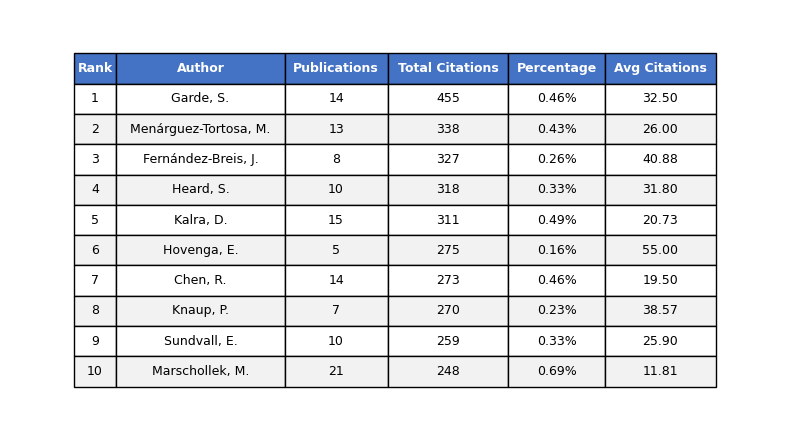

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

authors_expanded = df.explode("authors").dropna(subset=["authors"]).copy()
authors_expanded["citation_count"] = pd.to_numeric(
    authors_expanded["citation_count"], errors="coerce"
).fillna(0)

author_stats = (
    authors_expanded.groupby("authors", as_index=False)
    .agg(
        Publications=("authors", "size"),
        Total_Citations=("citation_count", "sum"),
    )
    .sort_values("Total_Citations", ascending=False)
    .reset_index(drop=True)
)

total_publications = author_stats["Publications"].sum()
author_stats["Percentage"] = (
    author_stats["Publications"] / total_publications * 100
).round(2)
author_stats["Avg_Citations"] = (
    author_stats["Total_Citations"] / author_stats["Publications"]
).round(2)

dataframe_to_csv(author_stats, "top_10_authors_in_research_impact.csv")

top_10_authors = author_stats.head(10).copy()
top_10_authors.insert(0, "Rank", range(1, len(top_10_authors) + 1))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axis("off")

display_df = top_10_authors.rename(
    columns={
        "authors": "Author",
        "Total_Citations": "Total Citations",
        "Avg_Citations": "Avg Citations",
    }
).copy()

display_df["Total Citations"] = display_df["Total Citations"].astype(int)
display_df["Publications"] = display_df["Publications"].astype(int)
display_df["Percentage"] = display_df["Percentage"].map(lambda x: f"{x:.2f}%")
display_df["Avg Citations"] = display_df["Avg Citations"].map(lambda x: f"{x:.2f}")

table = ax.table(
    cellText=display_df.values,
    colLabels=display_df.columns,
    loc="center",
    cellLoc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.auto_set_column_width(col=list(range(len(display_df.columns))))
table.scale(1, 1.5)

for j in range(len(display_df.columns)):
    cell = table[(0, j)]
    cell.set_facecolor("#4472C4")
    cell.set_text_props(color="white", weight="bold")

for i in range(1, len(display_df) + 1):
    for j in range(len(display_df.columns)):
        table[(i, j)].set_facecolor("#F2F2F2" if i % 2 == 0 else "white")

plt.tight_layout()
plt_savefig(plt, "top_10_authors_in_research_impact.png")
plt.show()

### Lotka’s Law of Scientific Productivity
Lotka’s Law of Scientific Productivity describes the highly skewed distribution of publication output among authors within a research field. It states that the number of authors publishing $ n $ papers is inversely proportional to $ n^2 $, such that a small minority of highly productive authors account for a large share of the total literature, while most authors publish only one or a few papers. In its generalized form, Lotka’s Law can be expressed as:

$$
A_n = A_1 , n^{-\alpha}
$$

where $ A_n $ denotes the number of authors who have published exactly $ n $ papers, $ A_1 $ is the number of authors with a single publication, and $ \alpha $ is an exponent typically close to 2 in empirical studies. Applying Lotka’s Law allows us to model and evaluate the concentration of scientific productivity, identify core groups of prolific contributors, and compare authorship patterns across different disciplines or datasets.

Total unique authors: 1642
   n_papers  n_authors  Author_Share_%  Cumulative_Authors  Cumulative_Share_%
0         1       1173           71.44                1173               71.44
1         2        217           13.22                1390               84.65
2         3         95            5.79                1485               90.44
3         4         42            2.56                1527               93.00
4         5         23            1.40                1550               94.40
Estimated Lotka parameters:
  A_1 ≈ 1076.699
  alpha ≈ 2.241


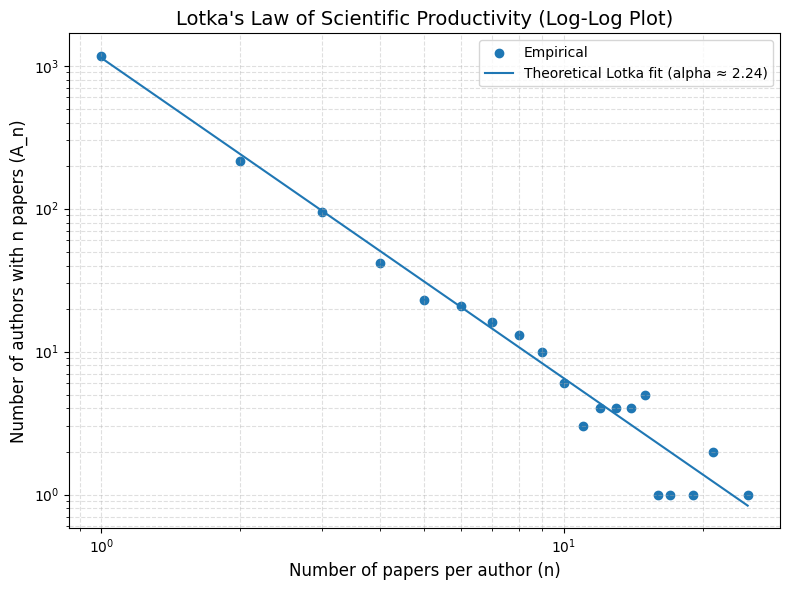

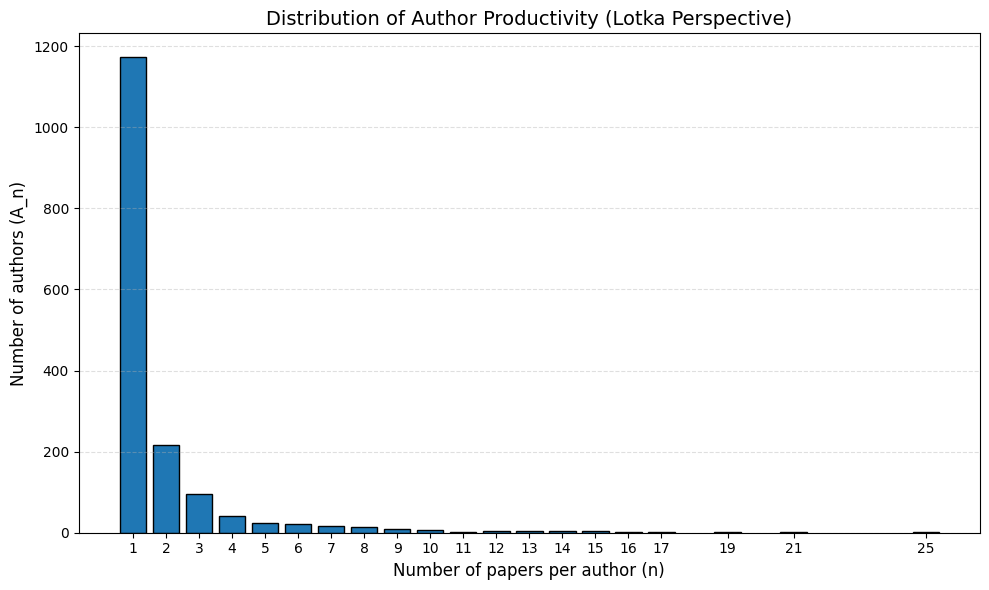

✅ `lotkas_law_author_productivity_distribution.csv` as CSV saved. 


In [10]:
import ast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

YEAR_MIN = None
YEAR_MAX = None
MIN_PAPERS_FOR_FIT = 1

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df["authors"] = df["authors"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]

if df.empty:
    raise ValueError("No articles available after year filtering for Lotka analysis.")

df_auth = df.explode("authors").dropna(subset=["authors"]).copy()
df_auth["authors"] = df_auth["authors"].astype(str).str.strip()
df_auth = df_auth[df_auth["authors"] != ""]

if df_auth.empty:
    raise ValueError("No author data available after exploding 'authors' for Lotka analysis.")

author_productivity = (
    df_auth.groupby("authors", as_index=False)
    .size()
    .rename(columns={"size": "n_papers"})
)

lotka_dist = (
    author_productivity["n_papers"]
    .value_counts()
    .sort_index()
    .rename_axis("n_papers")
    .reset_index(name="n_authors")
)

total_authors = lotka_dist["n_authors"].sum()
lotka_dist["Author_Share_%"] = (100 * lotka_dist["n_authors"] / total_authors).round(2)
lotka_dist["Cumulative_Authors"] = lotka_dist["n_authors"].cumsum()
lotka_dist["Cumulative_Share_%"] = (
    100 * lotka_dist["Cumulative_Authors"] / total_authors
).round(2)

print(f"Total unique authors: {total_authors}")
print(lotka_dist.head())

fit_data = lotka_dist[
    (lotka_dist["n_papers"] >= MIN_PAPERS_FOR_FIT) & (lotka_dist["n_authors"] > 0)
].copy()

if len(fit_data) < 2:
    raise ValueError("Not enough data points to fit Lotka's Law.")

x = np.log(fit_data["n_papers"].to_numpy())
y = np.log(fit_data["n_authors"].to_numpy())

b, a = np.polyfit(x, y, 1)
alpha_est = -b
a1_est = np.exp(a)

print("Estimated Lotka parameters:")
print(f"  A_1 ≈ {a1_est:.3f}")
print(f"  alpha ≈ {alpha_est:.3f}")

n_values = lotka_dist["n_papers"].to_numpy()
lotka_theoretical = a1_est * (n_values ** (-alpha_est))
lotka_dist["Lotka_Theoretical"] = lotka_theoretical * (
    total_authors / lotka_theoretical.sum()
)

plt.figure(figsize=(8, 6))
plt.scatter(
    lotka_dist["n_papers"],
    lotka_dist["n_authors"],
    label="Empirical",
    marker="o",
)
plt.plot(
    lotka_dist["n_papers"],
    lotka_dist["Lotka_Theoretical"],
    label=f"Theoretical Lotka fit (alpha ≈ {alpha_est:.2f})",
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of papers per author (n)", fontsize=12)
plt.ylabel("Number of authors with n papers (A_n)", fontsize=12)
plt.title("Lotka's Law of Scientific Productivity (Log-Log Plot)", fontsize=14)
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt_savefig(plt, "lotkas_law_loglog_plot.png")
plt.show()
plt.close()

plt.figure(figsize=(10, 6))
plt.bar(
    lotka_dist["n_papers"],
    lotka_dist["n_authors"],
    edgecolor="black",
)
plt.xlabel("Number of papers per author (n)", fontsize=12)
plt.ylabel("Number of authors (A_n)", fontsize=12)
plt.title("Distribution of Author Productivity (Lotka Perspective)", fontsize=14)
plt.xticks(lotka_dist["n_papers"])
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt_savefig(plt, "lotkas_law_productivity_distribution.png")
plt.show()
plt.close()

dataframe_to_csv(lotka_dist, "lotkas_law_author_productivity_distribution.csv")

### Goodness-of-Fit Evaluation of Lotka Model
Model fit is evaluated using statistical measures including R², RMSE, MAE, and chi-square test to assess how well empirical data aligns with Lotka’s Law.

In [16]:
obs = lotka_dist["n_authors"].astype(float).to_numpy()
exp_ = lotka_dist["Lotka_Theoretical"].astype(float).to_numpy()

y_hat = a + b * x
ss_res = np.sum((y - y_hat) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r2_loglog = 1 - ss_res / ss_tot if ss_tot != 0 else 0.0

rmse = np.sqrt(np.mean((obs - exp_) ** 2))
mae = np.mean(np.abs(obs - exp_))

mask = exp_ > 0
obs_cs = obs[mask]
exp_cs = exp_[mask]

chi2 = np.sum((obs_cs - exp_cs) ** 2 / exp_cs)
df_chi2 = max(len(obs_cs) - 3, 1)

try:
    from scipy.stats import chi2 as chi2_dist

    p_value = 1 - chi2_dist.cdf(chi2, df_chi2)
except Exception:
    p_value = None

print("Goodness-of-fit:")
print(f"  R^2 (log-log) = {r2_loglog:.4f}")
print(f"  RMSE (linear) = {rmse:.3f}")
print(f"  MAE (linear) = {mae:.3f}")
print(f"  Chi-square = {chi2:.3f} (df={df_chi2})")
if p_value is not None:
    print(f"  Chi-square p = {p_value:.4g}")

gof_text = (
    f"R² (log-log) = {r2_loglog:.3f}, "
    f"RMSE = {rmse:.2f}, MAE = {mae:.2f}, "
    + (
        f"χ²({df_chi2}) = {chi2:.2f}, p = {p_value:.3g}"
        if p_value is not None
        else f"χ²({df_chi2}) = {chi2:.2f}"
    )
)

print("\n[[lotka_goodness_of_fit]] replacement:")
print(gof_text)

Goodness-of-fit:
  R^2 (log-log) = 0.9626
  RMSE (linear) = 10.214
  MAE (linear) = 4.770
  Chi-square = 13.433 (df=17)
  Chi-square p = 0.7068

[[lotka_goodness_of_fit]] replacement:
R² (log-log) = 0.963, RMSE = 10.21, MAE = 4.77, χ²(17) = 13.43, p = 0.707


### Top Journals by Citation Performance
Journals are ranked by average citations per article (CPA), providing insight into publication venues with the highest impact.

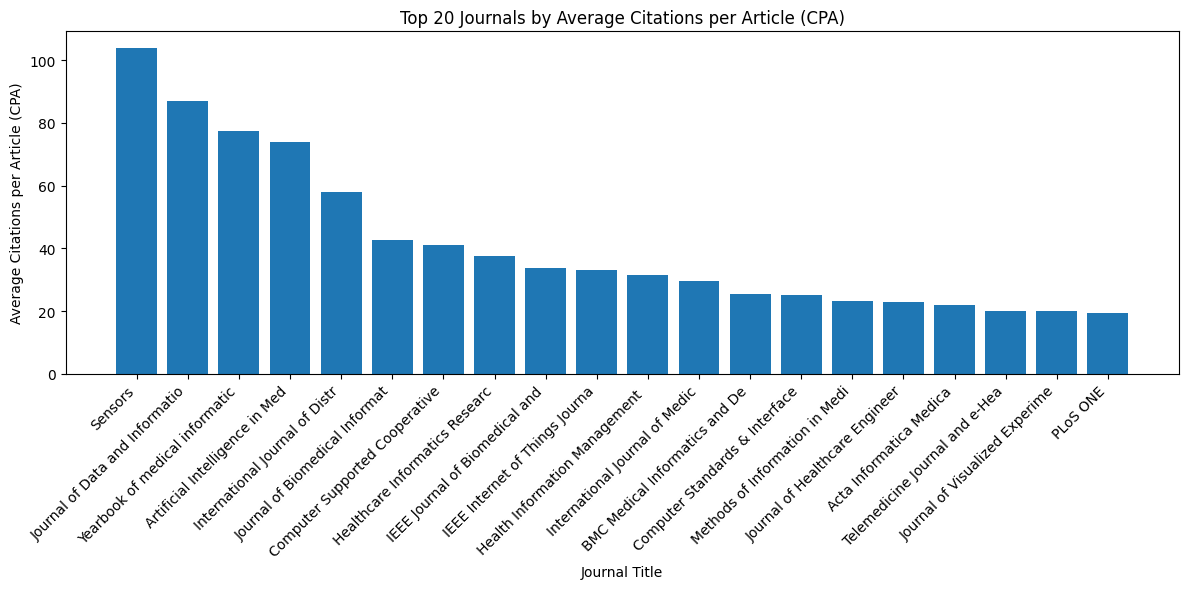

✅ `top_journal_by_cpa.csv` as CSV saved. 


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

top = 20

df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

journal_stats = (
    df.groupby("journal_title", as_index=False)
    .agg(
        Total_Citations=("citation_count", "sum"),
        Publications=("journal_title", "size"),
    )
)

journal_stats["CPA"] = (
    journal_stats["Total_Citations"] / journal_stats["Publications"]
).round(2)

journal_stats_sorted = journal_stats.sort_values("CPA", ascending=False).reset_index(drop=True)
top_journals = journal_stats_sorted.head(top).copy()
top_journals["journal_title"] = top_journals["journal_title"].str.slice(0, 30)
title = f"Top {top} Journals by Average Citations per Article (CPA)"

plt.figure(figsize=(12, 6))
plt.bar(top_journals["journal_title"], top_journals["CPA"])
plt.xlabel("Journal Title")
plt.ylabel("Average Citations per Article (CPA)")
plt.title(title)
plt.xticks(rotation=45, ha="right")
plt.subplots_adjust(bottom=0.35)


plt_savefig(plt, "top_journal_by_cpa.png")
plt.show()

dataframe_to_csv(top_journals, "top_journal_by_cpa.csv")

### Top 10 Journal by publications

✅ `journal_list.csv` as CSV saved. 


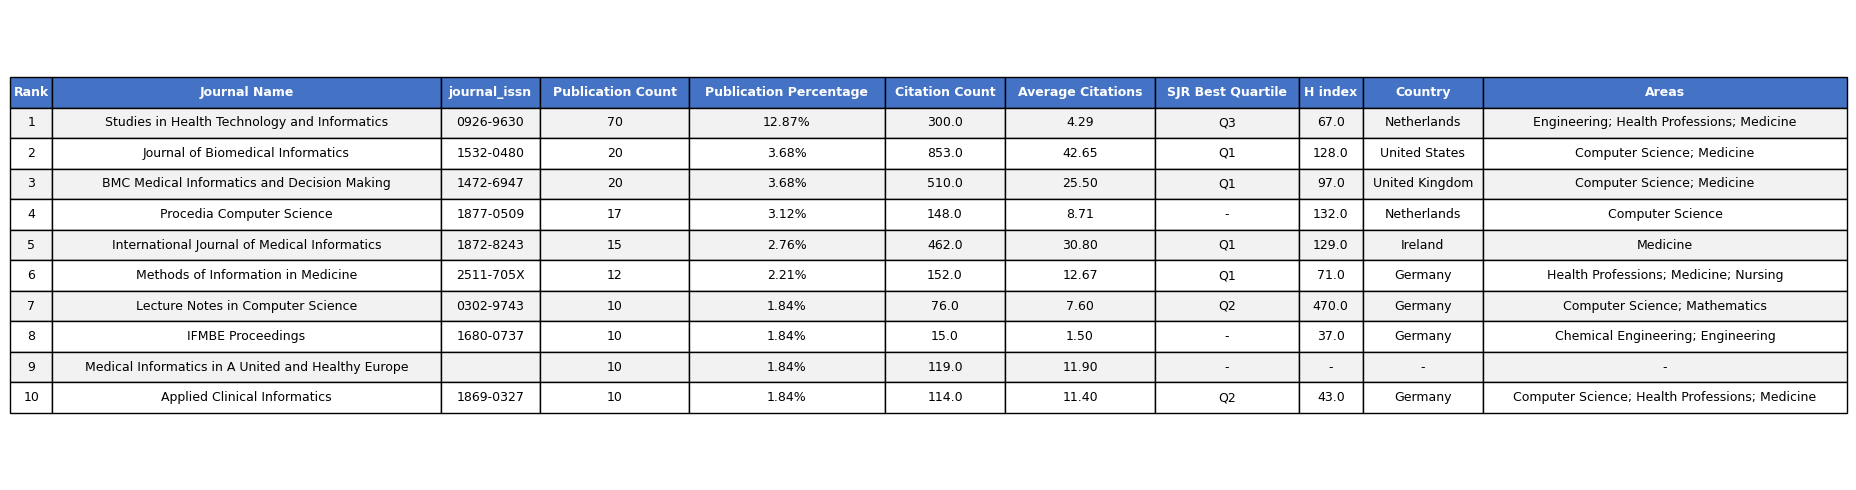


Top 10 Journal by publications
| Journal Name | journal_issn | Publication Count | Citation Count | Average Citations | SJR Best Quartile | H index | Country | Areas | Rank | Publication Percentage |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Studies in Health Technology and Informatics | 0926-9630 | 70 | 300.0 | 4.29 | Q3 | 67.0 | Netherlands | Engineering; Health Professions; Medicine | 1 | 12.87 |
| Journal of Biomedical Informatics | 1532-0480 | 20 | 853.0 | 42.65 | Q1 | 128.0 | United States | Computer Science; Medicine | 2 | 3.68 |
| BMC Medical Informatics and Decision Making | 1472-6947 | 20 | 510.0 | 25.5 | Q1 | 97.0 | United Kingdom | Computer Science; Medicine | 3 | 3.68 |
| Procedia Computer Science | 1877-0509 | 17 | 148.0 | 8.71 | - | 132.0 | Netherlands | Computer Science | 4 | 3.12 |
| International Journal of Medical Informatics | 1872-8243 | 15 | 462.0 | 30.8 | Q1 | 129.0 | Ireland | Medicine | 5 | 2.76 |
| Methods of Information in Medicin

'| Journal Name | journal_issn | Publication Count | Citation Count | Average Citations | SJR Best Quartile | H index | Country | Areas | Rank | Publication Percentage |\n| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |\n| Studies in Health Technology and Informatics | 0926-9630 | 70 | 300.0 | 4.29 | Q3 | 67.0 | Netherlands | Engineering; Health Professions; Medicine | 1 | 12.87 |\n| Journal of Biomedical Informatics | 1532-0480 | 20 | 853.0 | 42.65 | Q1 | 128.0 | United States | Computer Science; Medicine | 2 | 3.68 |\n| BMC Medical Informatics and Decision Making | 1472-6947 | 20 | 510.0 | 25.5 | Q1 | 97.0 | United Kingdom | Computer Science; Medicine | 3 | 3.68 |\n| Procedia Computer Science | 1877-0509 | 17 | 148.0 | 8.71 | - | 132.0 | Netherlands | Computer Science | 4 | 3.12 |\n| International Journal of Medical Informatics | 1872-8243 | 15 | 462.0 | 30.8 | Q1 | 129.0 | Ireland | Medicine | 5 | 2.76 |\n| Methods of Information in Medicine | 2511-705X | 12 | 152

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from src.config import DATA_DIR
from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv
from src.lib_visualization import dataframe_to_markdown

df = DATASET()

# ---------------------------------------------------------------------
# Create the journal-level working DataFrame.
#
# journal_title is the cleaned/enriched journal title.
# journal_issn contains the normalized and canonicalized ISSN.
# ---------------------------------------------------------------------
new_df = pd.DataFrame({
    'Journal Name': df['journal_title'],
    'journal_issn': df['journal_issn'],
    'Publication Count': 1,
    'Citation Count': df['citation_count']
})


# ---------------------------------------------------------------------
# Create a normalized title key to be used only when ISSN is unavailable.
#
# This prevents minor capitalization and whitespace differences from
# splitting the same journal into separate groups.
# ---------------------------------------------------------------------
new_df['journal_title_key'] = (
    new_df['Journal Name']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
)


# ---------------------------------------------------------------------
# Create a journal identity key.
#
# Priority:
#   1. Canonical ISSN, when available
#   2. Normalized journal title, when ISSN is unavailable
#
# Prefixes are used to keep ISSN-based and title-based identities
# explicitly separate.
# ---------------------------------------------------------------------
valid_issn = (
    new_df['journal_issn'].notna()
    & (new_df['journal_issn'].astype(str).str.strip() != '')
)

new_df['journal_key'] = np.where(
    valid_issn,
    'ISSN:' + new_df['journal_issn'].fillna('').astype(str),
    'TITLE:' + new_df['journal_title_key']
)


# ---------------------------------------------------------------------
# Aggregate publications by the resolved journal identity.
#
# Journals sharing the same canonical ISSN are merged even if their
# original titles differ in capitalization or formatting.
# Journals without an ISSN remain distinguishable by normalized title.
# ---------------------------------------------------------------------
result_df = (
    new_df
    .groupby('journal_key', dropna=False)
    .agg({
        'Journal Name': 'first',
        'journal_issn': 'first',
        'Publication Count': 'sum',
        'Citation Count': 'sum'
    })
    .reset_index(drop=True)
)


# ---------------------------------------------------------------------
# Calculate average citations per publication.
# ---------------------------------------------------------------------
result_df['Average Citations'] = (
    result_df['Citation Count']
    / result_df['Publication Count']
).round(2)


# ---------------------------------------------------------------------
# Rank journals by total citation count.
# ---------------------------------------------------------------------
result_df['Rank'] = (
    result_df['Citation Count']
    .rank(method='dense', ascending=False)
    .astype(int)
)


# ---------------------------------------------------------------------
# Reorder columns.
# ---------------------------------------------------------------------
result_df = result_df[
    [
        'Rank',
        'Journal Name',
        'journal_issn',
        'Publication Count',
        'Citation Count',
        'Average Citations'
    ]
]


result_df = (
    result_df
    .sort_values('Rank')
    .reset_index(drop=True)
)

# ---------------------------------------------------------------------
# Read the normalized Scimago dataset.
# ---------------------------------------------------------------------
scimagojr_df = pd.read_csv(
    DATA_DIR / 'scimagojr 2023_normal_issn.csv'
)


# ---------------------------------------------------------------------
# Merge journal-level publication statistics with Scimago metadata.
# ---------------------------------------------------------------------
rows_before_merge = len(result_df)

merged_df = pd.merge(
    result_df,
    scimagojr_df,
    left_on='journal_issn',
    right_on='normal_issn',
    how='left',
    validate='m:1'
)

assert len(merged_df) == rows_before_merge, (
    f"Unexpected row count change after Scimago merge: "
    f"{rows_before_merge} -> {len(merged_df)}"
)


# Remove the redundant Scimago ISSN column.
merged_df = merged_df.drop(
    'normal_issn',
    axis=1
)


# ---------------------------------------------------------------------
# Select and reorder columns for the final journal table.
# ---------------------------------------------------------------------
column_order = [
    'Journal Name',
    'journal_issn',
    'Publication Count',
    'Citation Count',
    'Average Citations',
    'SJR Best Quartile',
    'H index',
    'Country',
    'Areas'
]

merged_df = merged_df[column_order]


# ---------------------------------------------------------------------
# Replace missing Scimago metadata with a dash for presentation.
# ---------------------------------------------------------------------
for col in [
    'SJR Best Quartile',
    'H index',
    'Country',
    'Areas'
]:
    merged_df[col] = merged_df[col].fillna('-')


# ---------------------------------------------------------------------
# Save the complete journal-level dataset.
# ---------------------------------------------------------------------
dataframe_to_csv(
    merged_df,
    "journal_list.csv"
)


# ---------------------------------------------------------------------
# Basic validation.
# ---------------------------------------------------------------------
if merged_df.empty:
    print("The dataframe is empty. No table can be created.")


required_columns = [
    'Publication Count',
    'Journal Name',
    'journal_issn',
    'Citation Count',
    'Average Citations',
    'SJR Best Quartile',
    'H index',
    'Country',
    'Areas'
]

if not all(
    col in merged_df.columns
    for col in required_columns
):
    print("Some required columns are missing from the dataframe.")


# ---------------------------------------------------------------------
# Select the ten most productive journals.
# ---------------------------------------------------------------------
top_10 = (
    merged_df
    .sort_values(
        'Publication Count',
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


# Re-rank journals according to publication productivity.
top_10['Rank'] = range(
    1,
    len(top_10) + 1
)


# ---------------------------------------------------------------------
# Calculate each journal's share of all publications.
# ---------------------------------------------------------------------
total_publications = merged_df[
    'Publication Count'
].sum()

top_10['Publication Percentage'] = (
    top_10['Publication Count']
    / total_publications
    * 100
).round(2)


# ---------------------------------------------------------------------
# Prepare columns for the final table.
# ---------------------------------------------------------------------
columns = [
    'Rank',
    'Journal Name',
    'journal_issn',
    'Publication Count',
    'Publication Percentage',
    'Citation Count',
    'Average Citations',
    'SJR Best Quartile',
    'H index',
    'Country',
    'Areas'
]

data = [
    top_10[col].tolist()
    for col in columns
]


# ---------------------------------------------------------------------
# Format values for presentation.
# ---------------------------------------------------------------------
data[4] = [
    f"{x:.2f}%"
    for x in data[4]
]

data[3] = [
    f"{x:,}"
    for x in data[3]
]

data[5] = [
    f"{x:,}"
    for x in data[5]
]

data[6] = [
    f"{x:.2f}"
    for x in data[6]
]


# ---------------------------------------------------------------------
# Create the table figure.
# ---------------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(18, 5)
)

ax.axis('off')


table = ax.table(
    cellText=list(zip(*data)),
    colLabels=columns,
    loc='center',
    cellLoc='center'
)


# Set font size.
table.auto_set_font_size(False)
table.set_fontsize(9)


# Adjust column widths and row heights.
table.auto_set_column_width(
    col=list(range(len(columns)))
)

table.scale(1, 1.5)


# ---------------------------------------------------------------------
# Style the header.
# ---------------------------------------------------------------------
for j in range(len(columns)):
    cell = table._cells[(0, j)]
    cell.set_facecolor('#4472C4')
    cell.set_text_props(
        color='white',
        weight='bold'
    )


# ---------------------------------------------------------------------
# Apply alternating row shading.
# ---------------------------------------------------------------------
for i in range(1, len(top_10) + 1):
    for j in range(len(columns)):
        cell = table._cells[(i, j)]
        cell.set_facecolor(
            '#F2F2F2'
            if i % 2
            else 'white'
        )


# ---------------------------------------------------------------------
# Save the journal productivity table.
# ---------------------------------------------------------------------
plt_savefig(
    plt,
    "top_10_journal_by_publications.png"
)


# ---------------------------------------------------------------------
# Export Markdown version.
# ---------------------------------------------------------------------
t = dataframe_to_markdown(
    top_10,
    table_name="Top 10 Journal by publications"
)

### Journal Productivity vs. Citation Impact
This analysis compares journal output volume with citation performance to identify high-impact publication outlets.

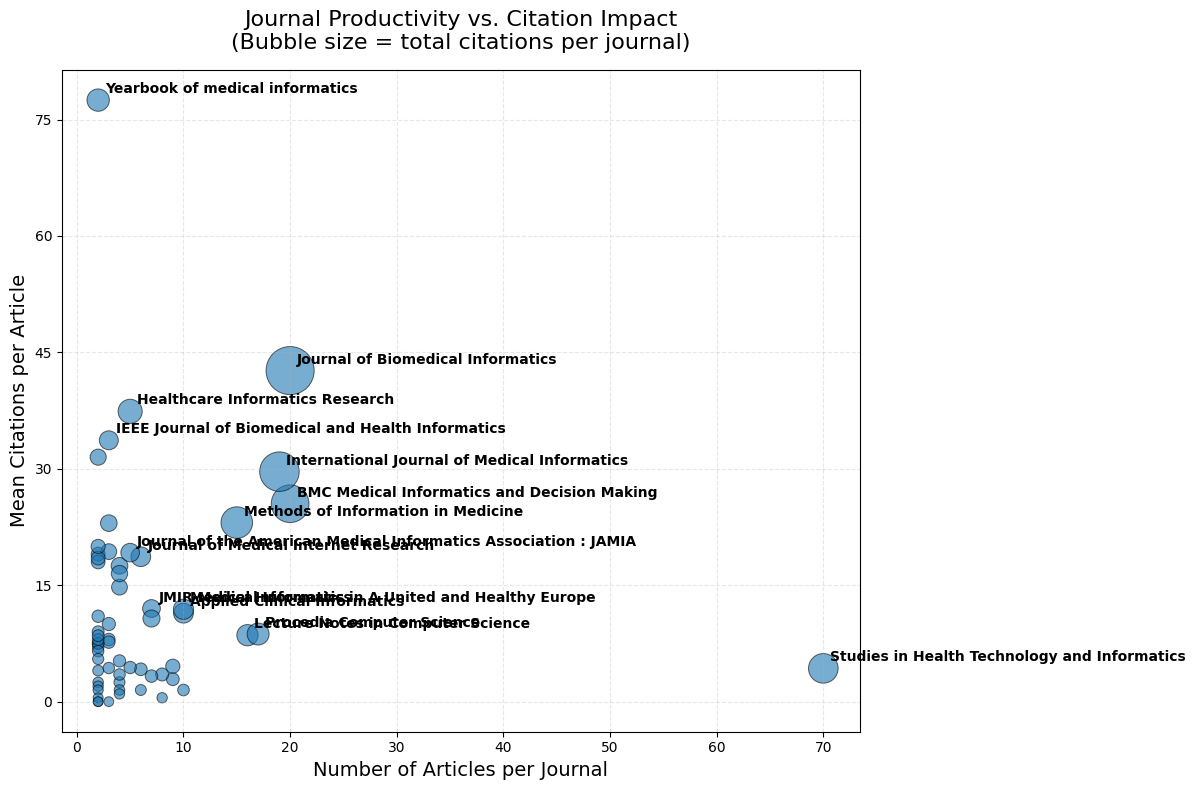

✅ `journal_productivity_vs_citation_impact.csv` as CSV saved. 


In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

JOURNAL_KEY = "journal_title"
MIN_ARTICLES = 2
TOP_LABELS = 15
BASE_MARKER_SIZE = 50
MAX_MARKER_SIZE = 1200

df = DATASET()

df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)
df_journal = df.dropna(subset=[JOURNAL_KEY]).copy()

journal_stats_df = (
    df_journal.groupby(JOURNAL_KEY, as_index=False)
    .agg(
        Num_Articles=("DBUID", "nunique"),
        Total_Citations=("citation_count", "sum"),
        Mean_Citations=("citation_count", "mean"),
    )
    .rename(columns={JOURNAL_KEY: "Journal"})
)

journal_stats_df = journal_stats_df[journal_stats_df["Num_Articles"] >= MIN_ARTICLES].copy()
journal_stats_df["Num_Articles"] = journal_stats_df["Num_Articles"].fillna(0).astype(int)
journal_stats_df["Total_Citations"] = pd.to_numeric(
    journal_stats_df["Total_Citations"], errors="coerce"
).fillna(0)
journal_stats_df["Mean_Citations"] = pd.to_numeric(
    journal_stats_df["Mean_Citations"], errors="coerce"
).fillna(0).round(2)

if journal_stats_df.empty:
    print(f"No journals found with at least {MIN_ARTICLES} articles.")
else:
    max_total_citations = journal_stats_df["Total_Citations"].max()
    size_scaled = (
        [BASE_MARKER_SIZE] * len(journal_stats_df)
        if max_total_citations <= 0
        else BASE_MARKER_SIZE
        + (journal_stats_df["Total_Citations"] / max_total_citations)
        * (MAX_MARKER_SIZE - BASE_MARKER_SIZE)
    )

    plt.figure(figsize=(12, 8))
    plt.scatter(
        journal_stats_df["Num_Articles"],
        journal_stats_df["Mean_Citations"],
        s=size_scaled,
        alpha=0.6,
        edgecolor="black",
        linewidth=0.7,
    )

    plt.title(
        "Journal Productivity vs. Citation Impact\n"
        "(Bubble size = total citations per journal)",
        fontsize=16,
        pad=15,
    )
    plt.xlabel("Number of Articles per Journal", fontsize=14)
    plt.ylabel("Mean Citations per Article", fontsize=14)
    plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=8))
    plt.grid(True, linestyle="--", alpha=0.3)

    top_journals = journal_stats_df.sort_values("Total_Citations", ascending=False).head(TOP_LABELS)
    for _, row in top_journals.iterrows():
        plt.annotate(
            row["Journal"],
            xy=(row["Num_Articles"], row["Mean_Citations"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold",
        )

    plt_savefig(plt, "journal_productivity_vs_citation_impact.png")
    plt.show()
    plt.close()

journal_stats_sorted = journal_stats_df.sort_values(
    "Total_Citations", ascending=False
).reset_index(drop=True)

dataframe_to_csv(
    journal_stats_sorted,
    "journal_productivity_vs_citation_impact.csv",
)

### Journal Quartile Distribution
Journals were categorized based on quartile rankings (e.g., Q1–Q4) to assess the quality and impact tier of publication venues. This distribution provides insight into the concentration of research across journal impact levels.

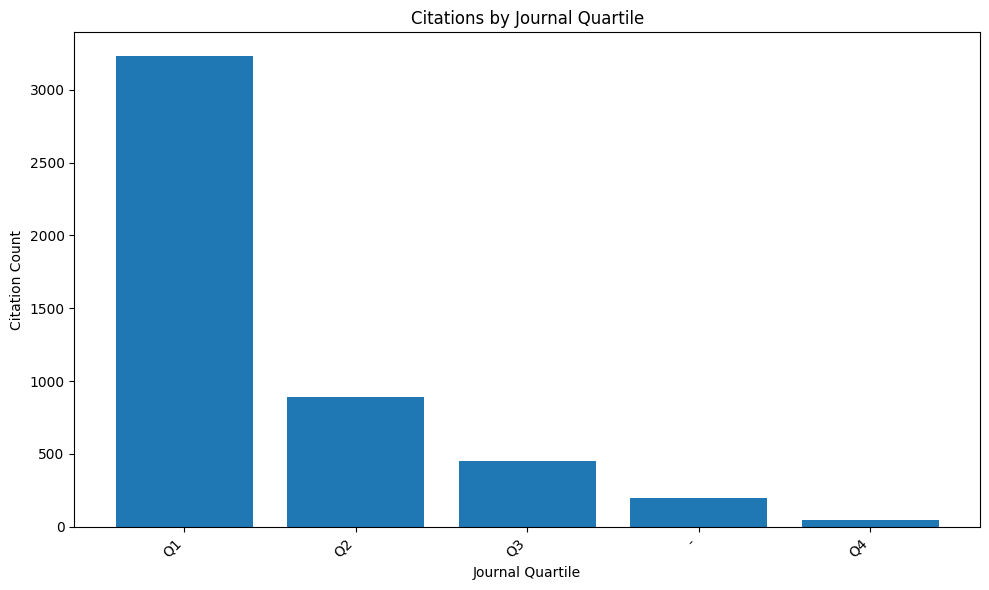

✅ `citations_by_journal_quartile.csv` as CSV saved. 


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

journal_stats = (
    df.dropna(subset=["journal_q"])
    .groupby("journal_q", as_index=False)
    .agg(
        Total_Citations=("citation_count", "sum"),
        Publications=("journal_title", "size"),
    )
    .sort_values("Total_Citations", ascending=False)
    .reset_index(drop=True)
)

journal_citation_sorted = journal_stats.head(30).copy()
title = "Citations by Journal Quartile"

plt.figure(figsize=(10, 6))
plt.bar(journal_citation_sorted["journal_q"], journal_citation_sorted["Total_Citations"])
plt.xlabel("Journal Quartile")
plt.ylabel("Citation Count")
plt.title(title)
plt.xticks(rotation=45, ha="right")
plt.subplots_adjust(bottom=0.2)

plt_savefig(plt, "citations_by_journal_quartile.png")
plt.show()

dataframe_to_csv(journal_citation_sorted, "citations_by_journal_quartile.csv")

### Bradford’s Law and Core Journal Identification
Bradford’s Law was applied to identify core journals contributing most publications. Journals were divided into zones where each zone contributes approximately equal numbers of articles, highlighting the concentration of knowledge sources.

Bradford’s Law of Scattering describes the distribution of relevant literature across scientific journals and is widely used to identify the core publication sources within a research field. According to this law, when journals are ranked in descending order of productivity (i.e., number of articles published on a given topic), they can be divided into groups or “zones” such that each zone contributes approximately the same number of relevant articles, but the number of journals required for each successive zone increases geometrically. Formally, if the first zone contains ( k ) core journals, then the number of journals in the subsequent zones tends to follow the ratio:

$$
1 : b : b^2 : b^3 : \ldots
$$

where $ b $ is Bradford’s multiplier representing the rate at which scattering increases. Bradford’s Law thus provides a quantitative model for assessing journal concentration and dispersion, helping to identify core, related, and peripheral publication outlets within a research domain.

----------------
Bradford’s Law — Results
Total Articles: 544
Zone 1 Journals: 7, Zone 2: 37, Zone 3: 166
Estimated Bradford Multiplier (b): 4.886
----------------


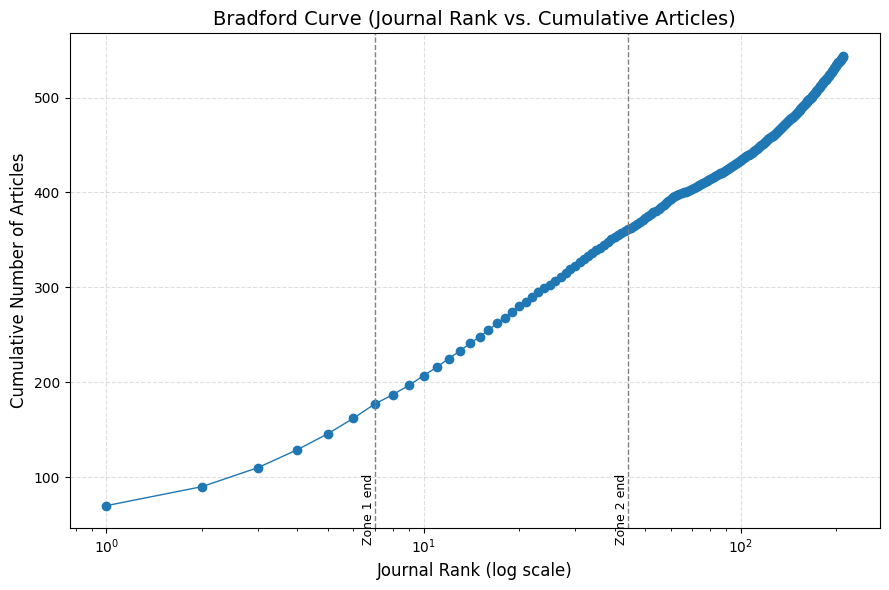

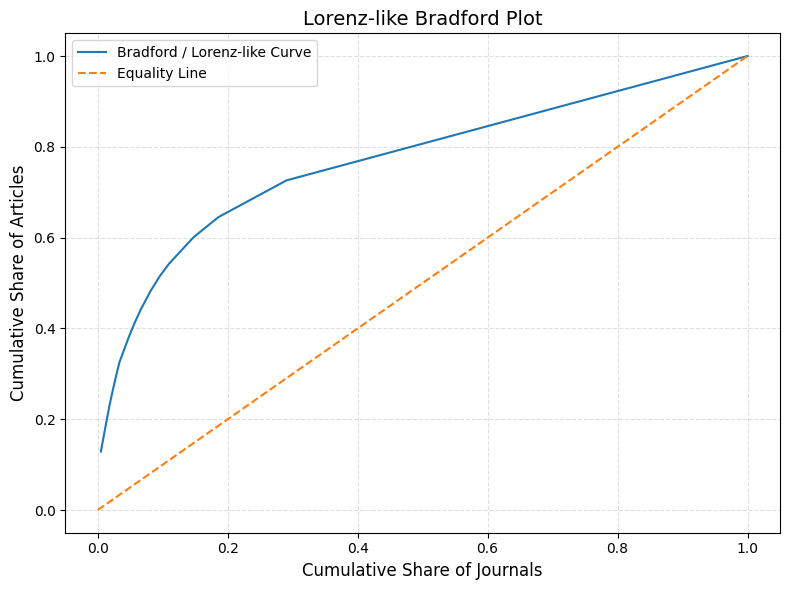

✅ `bradford_zone_distribution_summary.csv` as CSV saved. 
✅ `bradford_journal_details.csv` as CSV saved. 


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

df_journal = (
    df.dropna(subset=["journal_title"])
    .groupby("journal_title", as_index=False)
    .size()
    .rename(columns={"size": "Article_Count"})
    .sort_values("Article_Count", ascending=False)
    .reset_index(drop=True)
)

if df_journal.empty:
    raise ValueError("No journal data available for applying Bradford’s Law.")

df_journal["Rank"] = np.arange(1, len(df_journal) + 1)
total_articles = df_journal["Article_Count"].sum()
df_journal["Cumulative_Count"] = df_journal["Article_Count"].cumsum()
df_journal["Cumulative_Share"] = df_journal["Cumulative_Count"] / total_articles

df_journal["Bradford_Zone"] = pd.cut(
    df_journal["Cumulative_Share"],
    bins=[0, 1 / 3, 2 / 3, 1],
    labels=["Zone 1 (Core)", "Zone 2", "Zone 3"],
    include_lowest=True,
)

zone_counts = df_journal["Bradford_Zone"].value_counts().sort_index()
z1 = zone_counts.get("Zone 1 (Core)", 1)
z2 = zone_counts.get("Zone 2", 1)
z3 = zone_counts.get("Zone 3", 1)

b_estimate = np.nanmean([
    z2 / z1 if z1 > 0 else np.nan,
    z3 / z2 if z2 > 0 else np.nan,
])

print("----------------")
print("Bradford’s Law — Results")
print(f"Total Articles: {total_articles}")
print(f"Zone 1 Journals: {z1}, Zone 2: {z2}, Zone 3: {z3}")
print(f"Estimated Bradford Multiplier (b): {b_estimate:.3f}")
print("----------------")

zone_summary = (
    df_journal.groupby("Bradford_Zone", as_index=False, observed=True)
    .agg(
        Journals=("journal_title", "nunique"),
        Articles=("Article_Count", "sum"),
    )
)

zone_summary["Article_Share_%"] = (
    100 * zone_summary["Articles"] / total_articles
).round(2)

plt.figure(figsize=(9, 6))
plt.plot(
    df_journal["Rank"],
    df_journal["Cumulative_Count"],
    marker="o",
    linestyle="-",
    linewidth=1,
)

plt.xscale("log")
plt.xlabel("Journal Rank (log scale)", fontsize=12)
plt.ylabel("Cumulative Number of Articles", fontsize=12)
plt.title("Bradford Curve (Journal Rank vs. Cumulative Articles)", fontsize=14)

zone1_max_rank = df_journal.loc[df_journal["Bradford_Zone"] == "Zone 1 (Core)", "Rank"].max()
zone2_max_rank = df_journal.loc[df_journal["Bradford_Zone"] == "Zone 2", "Rank"].max()

if pd.notna(zone1_max_rank):
    plt.axvline(zone1_max_rank, color="grey", linestyle="--", linewidth=1)
    plt.text(
        zone1_max_rank,
        plt.ylim()[1] * 0.05,
        "Zone 1 end",
        rotation=90,
        va="bottom",
        ha="right",
        fontsize=9,
    )

if pd.notna(zone2_max_rank):
    plt.axvline(zone2_max_rank, color="grey", linestyle="--", linewidth=1)
    plt.text(
        zone2_max_rank,
        plt.ylim()[1] * 0.05,
        "Zone 2 end",
        rotation=90,
        va="bottom",
        ha="right",
        fontsize=9,
    )

plt.grid(True, linestyle="--", alpha=0.4)
plt_savefig(plt, "bradford_curve.png")
plt.show()
plt.close()

df_journal["Cum_Journals"] = df_journal["Rank"]
df_journal["Cum_Journals_Share"] = df_journal["Cum_Journals"] / len(df_journal)

plt.figure(figsize=(8, 6))
plt.plot(
    df_journal["Cum_Journals_Share"],
    df_journal["Cumulative_Share"],
    label="Bradford / Lorenz-like Curve",
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Equality Line")
plt.xlabel("Cumulative Share of Journals", fontsize=12)
plt.ylabel("Cumulative Share of Articles", fontsize=12)
plt.title("Lorenz-like Bradford Plot", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt_savefig(plt, "bradford_lorenz_like_plot.png")
plt.show()
plt.close()

dataframe_to_csv(zone_summary, "bradford_zone_distribution_summary.csv")
dataframe_to_csv(df_journal, "bradford_journal_details.csv")

## Thematic Analysis

### Thematic Category Distribution
Publications were classified into predefined thematic categories to quantify the distribution of research topics across the corpus.

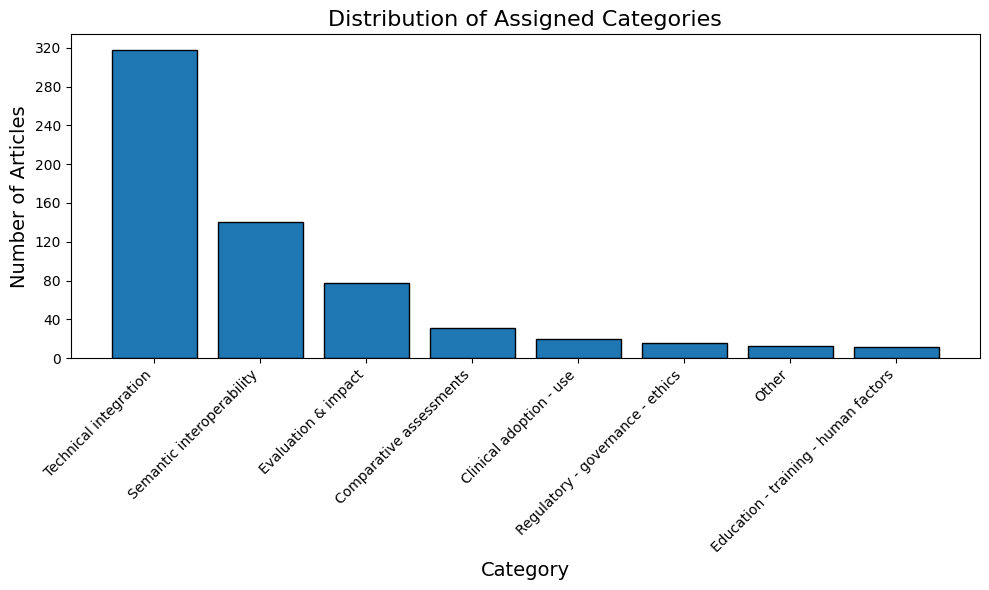

✅ `distribution_of_assigned_categories.csv` as CSV saved. 


In [1]:
import ast

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)

category_counts_df = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

category_counts_df = category_counts_df[category_counts_df["assigned_category"] != ""]

category_counts_df = (
    category_counts_df["assigned_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

category_counts_df["Count"] = (
    pd.to_numeric(category_counts_df["Count"], errors="coerce").fillna(0).astype(int)
)

total = category_counts_df["Count"].sum()
category_counts_df["Percent"] = (
    100 * category_counts_df["Count"] / total
).round(2) if total else 0

plt.figure(figsize=(10, 6))
plt.bar(
    category_counts_df["Category"],
    category_counts_df["Count"],
    edgecolor="black",
)
plt.title("Distribution of Assigned Categories", fontsize=16)
plt.xlabel("Category", fontsize=14)
plt.ylabel("Number of Articles", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.subplots_adjust(bottom=0.25)

plt_savefig(plt, "distribution_of_assigned_categories.png")
plt.show()
plt.close()

dataframe_to_csv(category_counts_df, "distribution_of_assigned_categories.csv")

### Share of thematic assignments

Total publications (N): 544
Total thematic assignments (n): 625
Sum of article prevalence (%): 114.9
Sum of thematic assignment shares (%): 100.0


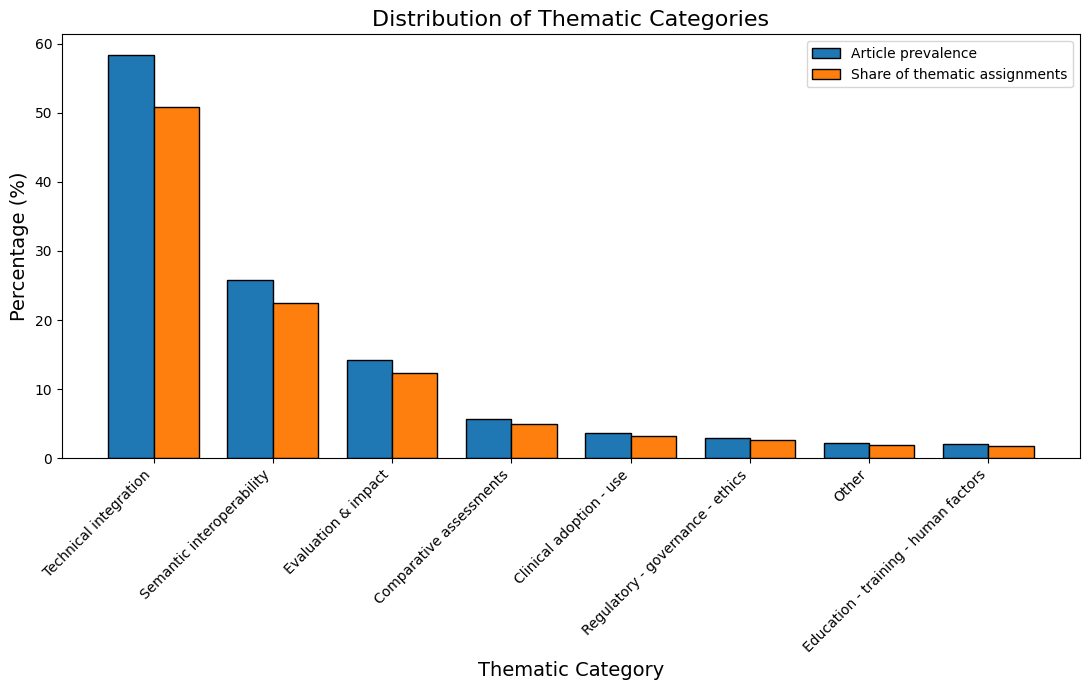

✅ `distribution_of_thematic_categories.csv` as CSV saved. 


In [3]:
import ast

import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)


# ---------------------------------------------------------------------
# Total number of publications
# ---------------------------------------------------------------------
total_publications = len(df)


# Give each publication a unique ID based on its row.
# If the dataset already has a unique article/publication ID column,
# it is better to use that column instead.
df = df.reset_index(drop=True)
df["publication_id"] = df.index


# ---------------------------------------------------------------------
# Explode thematic assignments
# ---------------------------------------------------------------------
assignments_df = (
    df[["publication_id", "assigned_category"]]
    .explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(
        assigned_category=lambda x:
        x["assigned_category"].astype(str).str.strip()
    )
)

assignments_df = assignments_df[
    assignments_df["assigned_category"] != ""
]


# ---------------------------------------------------------------------
# Remove duplicate assignment of the same category within one article
# ---------------------------------------------------------------------
assignments_df = assignments_df.drop_duplicates(
    subset=["publication_id", "assigned_category"]
)


# ---------------------------------------------------------------------
# Total number of thematic assignments
# ---------------------------------------------------------------------
total_assignments = len(assignments_df)


# ---------------------------------------------------------------------
# Number of publications assigned to each thematic category
# ---------------------------------------------------------------------
category_counts_df = (
    assignments_df
    .groupby("assigned_category")["publication_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename_axis("Category")
    .reset_index(name="Publications, n")
)


# ---------------------------------------------------------------------
# Article prevalence
#
# Publications assigned to the theme / all publications
# ---------------------------------------------------------------------
category_counts_df["Article prevalence (%)"] = (
    100
    * category_counts_df["Publications, n"]
    / total_publications
).round(2)


# ---------------------------------------------------------------------
# Share of thematic assignments
#
# Assignments to the theme / all thematic assignments
# ---------------------------------------------------------------------
category_counts_df["Share of thematic assignments (%)"] = (
    100
    * category_counts_df["Publications, n"]
    / total_assignments
).round(2)


# ---------------------------------------------------------------------
# Print checks
# ---------------------------------------------------------------------
print(f"Total publications (N): {total_publications}")
print(f"Total thematic assignments (n): {total_assignments}")

print(
    "Sum of article prevalence (%):",
    category_counts_df["Article prevalence (%)"].sum(),
)

print(
    "Sum of thematic assignment shares (%):",
    category_counts_df["Share of thematic assignments (%)"].sum(),
)

# print(category_counts_df)


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 7))

x = range(len(category_counts_df))
width = 0.38

ax.bar(
    [i - width / 2 for i in x],
    category_counts_df["Article prevalence (%)"],
    width=width,
    label="Article prevalence",
    edgecolor="black",
)

ax.bar(
    [i + width / 2 for i in x],
    category_counts_df["Share of thematic assignments (%)"],
    width=width,
    label="Share of thematic assignments",
    edgecolor="black",
)

ax.set_title(
    "Distribution of Thematic Categories",
    fontsize=16,
)

ax.set_xlabel(
    "Thematic Category",
    fontsize=14,
)

ax.set_ylabel(
    "Percentage (%)",
    fontsize=14,
)

ax.set_xticks(list(x))
ax.set_xticklabels(
    category_counts_df["Category"],
    rotation=45,
    ha="right",
)

ax.legend()

plt.subplots_adjust(bottom=0.30)

plt_savefig(
    plt,
    "distribution_of_thematic_categories.png",
)

plt.show()
plt.close()


# ---------------------------------------------------------------------
# Save table
# ---------------------------------------------------------------------
dataframe_to_csv(
    category_counts_df,
    "distribution_of_thematic_categories.csv",
)

### Distribution of Research Themes
This analysis presents the proportional representation of each thematic category, identifying dominant and underrepresented research areas.

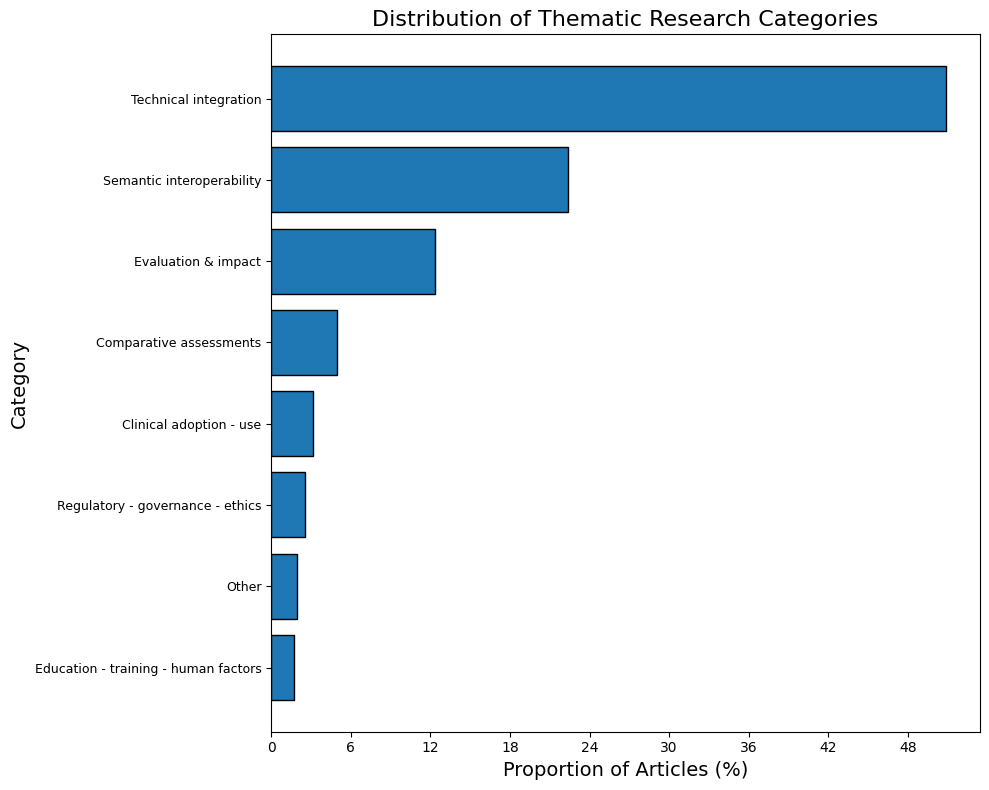

✅ `distribution_of_thematic_research_categories.csv` as CSV saved. 


In [2]:
import ast

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)

category_counts_df = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

category_counts_df = category_counts_df[category_counts_df["assigned_category"] != ""]

category_counts_df = (
    category_counts_df["assigned_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

category_counts_df["Count"] = (
    pd.to_numeric(category_counts_df["Count"], errors="coerce").fillna(0).astype(int)
)

total = category_counts_df["Count"].sum()
category_counts_df["Percent"] = (
    100 * category_counts_df["Count"] / total
).round(2) if total else 0.0

category_counts_df = category_counts_df.sort_values("Percent", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 8))
plt.barh(
    category_counts_df["Category"],
    category_counts_df["Percent"],
    edgecolor="black",
)
plt.title("Distribution of Thematic Research Categories", fontsize=16)
plt.xlabel("Proportion of Articles (%)", fontsize=14)
plt.ylabel("Category", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=9)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().invert_yaxis()
plt.subplots_adjust(left=0.3)

plt_savefig(plt, "distribution_of_thematic_research_categories.png")
plt.show()
plt.close()

dataframe_to_csv(
    category_counts_df,
    "distribution_of_thematic_research_categories.csv",
)

### Cross-national Distribution of Research Themes
This section examines how thematic categories are distributed across countries, revealing geographic specialization in research topics.

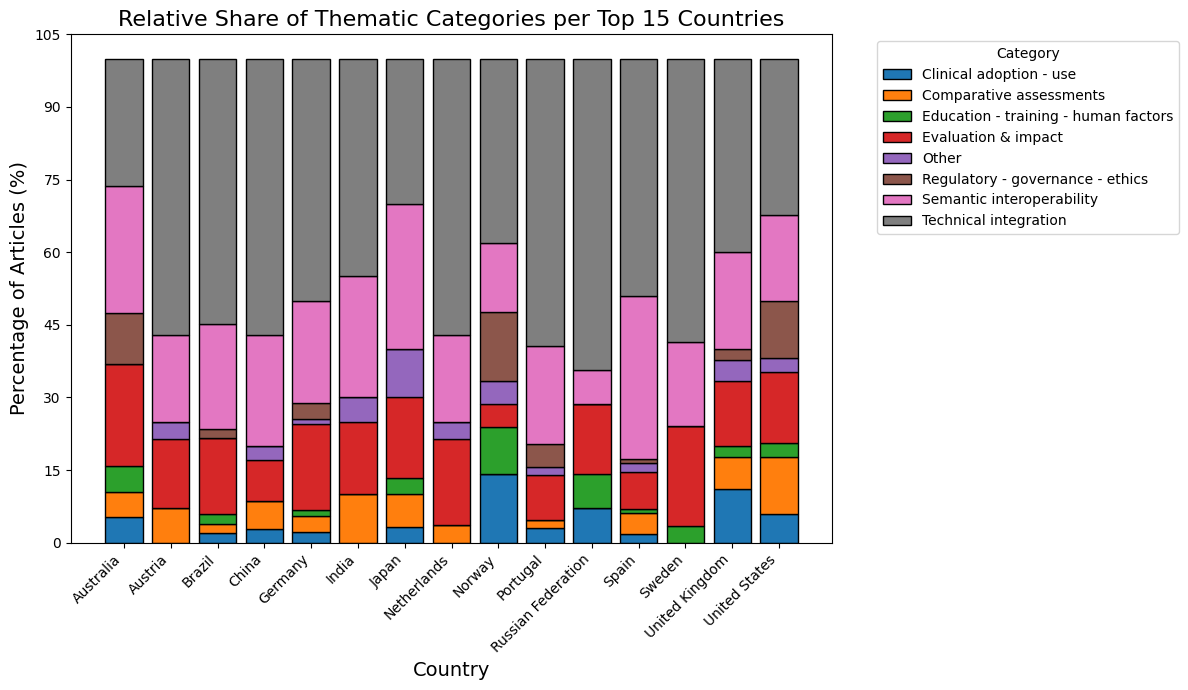

✅ `stacked_thematic_categories_top15_countries.csv` as CSV saved. 


In [3]:
import ast

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
        "affiliation_integration_country": "affiliation_country",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)
df["affiliation_country"] = df["affiliation_country"].apply(safe_eval)

df_exp = (
    df.explode("affiliation_country")
    .explode("assigned_category")
    .dropna(subset=["affiliation_country", "assigned_category"])
    .assign(
        affiliation_country=lambda x: x["affiliation_country"].astype(str).str.strip(),
        assigned_category=lambda x: x["assigned_category"].astype(str).str.strip(),
    )
)

df_exp = df_exp[
    (df_exp["affiliation_country"] != "") & (df_exp["assigned_category"] != "")
]

country_category_counts = (
    df_exp.groupby(["affiliation_country", "assigned_category"], as_index=False)
    .size()
    .rename(columns={"size": "Count"})
)

top_countries = (
    country_category_counts.groupby("affiliation_country")["Count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .index
)

pivot_df = (
    country_category_counts[
        country_category_counts["affiliation_country"].isin(top_countries)
    ]
    .pivot_table(
        index="affiliation_country",
        columns="assigned_category",
        values="Count",
        aggfunc="sum",
        fill_value=0,
    )
)

pivot_pct = (
    pivot_df.div(pivot_df.sum(axis=1), axis=0).mul(100).sort_index()
)

plt.figure(figsize=(12, 7))

bottom = pd.Series(0, index=pivot_pct.index, dtype=float)
for category in pivot_pct.columns:
    plt.bar(
        pivot_pct.index,
        pivot_pct[category],
        bottom=bottom,
        label=category,
        edgecolor="black",
    )
    bottom = bottom + pivot_pct[category]

plt.title("Relative Share of Thematic Categories per Top 15 Countries", fontsize=16)
plt.ylabel("Percentage of Articles (%)", fontsize=14)
plt.xlabel("Country", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.subplots_adjust(bottom=0.25, right=0.78)

plt_savefig(plt, "stacked_thematic_categories_top15_countries.png")
plt.show()
plt.close()

dataframe_to_csv(
    pivot_pct.reset_index(),
    "stacked_thematic_categories_top15_countries.csv",
)

### Temporal Evolution of Thematic Diversity (Shannon Index) 
To quantify the thematic diversity within the corpus of research articles, we employed the **Shannon Diversity Index (H′)**, a widely used information-theoretic measure of heterogeneity across categorical distributions. This index captures both **richness** (the number of distinct thematic categories) and **evenness** (the balance in their relative frequencies). Higher values of *H′* indicate a more diverse and evenly distributed thematic landscape, whereas lower values reflect concentration around a few dominant themes.

The Shannon Index is calculated using the standard formulation:

$$
H' = -\sum_{i=1}^{S} p_i , \ln(p_i)
$$

where:

* ( S ) is the total number of thematic categories observed,
* ( p_i ) is the proportion of all category assignments belonging to category ( i ),
* ( p_i \ln(p_i) ) is defined only for ( p_i > 0 ) to avoid logarithmic singularities.

This measure is particularly appropriate for thematic analysis because it does not assume uniform category sizes, is sensitive to changes in both common and rare categories, and provides a continuous, interpretable scale for comparing thematic diversity across different years, countries, or publication sets.

Overall Shannon Index for thematic categories: 1.437


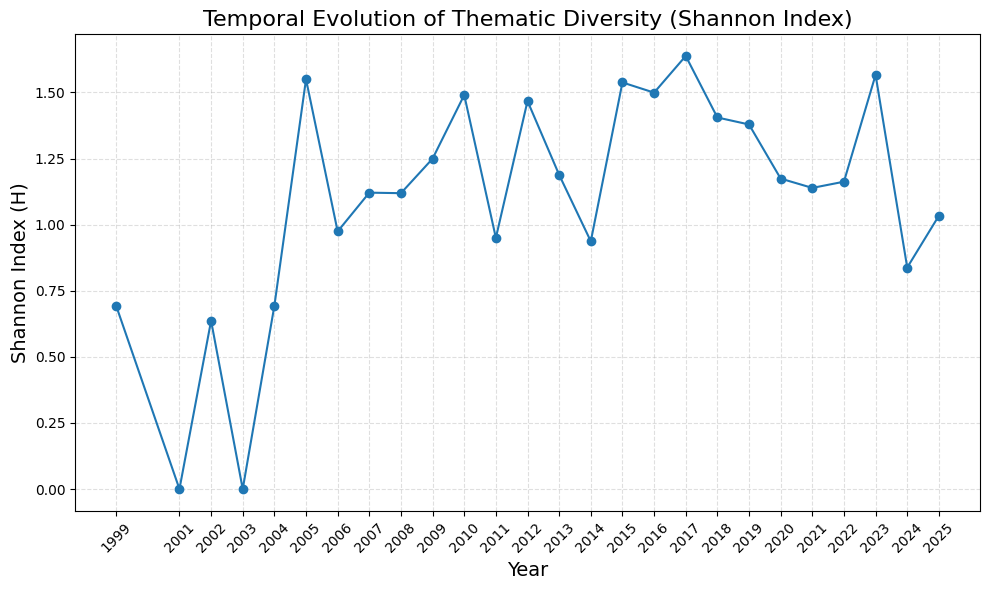

✅ `shannon_thematic_diversity_over_time.csv` as CSV saved. 


In [4]:
import ast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

YEAR_MIN = None
YEAR_MAX = None

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


def shannon_index(counts):
    total = counts.sum()
    if total == 0:
        return 0.0
    proportions = counts / total
    proportions = proportions[proportions > 0]
    return float(-(proportions * np.log(proportions)).sum())


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]

if df.empty:
    raise ValueError("No articles available after year filtering for Shannon diversity analysis.")

df_exploded = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

df_exploded = df_exploded[df_exploded["assigned_category"] != ""]

if df_exploded.empty:
    raise ValueError("No thematic categories found in assigned_category after exploding.")

overall_shannon = shannon_index(df_exploded["assigned_category"].value_counts())
print(f"Overall Shannon Index for thematic categories: {overall_shannon:.3f}")

shannon_df = (
    df_exploded.groupby("year")["assigned_category"]
    .value_counts()
    .groupby(level=0)
    .apply(shannon_index)
    .reset_index(name="Shannon_Index")
    .rename(columns={"year": "Year"})
    .sort_values("Year")
    .reset_index(drop=True)
)

plt.figure(figsize=(10, 6))
plt.plot(
    shannon_df["Year"],
    shannon_df["Shannon_Index"],
    marker="o",
)
plt.title("Temporal Evolution of Thematic Diversity (Shannon Index)", fontsize=16)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Shannon Index (H)", fontsize=14)
plt.xticks(shannon_df["Year"], rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.subplots_adjust(bottom=0.2)

plt_savefig(plt, "shannon_thematic_diversity_over_time.png")
plt.show()
plt.close()

dataframe_to_csv(
    shannon_df,
    "shannon_thematic_diversity_over_time.csv",
)

### Annual Thematic Diversity Measured Using the Shannon Index

In [33]:
import ast

import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv

YEAR_MIN = None
YEAR_MAX = None

N_BOOTSTRAP = 2000
RANDOM_SEED = 42

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


def clean_categories(categories):
    return [
        str(category).strip()
        for category in categories
        if pd.notna(category) and str(category).strip() != ""
    ]


def shannon_index(counts):
    total = counts.sum()

    if total == 0:
        return 0.0

    proportions = counts / total
    proportions = proportions[proportions > 0]

    return float(
        -(proportions * np.log(proportions)).sum()
    )


def shannon_from_category_lists(category_lists):
    categories = [
        category
        for categories_per_article in category_lists
        for category in categories_per_article
    ]

    if not categories:
        return np.nan

    counts = pd.Series(categories).value_counts()

    return shannon_index(counts)


def bootstrap_shannon_ci(
    category_lists,
    n_bootstrap=2000,
    confidence_level=0.95,
    random_seed=42,
):
    category_lists = list(category_lists)

    n_publications = len(category_lists)

    if n_publications == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(random_seed)

    bootstrap_values = []

    for _ in range(n_bootstrap):
        sampled_indices = rng.integers(
            0,
            n_publications,
            size=n_publications,
        )

        sampled_categories = [
            category_lists[index]
            for index in sampled_indices
        ]

        bootstrap_values.append(
            shannon_from_category_lists(sampled_categories)
        )

    bootstrap_values = np.asarray(
        bootstrap_values,
        dtype=float,
    )

    bootstrap_values = bootstrap_values[
        ~np.isnan(bootstrap_values)
    ]

    if len(bootstrap_values) == 0:
        return np.nan, np.nan

    alpha = 1 - confidence_level

    lower_ci = np.quantile(
        bootstrap_values,
        alpha / 2,
    )

    upper_ci = np.quantile(
        bootstrap_values,
        1 - alpha / 2,
    )

    return float(lower_ci), float(upper_ci)


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = (
    df["assigned_category"]
    .apply(safe_eval)
    .apply(clean_categories)
)

df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce",
)

df = df.dropna(
    subset=["year"]
).copy()

df["year"] = df["year"].astype(int)

if YEAR_MIN is not None:
    df = df[
        df["year"] >= YEAR_MIN
    ]

if YEAR_MAX is not None:
    df = df[
        df["year"] <= YEAR_MAX
    ]

if df.empty:
    raise ValueError(
        "No articles available after year filtering "
        "for Shannon diversity analysis."
    )


# Keep publications with at least one thematic category
df = df[
    df["assigned_category"].apply(len) > 0
].copy()

if df.empty:
    raise ValueError(
        "No thematic categories found in assigned_category."
    )


# Build annual thematic diversity table
annual_results = []

for year, group in df.groupby("year", sort=True):

    category_lists = group[
        "assigned_category"
    ].tolist()

    publications_n = len(group)

    thematic_assignments_n = sum(
        len(categories)
        for categories in category_lists
    )

    shannon = shannon_from_category_lists(
        category_lists
    )

    ci_lower, ci_upper = bootstrap_shannon_ci(
        category_lists,
        n_bootstrap=N_BOOTSTRAP,
        confidence_level=0.95,
        random_seed=RANDOM_SEED + int(year),
    )

    annual_results.append(
        {
            "Year": year,
            "Publications, n": publications_n,
            "Thematic assignments, n": thematic_assignments_n,
            "Shannon index": shannon,
            "95% CI lower": ci_lower,
            "95% CI upper": ci_upper,
        }
    )


annual_diversity_df = pd.DataFrame(
    annual_results
)


# Format numerical values
annual_diversity_df[
    "Shannon index"
] = annual_diversity_df[
    "Shannon index"
].round(3)

annual_diversity_df[
    "95% CI lower"
] = annual_diversity_df[
    "95% CI lower"
].round(3)

annual_diversity_df[
    "95% CI upper"
] = annual_diversity_df[
    "95% CI upper"
].round(3)


# Create publication-ready CI column
annual_diversity_df[
    "95% CI"
] = annual_diversity_df.apply(
    lambda row: (
        f"{row['95% CI lower']:.3f}–"
        f"{row['95% CI upper']:.3f}"
    ),
    axis=1,
)


# Final publication table
table_df = annual_diversity_df[
    [
        "Year",
        "Publications, n",
        "Thematic assignments, n",
        "Shannon index",
        "95% CI",
    ]
].copy()


print(
    "\nAnnual Thematic Diversity "
    "Measured Using the Shannon Index\n"
)

print(
    table_df.to_string(
        index=False
    )
)


dataframe_to_csv(
    table_df,
    "annual_thematic_diversity_shannon_index.csv",
)


Annual Thematic Diversity Measured Using the Shannon Index

 Year  Publications, n  Thematic assignments, n  Shannon index       95% CI
 1999                2                        2          0.693 -0.000–0.693
 2001                2                        2         -0.000 -0.000–0.000
 2002                3                        3          0.637 -0.000–0.637
 2003                3                        3         -0.000 -0.000–0.000
 2004                2                        2          0.693 -0.000–0.693
 2005                6                        7          1.550  0.637–1.560
 2006                8                        8          0.974  0.377–1.082
 2007               10                       11          1.121  0.500–1.314
 2008               13                       13          1.119  0.617–1.306
 2009               24                       27          1.250  0.839–1.436
 2010               28                       29          1.490  1.089–1.636
 2011               27     

### Thematic Evolution Sankey Diagram 
A Sankey diagram was used to visualize the continuity of major thematic categories across consecutive time periods. For each period, publication counts were aggregated by thematic category, and flows between adjacent periods were defined based on the shared presence of the same category. Flow magnitude was conservatively estimated using the minimum count observed across the two connected periods. This visualization highlights the persistence and changing prominence of thematic domains over time.

In [7]:
import ast
import pandas as pd
import plotly.graph_objects as go
from src.config import OUTPUT_DIR
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv

# ---------------------- Settings -------------------------
YEAR_MIN = 2002
YEAR_MAX = 2025
TOP_N_CATEGORIES = 3
OTHER_LABEL = "Other"

PERIODS = [
    ("2002-2007", 2002, 2007),
    ("2008-2013", 2008, 2013),
    ("2014-2019", 2014, 2019),
    ("2020-2025", 2020, 2025),
]

df = DATASET()

df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]

def assign_period(year):
    for label, start, end in PERIODS:
        if start <= year <= end:
            return label
    return None

def make_node_label(period, category, count):
    return f"{period} | {category} ({count})"

# ---------------------- Main use -------------------------

df["assigned_category"] = df["assigned_category"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)
df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)].copy()

if df.empty:
    raise ValueError("No articles found in the specified year range.")

df["Period"] = df["year"].apply(assign_period)
df = df.dropna(subset=["Period"]).copy()

# Explode thematic categories
df_exploded = (
    df[["DBUID", "Period", "assigned_category"]]
    .explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .copy()
)

df_exploded["assigned_category"] = df_exploded["assigned_category"].astype(str).str.strip()
df_exploded = df_exploded[df_exploded["assigned_category"] != ""]

if df_exploded.empty:
    raise ValueError("No thematic category data available after exploding assigned_category.")

# Keep top global categories and collapse the rest
top_categories = (
    df_exploded["assigned_category"]
    .value_counts()
    .head(TOP_N_CATEGORIES)
    .index
    .tolist()
)

df_exploded["Category_Grouped"] = df_exploded["assigned_category"].apply(
    lambda x: x if x in top_categories else OTHER_LABEL
)

# Count unique articles per period and category
period_theme_counts = (
    df_exploded.groupby(["Period", "Category_Grouped"], as_index=False)
    .agg(Count=("DBUID", "nunique"))
)

# Create full matrix to preserve zero cells
period_order = [p[0] for p in PERIODS]
all_categories = sorted(period_theme_counts["Category_Grouped"].dropna().unique().tolist())

full_index = pd.MultiIndex.from_product(
    [period_order, all_categories],
    names=["Period", "Category_Grouped"]
)

period_theme_counts = (
    period_theme_counts
    .set_index(["Period", "Category_Grouped"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

dataframe_to_csv(period_theme_counts, "thematic_counts_by_period.csv")

# Node label dictionary
node_label_map = {}
for _, row in period_theme_counts.iterrows():
    period = row["Period"]
    category = row["Category_Grouped"]
    count = int(row["Count"])
    node_label_map[(period, category)] = make_node_label(period, category, count)

# Build continuity flows only
flow_rows = []

for i in range(len(period_order) - 1):
    period_a = period_order[i]
    period_b = period_order[i + 1]

    df_a = (
        period_theme_counts[period_theme_counts["Period"] == period_a]
        .rename(columns={"Category_Grouped": "Category", "Count": "Count_A"})
        [["Category", "Count_A"]]
    )

    df_b = (
        period_theme_counts[period_theme_counts["Period"] == period_b]
        .rename(columns={"Category_Grouped": "Category", "Count": "Count_B"})
        [["Category", "Count_B"]]
    )

    merged = df_a.merge(df_b, on="Category", how="outer").fillna(0)

    for _, row in merged.iterrows():
        category = row["Category"]
        count_a = int(row["Count_A"])
        count_b = int(row["Count_B"])
        flow_value = min(count_a, count_b)

        if flow_value <= 0:
            continue

        flow_rows.append({
            "Source_Period": period_a,
            "Target_Period": period_b,
            "Category": category,
            "Source_Count": count_a,
            "Target_Count": count_b,
            "Flow": flow_value,
            "Source_Label": node_label_map[(period_a, category)],
            "Target_Label": node_label_map[(period_b, category)],
        })

flows_df = pd.DataFrame(flow_rows)

if flows_df.empty:
    raise ValueError("No thematic continuity flows were created for Sankey visualization.")

dataframe_to_csv(flows_df, "thematic_evolution_sankey_continuity_flows.csv")

# Keep only connected nodes
used_nodes = pd.unique(
    pd.concat([flows_df["Source_Label"], flows_df["Target_Label"]], ignore_index=True)
).tolist()

node_map = {label: idx for idx, label in enumerate(used_nodes)}

sources = flows_df["Source_Label"].map(node_map).tolist()
targets = flows_df["Target_Label"].map(node_map).tolist()
values = flows_df["Flow"].astype(int).tolist()

# Plot
fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=18,
                thickness=18,
                line=dict(color="black", width=0.5),
                label=used_nodes,
            ),
            link=dict(
                source=sources,
                target=targets,
                value=values,
            ),
        )
    ]
)

fig.update_layout(
    title={
        "text": "Thematic Evolution Flow Across Time Periods",
        "x": 0.5,
    },
    font=dict(size=11),
)

# Save outputs 
html_path = OUTPUT_DIR / "thematic_evolution_sankey_labeled_counts.html"
fig.write_html(str(html_path))
print("Saved HTML: thematic_evolution_sankey_labeled_counts.html")

try:
    fig.write_image(
        str(OUTPUT_DIR / "thematic_evolution_sankey_labeled_counts.png"),
        format="png",
        scale=2,
    )
    print("Saved PNG: thematic_evolution_sankey_labeled_counts.png")
except Exception as e:
    print(f"Could not save PNG (Plotly static export error): {e}")

fig.show()

✅ `thematic_counts_by_period.csv` as CSV saved. 
✅ `thematic_evolution_sankey_continuity_flows.csv` as CSV saved. 
Saved HTML: thematic_evolution_sankey_labeled_counts.html
Saved PNG: thematic_evolution_sankey_labeled_counts.png


### Thematic Strategic Diagram (Category-Based)
A category-based thematic strategic diagram was constructed using the predefined thematic classification of the corpus. Centrality was estimated from the weighted co-occurrence of each category with other thematic domains, whereas density was approximated by the average strength of its observed thematic links. Categories were then positioned into four quadrants representing motor themes, basic themes, niche themes, and emerging or declining themes. This visualization provides a structured overview of the relative maturity and interconnectedness of the thematic domains identified in the study.

✅ `strategic_diagram_category_frequency.csv` as CSV saved. 
✅ `strategic_diagram_category_edges.csv` as CSV saved. 
✅ `thematic_strategic_diagram_category_based_metrics.csv` as CSV saved. 


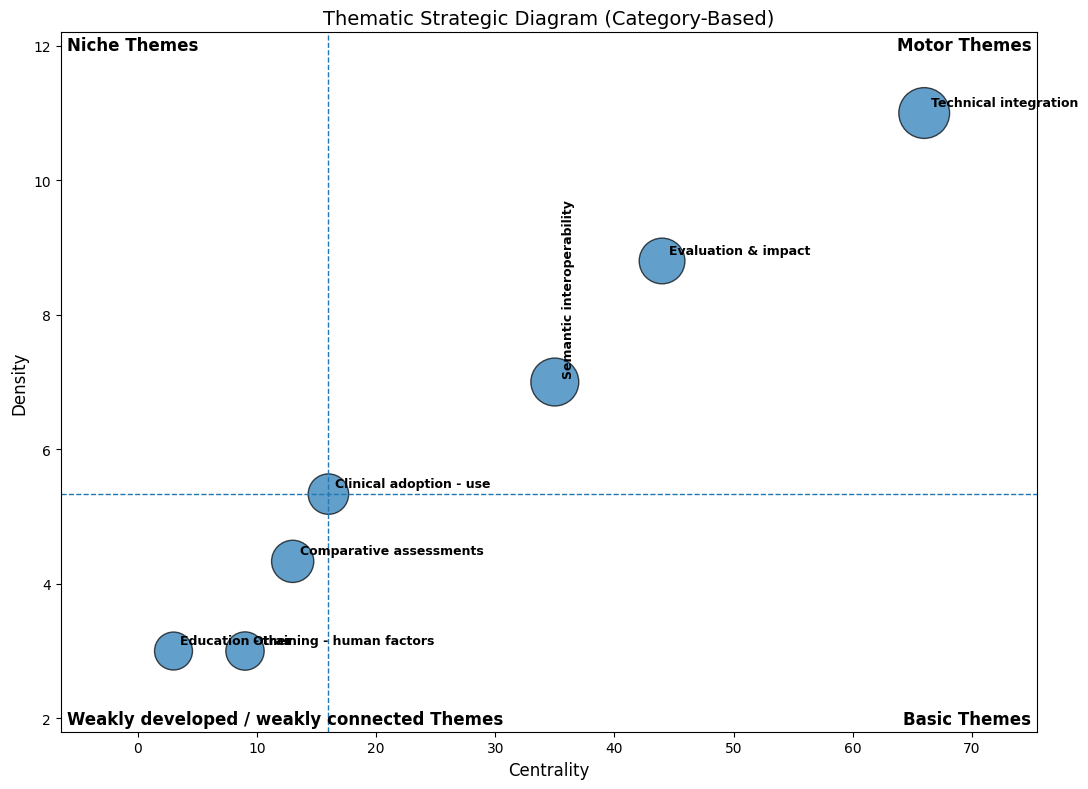

Median centrality: 16.0
Median density: 5.3333
Number of thematic categories plotted: 7


In [ ]:
import ast
import math
import itertools
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
MIN_CATEGORY_FREQ = 5
MIN_EDGE_WEIGHT = 2

df = DATASET()


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]

def clean_text_list(values):
    cleaned = []
    for value in values:
        if pd.isna(value):
            continue
        text = str(value).strip()
        if text == "":
            continue
        cleaned.append(text)
    return cleaned

def deduplicate_preserve_order(values):
    seen = set()
    result = []
    for value in values:
        if value not in seen:
            seen.add(value)
            result.append(value)
    return result

# Load and clean 
CATEGORY_COL = "assigned_category"

if CATEGORY_COL not in df.columns:
    raise ValueError(f"Column '{CATEGORY_COL}' is required for category-based strategic diagram.")

df["thematic_categories"] = df[CATEGORY_COL].apply(safe_eval)
df["thematic_categories"] = df["thematic_categories"].apply(clean_text_list)
df["thematic_categories"] = df["thematic_categories"].apply(deduplicate_preserve_order)

df = df[df["thematic_categories"].apply(len) > 0].copy()

if df.empty:
    raise ValueError("No valid thematic category data found after preprocessing.")

# Category frequency
category_freq = (
    df.explode("thematic_categories")["thematic_categories"]
    .value_counts()
    .reset_index()
)
category_freq.columns = ["Category", "Frequency"]

category_freq = category_freq[category_freq["Frequency"] >= MIN_CATEGORY_FREQ].copy()

if category_freq.empty:
    raise ValueError("No thematic categories remained after frequency filtering.")

selected_categories = set(category_freq["Category"].tolist())

dataframe_to_csv(category_freq, "strategic_diagram_category_frequency.csv")

# Build category co-occurrence edges
edge_counter = {}

for _, row in df.iterrows():
    cats = [c for c in row["thematic_categories"] if c in selected_categories]
    cats = sorted(set(cats))

    if len(cats) < 2:
        continue

    for a, b in itertools.combinations(cats, 2):
        edge_counter[(a, b)] = edge_counter.get((a, b), 0) + 1

edge_rows = [
    {"Source": a, "Target": b, "Weight": w}
    for (a, b), w in edge_counter.items()
    if w >= MIN_EDGE_WEIGHT
]

edge_df = pd.DataFrame(edge_rows)

if edge_df.empty:
    raise ValueError(
        "No category co-occurrence edges remained after filtering. "
        "Try lowering MIN_EDGE_WEIGHT."
    )

dataframe_to_csv(edge_df, "strategic_diagram_category_edges.csv")

# Build graph
G = nx.Graph()

for _, row in category_freq.iterrows():
    G.add_node(row["Category"], frequency=int(row["Frequency"]))

for _, row in edge_df.iterrows():
    G.add_edge(row["Source"], row["Target"], weight=float(row["Weight"]))

isolates = list(nx.isolates(G))
if isolates:
    G.remove_nodes_from(isolates)

if G.number_of_nodes() < 3:
    raise ValueError("Too few connected thematic categories are available for the strategic diagram.")

# Compute category-level metrics
rows = []

for node in G.nodes():
    node_frequency = G.nodes[node].get("frequency", 0)

    neighbors = list(G.neighbors(node))
    weighted_degree = sum(G[node][nbr].get("weight", 0.0) for nbr in neighbors)

    # Centrality: weighted external connectivity to the thematic network
    centrality = weighted_degree

    # Density proxy: average strength of links for this thematic category
    density = weighted_degree / len(neighbors) if len(neighbors) > 0 else 0.0

    rows.append({
        "Category": node,
        "Frequency": int(node_frequency),
        "Num_Neighbors": int(len(neighbors)),
        "Weighted_Degree": float(weighted_degree),
        "Centrality": float(centrality),
        "Density": float(density),
    })

theme_df = pd.DataFrame(rows)

if theme_df.empty:
    raise ValueError("No strategic diagram metrics could be computed.")

theme_df = theme_df.sort_values(
    ["Frequency", "Weighted_Degree"],
    ascending=[False, False]
).reset_index(drop=True)

# Quadrants
median_centrality = theme_df["Centrality"].median()
median_density = theme_df["Density"].median()

def assign_quadrant(row, x_med, y_med):
    x = row["Centrality"]
    y = row["Density"]

    if x >= x_med and y >= y_med:
        return "Motor Themes"
    elif x >= x_med and y < y_med:
        return "Basic Themes"
    elif x < x_med and y >= y_med:
        return "Niche Themes"
    else:
        return "Emerging/Declining Themes"
        # return "Weakly developed / weakly connected Themes"

theme_df["Quadrant"] = theme_df.apply(
    lambda row: assign_quadrant(row, median_centrality, median_density),
    axis=1
)

dataframe_to_csv(theme_df, "thematic_strategic_diagram_category_based_metrics.csv")

# Plot
plt.figure(figsize=(11, 8))

sizes = [
    300 + 180 * math.log1p(v)
    for v in theme_df["Frequency"].astype(float).tolist()
]

plt.scatter(
    theme_df["Centrality"],
    theme_df["Density"],
    s=sizes,
    alpha=0.7,
    edgecolors="black",
    linewidths=1,
)

for _, row in theme_df.iterrows():
    rotation_angle = 90 if row["Category"] == "Semantic interoperability" else 0
    plt.annotate(
        row["Category"],
        (row["Centrality"], row["Density"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        rotation=rotation_angle,
    )

plt.axvline(x=median_centrality, linestyle="--", linewidth=1)
plt.axhline(y=median_density, linestyle="--", linewidth=1)

x_min = theme_df["Centrality"].min()
x_max = theme_df["Centrality"].max()
y_min = theme_df["Density"].min()
y_max = theme_df["Density"].max()

x_pad = (x_max - x_min) * 0.15 if x_max > x_min else 1.0
y_pad = (y_max - y_min) * 0.15 if y_max > y_min else 1.0

plt.xlim(x_min - x_pad, x_max + x_pad)
plt.ylim(y_min - y_pad, y_max + y_pad)

plt.text(
    x_max + x_pad * 0.95, y_max + y_pad * 0.95, "Motor Themes",
    ha="right", va="top", fontsize=12, fontweight="bold"
)
plt.text(
    x_max + x_pad * 0.95, y_min - y_pad * 0.95, "Basic Themes",
    ha="right", va="bottom", fontsize=12, fontweight="bold"
)
plt.text(
    x_min - x_pad * 0.95, y_max + y_pad * 0.95, "Niche Themes",
    ha="left", va="top", fontsize=12, fontweight="bold"
)
plt.text(
    x_min - x_pad * 0.95, y_min - y_pad * 0.95, "Emerging/Declining",
    ha="left", va="bottom", fontsize=12, fontweight="bold"
)


plt.xlabel("Centrality", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.title("Thematic Strategic Diagram (Category-Based)", fontsize=14)
plt.tight_layout()

plt_savefig(plt, "thematic_strategic_diagram_category_based.png")
plt.show()
plt.close()

print("Median centrality:", round(median_centrality, 4))
print("Median density:", round(median_density, 4))
print("Number of thematic categories plotted:", len(theme_df))

The category-based thematic strategic diagram reveals a clear structural hierarchy within the research field. Technical integration is positioned as a dominant motor theme, exhibiting both high centrality and density, indicating that it is both well-developed and strongly interconnected with other domains. Semantic interoperability and evaluation & impact also occupy the upper-right quadrant, suggesting that these areas are mature and play a central role in shaping the field’s knowledge structure. In contrast, clinical adoption – use appears near the boundary between basic and emerging themes, reflecting moderate integration but comparatively lower internal cohesion, consistent with its limited representation in the literature. Themes such as regulatory, governance, and ethics and education, training, and human factors fall within the emerging or declining quadrant, indicating weak connectivity and low development, and highlighting critical gaps in non-technical dimensions. Overall, the diagram confirms a strong concentration of research around technical and interoperability-oriented topics, with underdeveloped attention to governance, human factors, and real-world clinical implementation.

### Thematic Strategic Diagram (Category-Based) - Revision

✅ `strategic_diagram_category_frequency.csv` as CSV saved. 
✅ `strategic_diagram_category_edges.csv` as CSV saved. 
✅ `thematic_strategic_diagram_category_based_metrics.csv` as CSV saved. 


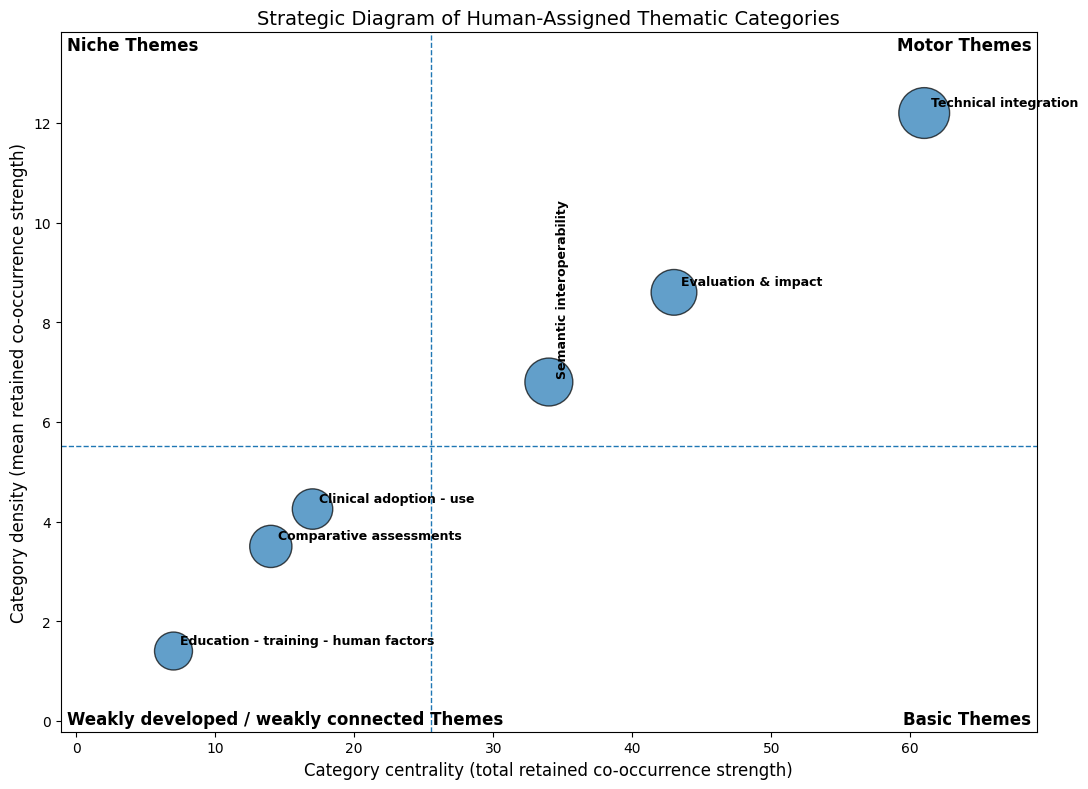

Minimum category frequency: 1
Minimum edge weight: 1
Excluded categories: ['Other']
Median category centrality: 25.5
Median category density: 5.525
Number of thematic categories plotted: 6
Number of retained co-occurrence edges: 14


In [5]:
import ast
import math
import itertools

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv


# ============================================================
# Strategic diagram based on HUMAN-ASSIGNED thematic categories
# ============================================================
#
# IMPORTANT METHODOLOGICAL NOTE
# -----------------------------
# The thematic categories used in this analysis were assigned
# manually through human review of article abstracts.
#
# Therefore:
#   - no keyword clustering was performed;
#   - no co-word clustering was performed;
#   - nodes represent predefined / human-assigned thematic
#     categories, not algorithmically generated thematic clusters.
#
# Consequently, the "density" used below is NOT Callon density.
# It is a category-level measure defined specifically for this
# analysis as the mean retained co-occurrence strength of a
# category with its connected categories.
#
# The strategic diagram should therefore be interpreted as a
# descriptive category co-occurrence map rather than a classical
# Callon co-word strategic diagram.
# ============================================================


# ---------------------- Settings -----------------------------

# Minimum number of publications in which a thematic category
# must occur to be retained in the analysis.
MIN_CATEGORY_FREQ = 1 # 5

# Minimum number of publications in which two categories must
# co-occur for their edge to be retained.
MIN_EDGE_WEIGHT = 1 # 2

# Residual / non-substantive categories excluded from the
# strategic-diagram analysis.
EXCLUDED_CATEGORIES = {"Other"}

# Original dataset column containing the manually assigned
# thematic categories.
CATEGORY_COL = "assigned_category"


# ============================================================
# Load dataset
# ============================================================

df = DATASET()

df = df.rename(
    columns={
        "DEFA_assigned_category_v3": CATEGORY_COL,
    }
)

if CATEGORY_COL not in df.columns:
    raise ValueError(
        f"Column '{CATEGORY_COL}' is required for the "
        "category-based strategic diagram."
    )


# ============================================================
# Helper functions
# ============================================================

def safe_eval(value):
    """
    Convert a dataset value into a Python list.

    The category column may contain:
      - an actual list;
      - a string representation of a list;
      - a single category value;
      - a missing value.

    This function standardises all valid values into lists.
    """
    if isinstance(value, list):
        return value

    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]

    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        return [parsed]

    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


def clean_text_list(values):
    """
    Remove missing and empty category labels and strip
    leading/trailing whitespace.
    """
    cleaned = []

    for value in values:
        if pd.isna(value):
            continue

        text = str(value).strip()

        if not text:
            continue

        cleaned.append(text)

    return cleaned


def deduplicate_preserve_order(values):
    """
    Remove duplicate thematic categories within the same
    publication while preserving their original order.

    A category can therefore contribute at most once per
    publication to category frequency and pairwise co-occurrence.
    """
    seen = set()
    result = []

    for value in values:
        if value not in seen:
            seen.add(value)
            result.append(value)

    return result


def remove_excluded_categories(values):
    """
    Remove residual / non-substantive categories such as 'Other'.

    These categories are excluded because they do not correspond
    to a specific substantive thematic construct.
    """
    return [
        value
        for value in values
        if value not in EXCLUDED_CATEGORIES
    ]


# ============================================================
# Preprocess manually assigned thematic categories
# ============================================================

df["thematic_categories"] = df[CATEGORY_COL].apply(safe_eval)

df["thematic_categories"] = (
    df["thematic_categories"]
    .apply(clean_text_list)
    .apply(deduplicate_preserve_order)
    .apply(remove_excluded_categories)
)

# Retain only publications containing at least one valid,
# substantive thematic category.
df = df[
    df["thematic_categories"].apply(len) > 0
].copy()

if df.empty:
    raise ValueError(
        "No valid thematic category data remained after preprocessing."
    )


# ============================================================
# Category frequency
# ============================================================
#
# For thematic category i:
#
#       f_i = number of publications assigned to category i
#
# Only categories with:
#
#       f_i >= MIN_CATEGORY_FREQ
#
# are retained.
# ============================================================

category_freq = (
    df
    .explode("thematic_categories")["thematic_categories"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Frequency")
)

category_freq = category_freq[
    category_freq["Frequency"] >= MIN_CATEGORY_FREQ
].copy()

if category_freq.empty:
    raise ValueError(
        "No thematic categories remained after applying "
        f"MIN_CATEGORY_FREQ = {MIN_CATEGORY_FREQ}."
    )

selected_categories = set(category_freq["Category"])

dataframe_to_csv(
    category_freq,
    "strategic_diagram_category_frequency.csv"
)


# ============================================================
# Construct category co-occurrence network
# ============================================================
#
# Two categories i and j are considered to co-occur when both
# were assigned to the same publication.
#
# The edge weight is:
#
#       w_ij = number of publications containing both i and j
#
# Only edges satisfying:
#
#       w_ij >= MIN_EDGE_WEIGHT
#
# are retained.
#
# This is a publication-level category co-occurrence network.
# ============================================================

edge_counter = {}

for categories in df["thematic_categories"]:

    # Retain only categories that passed the frequency threshold.
    cats = [
        category
        for category in categories
        if category in selected_categories
    ]

    # Ensure uniqueness within each publication.
    cats = sorted(set(cats))

    if len(cats) < 2:
        continue

    for category_a, category_b in itertools.combinations(cats, 2):

        pair = (category_a, category_b)

        edge_counter[pair] = edge_counter.get(pair, 0) + 1


edge_rows = [
    {
        "Source": category_a,
        "Target": category_b,
        "Weight": weight,
    }
    for (category_a, category_b), weight in edge_counter.items()
    if weight >= MIN_EDGE_WEIGHT
]

edge_df = pd.DataFrame(
    edge_rows,
    columns=["Source", "Target", "Weight"]
)

if edge_df.empty:
    raise ValueError(
        "No category co-occurrence edges remained after applying "
        f"MIN_EDGE_WEIGHT = {MIN_EDGE_WEIGHT}. "
        "Consider lowering the edge-weight threshold."
    )

dataframe_to_csv(
    edge_df,
    "strategic_diagram_category_edges.csv"
)


# ============================================================
# Build weighted undirected graph
# ============================================================

G = nx.Graph()

# Add every category passing the frequency threshold.
for _, row in category_freq.iterrows():

    G.add_node(
        row["Category"],
        frequency=int(row["Frequency"]),
    )


# Add retained co-occurrence edges.
for _, row in edge_df.iterrows():

    G.add_edge(
        row["Source"],
        row["Target"],
        weight=float(row["Weight"]),
    )


# Categories with no retained connections cannot be positioned
# meaningfully using the connectivity measures defined below.
# They are therefore excluded from the strategic diagram.
isolates = list(nx.isolates(G))

if isolates:
    G.remove_nodes_from(isolates)


if G.number_of_nodes() < 3:
    raise ValueError(
        "Too few connected thematic categories remain for "
        "constructing the strategic diagram."
    )


# ============================================================
# Compute category-level strategic-diagram measures
# ============================================================
#
# IMPORTANT:
# These measures are operational definitions for this study.
# They are NOT Callon centrality and Callon density.
#
#
# 1. Category centrality
# ----------------------
# For category i:
#
#       C_i = sum_j w_ij
#
# where j belongs to the set of retained neighbours N_i.
#
# Thus C_i is the weighted degree of category i and represents
# its total retained co-occurrence strength with the rest of
# the thematic-category network.
#
#
# 2. Category density
# -------------------
# For category i:
#
#       D_i = (sum_j w_ij) / |N_i|
#
# or equivalently:
#
#       D_i = C_i / |N_i|
#
# This measure represents the mean retained co-occurrence
# strength between category i and its connected categories.
#
# It is therefore a CATEGORY-LEVEL CONNECTIVITY / COHESION
# measure and should NOT be interpreted as Callon density,
# within-cluster density, temporal maturity, or development.
#
#
# No additional normalization (e.g. min-max scaling,
# z-standardisation, or cosine normalization) is applied to
# either C_i or D_i.
# ============================================================

metric_rows = []

for node in G.nodes():

    frequency = int(
        G.nodes[node].get("frequency", 0)
    )

    neighbors = list(G.neighbors(node))

    num_neighbors = len(neighbors)

    weighted_degree = sum(
        G[node][neighbor].get("weight", 0.0)
        for neighbor in neighbors
    )

    # Total retained connection strength to the category network.
    category_centrality = float(weighted_degree)

    # Mean retained connection strength per connected category.
    category_density = (
        float(weighted_degree) / num_neighbors
        if num_neighbors > 0
        else 0.0
    )

    metric_rows.append(
        {
            "Category": node,
            "Frequency": frequency,
            "Num_Neighbors": num_neighbors,
            "Weighted_Degree": float(weighted_degree),

            # Strategic-diagram coordinates used in this study.
            "Centrality": category_centrality,
            "Density": category_density,

            # Explicit descriptive alias showing the actual
            # meaning of the y-axis measure.
            "Mean_Cooccurrence_Strength": category_density,
        }
    )


theme_df = pd.DataFrame(metric_rows)

if theme_df.empty:
    raise ValueError(
        "No category-level strategic-diagram measures "
        "could be computed."
    )


theme_df = (
    theme_df
    .sort_values(
        ["Frequency", "Weighted_Degree"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)


# ============================================================
# Define quadrant boundaries
# ============================================================
#
# Quadrant boundaries are data-adaptive and are defined using
# the medians of the two category-level measures:
#
#       C* = median(C_i)
#       D* = median(D_i)
#
# No externally imposed numerical cut-off is used.
# ============================================================

median_centrality = theme_df["Centrality"].median()
median_density = theme_df["Density"].median()


def assign_quadrant(row, centrality_threshold, density_threshold):
    """
    Assign each thematic category to one of four descriptive
    quadrants based on the median values of category centrality
    and category density.

    Importantly, the lower-left quadrant is NOT labelled
    'emerging/declining', because the present analysis is
    cross-sectional and does not contain longitudinal evidence.
    """

    centrality = row["Centrality"]
    density = row["Density"]

    if (
        centrality >= centrality_threshold
        and density >= density_threshold
    ):
        return "Motor Themes"

    elif (
        centrality >= centrality_threshold
        and density < density_threshold
    ):
        return "Basic Themes"

    elif (
        centrality < centrality_threshold
        and density >= density_threshold
    ):
        return "Niche Themes"

    else:
        return "Weakly developed / weakly connected Themes"


theme_df["Quadrant"] = theme_df.apply(
    lambda row: assign_quadrant(
        row,
        median_centrality,
        median_density,
    ),
    axis=1,
)


dataframe_to_csv(
    theme_df,
    "thematic_strategic_diagram_category_based_metrics.csv"
)


# ============================================================
# Bubble-size definition
# ============================================================
#
# Bubble size represents category frequency.
#
# For category i:
#
#       S_i = 300 + 180 * ln(1 + f_i)
#
# where:
#
#   f_i = number of publications assigned to category i
#   S_i = matplotlib marker area in points^2
#
# Logarithmic scaling is used to reduce visual domination by
# highly frequent categories while preserving frequency
# differences.
# ============================================================

bubble_sizes = (
    300
    + 180
    * theme_df["Frequency"].astype(float).apply(math.log1p)
)


# ============================================================
# Plot strategic diagram
# ============================================================

plt.figure(figsize=(11, 8))


plt.scatter(
    theme_df["Centrality"],
    theme_df["Density"],
    s=bubble_sizes,
    alpha=0.7,
    edgecolors="black",
    linewidths=1,
)


# Add category labels.
for _, row in theme_df.iterrows():

    # Optional visual adjustment for a long label.
    rotation_angle = (
        90
        if row["Category"] == "Semantic interoperability"
        else 0
    )

    plt.annotate(
        row["Category"],
        (
            row["Centrality"],
            row["Density"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        rotation=rotation_angle,
    )


# Median-based quadrant boundaries.
plt.axvline(
    x=median_centrality,
    linestyle="--",
    linewidth=1,
)

plt.axhline(
    y=median_density,
    linestyle="--",
    linewidth=1,
)


# ============================================================
# Plot limits
# ============================================================

x_min = theme_df["Centrality"].min()
x_max = theme_df["Centrality"].max()

y_min = theme_df["Density"].min()
y_max = theme_df["Density"].max()


x_pad = (
    (x_max - x_min) * 0.15
    if x_max > x_min
    else 1.0
)

y_pad = (
    (y_max - y_min) * 0.15
    if y_max > y_min
    else 1.0
)


plt.xlim(
    x_min - x_pad,
    x_max + x_pad,
)

plt.ylim(
    y_min - y_pad,
    y_max + y_pad,
)


# ============================================================
# Quadrant labels
# ============================================================

plt.text(
    x_max + x_pad * 0.95,
    y_max + y_pad * 0.95,
    "Motor Themes",
    ha="right",
    va="top",
    fontsize=12,
    fontweight="bold",
)

plt.text(
    x_max + x_pad * 0.95,
    y_min - y_pad * 0.95,
    "Basic Themes",
    ha="right",
    va="bottom",
    fontsize=12,
    fontweight="bold",
)

plt.text(
    x_min - x_pad * 0.95,
    y_max + y_pad * 0.95,
    "Niche Themes",
    ha="left",
    va="top",
    fontsize=12,
    fontweight="bold",
)

plt.text(
    x_min - x_pad * 0.95,
    y_min - y_pad * 0.95,
    "Weakly developed / weakly connected Themes",
    ha="left",
    va="bottom",
    fontsize=12,
    fontweight="bold",
)


# ============================================================
# Axis labels and title
# ============================================================

plt.xlabel(
    "Category centrality (total retained co-occurrence strength)",
    fontsize=12,
)

plt.ylabel(
    "Category density (mean retained co-occurrence strength)",
    fontsize=12,
)

plt.title(
    "Strategic Diagram of Human-Assigned Thematic Categories",
    fontsize=14,
)

plt.tight_layout()


# ============================================================
# Save and display
# ============================================================

plt_savefig(
    plt,
    "thematic_strategic_diagram_category_based.png",
)

plt.show()
plt.close()


# ============================================================
# Report analysis parameters
# ============================================================

print(
    "Minimum category frequency:",
    MIN_CATEGORY_FREQ,
)

print(
    "Minimum edge weight:",
    MIN_EDGE_WEIGHT,
)

print(
    "Excluded categories:",
    sorted(EXCLUDED_CATEGORIES),
)

print(
    "Median category centrality:",
    round(median_centrality, 4),
)

print(
    "Median category density:",
    round(median_density, 4),
)

print(
    "Number of thematic categories plotted:",
    len(theme_df),
)

print(
    "Number of retained co-occurrence edges:",
    G.number_of_edges(),
)

### Thematic Strategic Diagram (Category-Based) - Revision - without co-occure


Substantive thematic categories retained:
- Clinical adoption - use
- Comparative assessments
- Education - training - human factors
- Evaluation & impact
- Regulatory - governance - ethics
- Semantic interoperability
- Technical integration
Number of substantive thematic categories: 7
✅ `strategic_diagram_category_frequency.csv` as CSV saved. 
✅ `strategic_diagram_category_edges.csv` as CSV saved. 

Isolated thematic categories:
- Regulatory - governance - ethics (Frequency = 16)
✅ `thematic_strategic_diagram_category_based_metrics.csv` as CSV saved. 


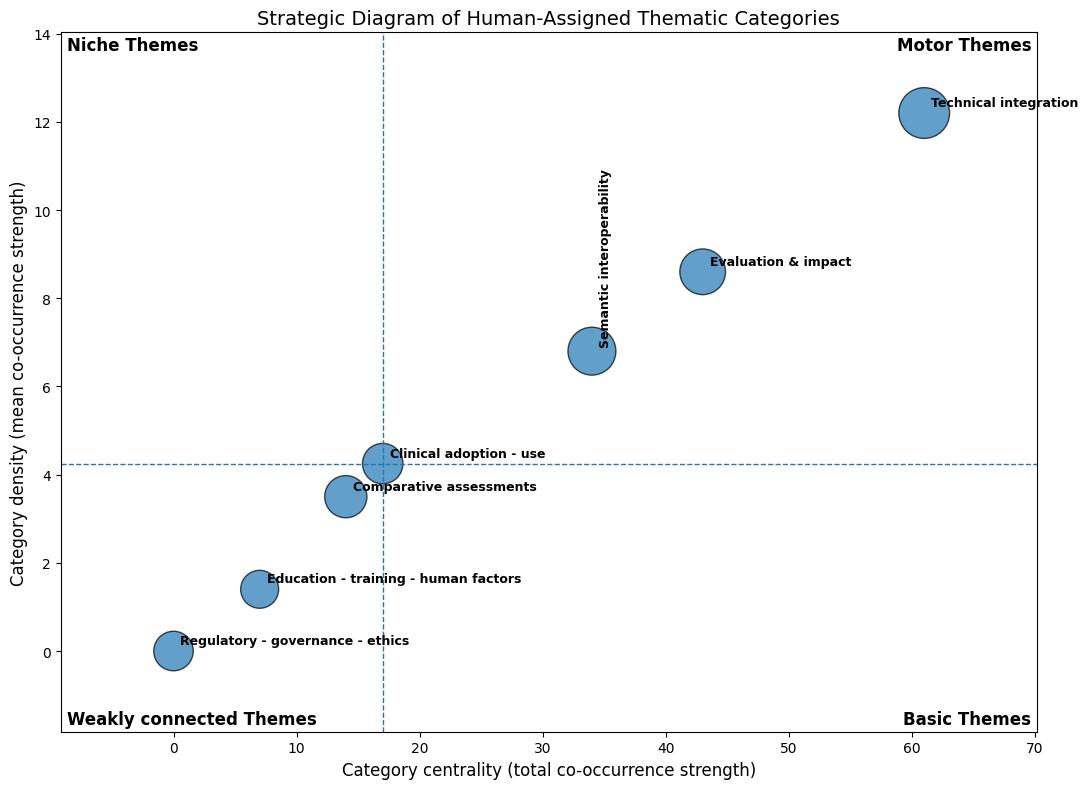


STRATEGIC DIAGRAM SUMMARY
Excluded residual categories: ['Other']
Number of substantive categories: 7
Number of observed co-occurrence edges: 14
Number of isolated categories: 1
Median centrality: 17.0
Median density: 4.25

Final thematic categories:
                            Category  Frequency  Num_Neighbors  Centrality  Density  Is_Isolate                Quadrant
               Technical integration        318              5        61.0    12.20       False            Motor Themes
           Semantic interoperability        140              5        34.0     6.80       False            Motor Themes
                 Evaluation & impact         77              5        43.0     8.60       False            Motor Themes
             Comparative assessments         31              4        14.0     3.50       False Weakly connected Themes
             Clinical adoption - use         20              4        17.0     4.25       False            Motor Themes
    Regulatory - governance 

In [8]:
import ast
import math
import itertools

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv


# ============================================================
# Strategic diagram of HUMAN-ASSIGNED thematic categories
# ============================================================
#
# METHODOLOGICAL NOTE
# -------------------
# The thematic categories used in this analysis were assigned
# manually through human review of article abstracts.
#
# Therefore:
#   - no keyword clustering was performed;
#   - no co-word clustering was performed;
#   - no algorithmic thematic clustering was performed;
#   - nodes represent substantive human-assigned categories.
#
# The analysis examines publication-level co-occurrence among
# these predefined thematic categories.
#
# The measures termed "Centrality" and "Density" below are
# study-specific category-level network measures.
#
# They must NOT be interpreted as Callon centrality or
# Callon density.
#
# All substantive thematic categories are retained, including
# categories with zero co-occurrence with other categories.
#
# Only the residual category "Other" is excluded.
# ============================================================


# ============================================================
# Settings
# ============================================================

CATEGORY_COL = "assigned_category"

# "Other" is a residual classification rather than a substantive
# thematic category and is therefore excluded from the strategic
# diagram.
EXCLUDED_CATEGORIES = {"Other"}


# ============================================================
# Load dataset
# ============================================================

df = DATASET()

df = df.rename(
    columns={
        "DEFA_assigned_category_v3": CATEGORY_COL,
    }
)

if CATEGORY_COL not in df.columns:
    raise ValueError(
        f"Column '{CATEGORY_COL}' is required for the "
        "category-based strategic diagram."
    )


# ============================================================
# Helper functions
# ============================================================

def safe_eval(value):
    """
    Convert a category-field value into a Python list.

    The input may be:
      - an actual list;
      - a string representation of a list;
      - a single category;
      - a missing value.

    All valid values are returned as lists.
    """

    if isinstance(value, list):
        return value

    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]

    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        return [parsed]

    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


def clean_text_list(values):
    """
    Remove missing/empty labels and strip whitespace.
    """

    cleaned = []

    for value in values:

        if pd.isna(value):
            continue

        text = str(value).strip()

        if not text:
            continue

        cleaned.append(text)

    return cleaned


def deduplicate_preserve_order(values):
    """
    Remove duplicate thematic categories within the same
    publication while preserving their original order.

    Consequently, one category contributes at most once per
    publication to category frequency and pairwise co-occurrence.
    """

    seen = set()
    result = []

    for value in values:

        if value not in seen:
            seen.add(value)
            result.append(value)

    return result


def remove_excluded_categories(values):
    """
    Remove residual categories that do not represent substantive
    thematic constructs.

    In the present analysis, only "Other" is excluded.
    """

    return [
        value
        for value in values
        if value not in EXCLUDED_CATEGORIES
    ]


# ============================================================
# Preprocess human-assigned thematic categories
# ============================================================

df["thematic_categories"] = (
    df[CATEGORY_COL]
    .apply(safe_eval)
    .apply(clean_text_list)
    .apply(deduplicate_preserve_order)
    .apply(remove_excluded_categories)
)


# Publications that contain no substantive thematic category
# after removal of "Other" cannot contribute to the category
# network and are therefore excluded.
df = df[
    df["thematic_categories"].apply(len) > 0
].copy()


if df.empty:
    raise ValueError(
        "No substantive thematic-category data remained "
        "after preprocessing."
    )


# ============================================================
# Identify all substantive thematic categories
# ============================================================
#
# IMPORTANT:
# No category-frequency threshold is applied.
#
# All substantive human-assigned categories occurring in at
# least one publication are retained.
# ============================================================

all_categories = sorted(
    df.explode("thematic_categories")["thematic_categories"]
    .dropna()
    .unique()
    .tolist()
)


print("\nSubstantive thematic categories retained:")

for category in all_categories:
    print("-", category)

print(
    "Number of substantive thematic categories:",
    len(all_categories),
)


# ============================================================
# Category frequency
# ============================================================
#
# For category i:
#
#       f_i = number of publications assigned to category i
#
# No minimum-frequency threshold is imposed because these are
# predefined substantive categories rather than noisy keyword
# terms or algorithmically detected clusters.
# ============================================================

category_freq = (
    df
    .explode("thematic_categories")["thematic_categories"]
    .value_counts()
    .reindex(all_categories, fill_value=0)
    .rename_axis("Category")
    .reset_index(name="Frequency")
)


dataframe_to_csv(
    category_freq,
    "strategic_diagram_category_frequency.csv",
)


# ============================================================
# Construct publication-level category co-occurrences
# ============================================================
#
# Two categories i and j co-occur when both were assigned to
# the same publication.
#
# For each pair:
#
#       w_ij = number of publications containing both i and j
#
# Every observed co-occurrence (w_ij >= 1) is retained.
#
# No minimum edge-weight threshold is applied because the
# network contains only a small number of substantive,
# human-assigned thematic categories.
# ============================================================

edge_counter = {}


for categories in df["thematic_categories"]:

    # Ensure that each category appears only once per publication.
    categories = sorted(set(categories))

    if len(categories) < 2:
        continue

    for category_a, category_b in itertools.combinations(
        categories,
        2,
    ):

        pair = (category_a, category_b)

        edge_counter[pair] = (
            edge_counter.get(pair, 0) + 1
        )


edge_rows = [
    {
        "Source": category_a,
        "Target": category_b,
        "Weight": weight,
    }
    for (category_a, category_b), weight
    in edge_counter.items()
]


edge_df = pd.DataFrame(
    edge_rows,
    columns=[
        "Source",
        "Target",
        "Weight",
    ],
)


# An empty edge table is technically possible if no publication
# contains more than one substantive thematic category.
#
# Unlike the previous implementation, this does NOT invalidate
# the categories themselves. They can still be represented as
# isolated nodes with centrality = 0 and density = 0.
dataframe_to_csv(
    edge_df,
    "strategic_diagram_category_edges.csv",
)


# ============================================================
# Build weighted undirected category network
# ============================================================

G = nx.Graph()


# Add ALL substantive categories before adding any edges.
#
# This is important: categories with no co-occurrence relations
# must still remain present in the network.
for _, row in category_freq.iterrows():

    G.add_node(
        row["Category"],
        frequency=int(row["Frequency"]),
    )


# Add all observed publication-level co-occurrence relationships.
for _, row in edge_df.iterrows():

    G.add_edge(
        row["Source"],
        row["Target"],
        weight=float(row["Weight"]),
    )


# ============================================================
# Identify isolated categories
# ============================================================
#
# An isolate is a substantive category that occurs in the corpus
# but never co-occurs with another substantive category.
#
# Isolates are NOT removed.
#
# The absence of co-occurrence is itself an informative network
# property and should be preserved in the strategic diagram.
# ============================================================

isolates = list(nx.isolates(G))


print("\nIsolated thematic categories:")

if isolates:

    for category in isolates:

        print(
            f"- {category} "
            f"(Frequency = "
            f"{G.nodes[category].get('frequency', 0)})"
        )

else:

    print("None")


# ============================================================
# Compute category-level network measures
# ============================================================
#
# IMPORTANT:
#
# These are study-specific operational measures for the
# human-assigned category network.
#
# They are NOT Callon centrality and Callon density.
#
#
# ------------------------------------------------------------
# 1. Category Centrality
# ------------------------------------------------------------
#
# For category i:
#
#       C_i = sum_{j in N_i} w_ij
#
# where:
#
#       N_i  = categories connected to i
#       w_ij = publication-level co-occurrence count
#
# C_i therefore represents the TOTAL co-occurrence strength
# linking category i to other thematic categories.
#
# For an isolated category:
#
#       C_i = 0
#
#
# ------------------------------------------------------------
# 2. Category Density
# ------------------------------------------------------------
#
# For category i with at least one neighbour:
#
#               sum_{j in N_i} w_ij
#       D_i = ----------------------
#                     |N_i|
#
# or equivalently:
#
#       D_i = C_i / |N_i|
#
# D_i represents the MEAN co-occurrence strength of category i
# with its connected thematic categories.
#
# For an isolated category, |N_i| = 0. Since no mean connection
# strength exists, D_i is operationally assigned a value of 0
# for visualization and descriptive comparison:
#
#       D_i = 0, when |N_i| = 0
#
# This value reflects absence of category co-occurrence rather
# than Callon-type within-cluster density.
#
#
# ------------------------------------------------------------
# Normalization
# ------------------------------------------------------------
#
# No additional normalization is applied:
#
#   - no min-max normalization;
#   - no z-standardization;
#   - no cosine normalization;
#   - no equivalence-index normalization.
#
# Raw publication-level co-occurrence counts are used.
# ============================================================

metric_rows = []


for node in G.nodes():

    frequency = int(
        G.nodes[node].get(
            "frequency",
            0,
        )
    )

    neighbors = list(
        G.neighbors(node)
    )

    num_neighbors = len(
        neighbors
    )


    weighted_degree = sum(
        float(
            G[node][neighbor].get(
                "weight",
                0.0,
            )
        )
        for neighbor in neighbors
    )


    # Category centrality:
    # total co-occurrence strength with all connected categories.
    centrality = float(
        weighted_degree
    )


    # Category density:
    # mean co-occurrence strength with connected categories.
    #
    # For an isolate, both connectivity measures are set to zero.
    if num_neighbors > 0:

        density = (
            weighted_degree
            / num_neighbors
        )

    else:

        density = 0.0


    metric_rows.append(
        {
            "Category": node,

            "Frequency": frequency,

            "Num_Neighbors": int(
                num_neighbors
            ),

            "Weighted_Degree": float(
                weighted_degree
            ),

            "Centrality": float(
                centrality
            ),

            "Density": float(
                density
            ),

            # Explicit descriptive label for methodological
            # transparency.
            "Mean_Cooccurrence_Strength": float(
                density
            ),

            "Is_Isolate": (
                num_neighbors == 0
            ),
        }
    )


theme_df = pd.DataFrame(
    metric_rows
)


if theme_df.empty:
    raise ValueError(
        "No strategic-diagram metrics "
        "could be computed."
    )


theme_df = (
    theme_df
    .sort_values(
        [
            "Frequency",
            "Weighted_Degree",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# Quadrant boundaries
# ============================================================
#
# The vertical and horizontal boundaries are defined by the
# medians of the category-level measures:
#
#       C* = median(C_i)
#
#       D* = median(D_i)
#
# All substantive categories, including isolates, are included
# when calculating these medians.
#
# Thus the quadrants describe RELATIVE positions within the
# complete substantive category network.
# ============================================================

median_centrality = (
    theme_df["Centrality"].median()
)

median_density = (
    theme_df["Density"].median()
)


# ============================================================
# Quadrant assignment
# ============================================================
#
# Categories are classified descriptively as:
#
# Motor:
#       C_i >= C* and D_i >= D*
#
# Basic:
#       C_i >= C* and D_i < D*
#
# Niche:
#       C_i < C* and D_i >= D*
#
# Weakly connected:
#       C_i < C* and D_i < D*
#
#
# IMPORTANT:
# The lower-left quadrant is NOT interpreted as
# "emerging" or "declining".
#
# This is a cross-sectional aggregate network and contains no
# longitudinal information capable of demonstrating temporal
# emergence or decline.
# ============================================================

def assign_quadrant(
    row,
    centrality_threshold,
    density_threshold,
):

    centrality = row[
        "Centrality"
    ]

    density = row[
        "Density"
    ]


    if (
        centrality >= centrality_threshold
        and
        density >= density_threshold
    ):

        return "Motor Themes"


    elif (
        centrality >= centrality_threshold
        and
        density < density_threshold
    ):

        return "Basic Themes"


    elif (
        centrality < centrality_threshold
        and
        density >= density_threshold
    ):

        return "Niche Themes"


    else:

        return "Weakly connected Themes"


theme_df["Quadrant"] = (
    theme_df.apply(
        lambda row: assign_quadrant(
            row,
            median_centrality,
            median_density,
        ),
        axis=1,
    )
)


dataframe_to_csv(
    theme_df,
    "thematic_strategic_diagram_category_based_metrics.csv",
)


# ============================================================
# Bubble-size definition
# ============================================================
#
# Bubble size represents category frequency.
#
# For category i:
#
#       S_i = 300 + 180 ln(1 + f_i)
#
# where:
#
#       f_i = category frequency
#
#       S_i = marker AREA in matplotlib points^2
#
# Logarithmic scaling reduces visual domination by highly
# frequent categories while retaining differences in frequency.
# ============================================================

bubble_sizes = (
    300
    + 180
    * theme_df["Frequency"]
    .astype(float)
    .apply(math.log1p)
)


# ============================================================
# Plot strategic diagram
# ============================================================

plt.figure(
    figsize=(11, 8)
)


plt.scatter(
    theme_df["Centrality"],
    theme_df["Density"],
    s=bubble_sizes,
    alpha=0.7,
    edgecolors="black",
    linewidths=1,
)


# ============================================================
# Add thematic-category labels
# ============================================================

for _, row in theme_df.iterrows():

    rotation_angle = (
        90
        if row["Category"]
        == "Semantic interoperability"
        else 0
    )

    plt.annotate(
        row["Category"],
        (
            row["Centrality"],
            row["Density"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        rotation=rotation_angle,
    )


# ============================================================
# Median-based quadrant boundaries
# ============================================================

plt.axvline(
    x=median_centrality,
    linestyle="--",
    linewidth=1,
)

plt.axhline(
    y=median_density,
    linestyle="--",
    linewidth=1,
)


# ============================================================
# Plot limits and padding
# ============================================================

x_min = (
    theme_df["Centrality"].min()
)

x_max = (
    theme_df["Centrality"].max()
)

y_min = (
    theme_df["Density"].min()
)

y_max = (
    theme_df["Density"].max()
)


x_pad = (
    (x_max - x_min) * 0.15
    if x_max > x_min
    else 1.0
)

y_pad = (
    (y_max - y_min) * 0.15
    if y_max > y_min
    else 1.0
)


plt.xlim(
    x_min - x_pad,
    x_max + x_pad,
)

plt.ylim(
    y_min - y_pad,
    y_max + y_pad,
)


# ============================================================
# Quadrant labels
# ============================================================

plt.text(
    x_max + x_pad * 0.95,
    y_max + y_pad * 0.95,
    "Motor Themes",
    ha="right",
    va="top",
    fontsize=12,
    fontweight="bold",
)


plt.text(
    x_max + x_pad * 0.95,
    y_min - y_pad * 0.95,
    "Basic Themes",
    ha="right",
    va="bottom",
    fontsize=12,
    fontweight="bold",
)


plt.text(
    x_min - x_pad * 0.95,
    y_max + y_pad * 0.95,
    "Niche Themes",
    ha="left",
    va="top",
    fontsize=12,
    fontweight="bold",
)


plt.text(
    x_min - x_pad * 0.95,
    y_min - y_pad * 0.95,
    "Weakly connected Themes",
    ha="left",
    va="bottom",
    fontsize=12,
    fontweight="bold",
)


# ============================================================
# Axis labels and title
# ============================================================

plt.xlabel(
    "Category centrality "
    "(total co-occurrence strength)",
    fontsize=12,
)


plt.ylabel(
    "Category density "
    "(mean co-occurrence strength)",
    fontsize=12,
)


plt.title(
    "Strategic Diagram of Human-Assigned Thematic Categories",
    fontsize=14,
)


plt.tight_layout()


# ============================================================
# Save and display figure
# ============================================================

plt_savefig(
    plt,
    "thematic_strategic_diagram_category_based.png",
)

plt.show()

plt.close()


# ============================================================
# Analysis summary
# ============================================================

print("\n==============================")
print("STRATEGIC DIAGRAM SUMMARY")
print("==============================")


print(
    "Excluded residual categories:",
    sorted(EXCLUDED_CATEGORIES),
)


print(
    "Number of substantive categories:",
    G.number_of_nodes(),
)


print(
    "Number of observed co-occurrence edges:",
    G.number_of_edges(),
)


print(
    "Number of isolated categories:",
    len(isolates),
)


print(
    "Median centrality:",
    round(
        median_centrality,
        4,
    ),
)


print(
    "Median density:",
    round(
        median_density,
        4,
    ),
)


print("\nFinal thematic categories:")

print(
    theme_df[
        [
            "Category",
            "Frequency",
            "Num_Neighbors",
            "Centrality",
            "Density",
            "Is_Isolate",
            "Quadrant",
        ]
    ].to_string(
        index=False
    )
)

### Temporal Trends of High-Frequency Keywords
A bubble chart was used to visualize temporal trends of high-frequency keywords. Each bubble represents the normalized frequency of a keyword in a given year, with bubble size proportional to its relative occurrence. This visualization enables intuitive identification of emerging, stable, and declining thematic trends over time.

✅ `temporal_keyword_trends_bubble.csv` as CSV saved. 


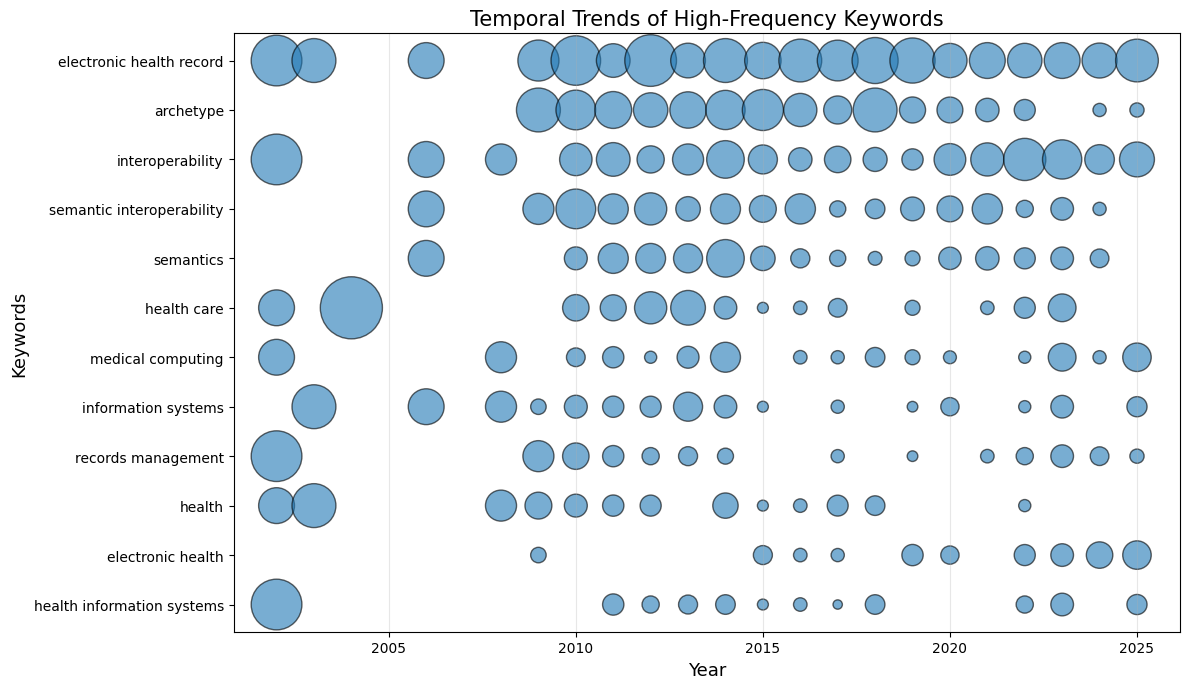

In [10]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET, keyword_map, unwanted_keywords
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
TOP_N_KEYWORDS = 12
YEAR_MIN = 2002
YEAR_MAX = 2025

df = DATASET()

# Helper
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return []
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except:
        return []

def clean_keywords(values):
    cleaned = []

    for value in values:
        if pd.isna(value):
            continue

        keyword = str(value).strip()
        if keyword == "":
            continue

        keyword_lower = keyword.lower()

        # remove unwanted
        if keyword_lower in unwanted_keywords():
            continue

        # normalize
        keyword_normalized = keyword_map().get(keyword_lower, keyword_lower).strip()

        if keyword_normalized in unwanted_keywords():
            continue

        cleaned.append(keyword_normalized)

    return list(dict.fromkeys(cleaned))

# Load
df["keywords"] = df["keywords"].apply(safe_eval).apply(clean_keywords)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)]
df = df[df["keywords"].apply(len) > 0]

# Top keywords
keyword_freq = (
    df.explode("keywords")["keywords"]
    .value_counts()
    .head(TOP_N_KEYWORDS)
)

top_keywords = keyword_freq.index.tolist()

# Build dataset
records = []

for year in sorted(df["year"].unique()):
    df_year = df[df["year"] == year]
    total_articles = len(df_year)

    counts = df_year.explode("keywords")["keywords"].value_counts()

    for kw in top_keywords:
        count = counts.get(kw, 0)

        if count == 0:
            continue

        normalized = count / total_articles

        records.append({
            "Year": year,
            "Keyword": kw,
            "Count": count,
            "Normalized": normalized
        })

trend_df = pd.DataFrame(records)

dataframe_to_csv(trend_df, "temporal_keyword_trends_bubble.csv")

# Bubble Plot
plt.figure(figsize=(12, 7))

# map keywords to y-axis positions
keyword_order = list(reversed(top_keywords))
y_map = {kw: i for i, kw in enumerate(keyword_order)}

x = trend_df["Year"]
y = trend_df["Keyword"].map(y_map)

# bubble size (خیلی مهم برای زیبایی)
sizes = trend_df["Normalized"] * 2000  # adjust scale if needed

plt.scatter(
    x,
    y,
    s=sizes,
    alpha=0.6,
    edgecolors="black"
)

# y labels
plt.yticks(
    list(y_map.values()),
    keyword_order
)

plt.xlabel("Year", fontsize=13)
plt.ylabel("Keywords", fontsize=13)
plt.title("Temporal Trends of High-Frequency Keywords", fontsize=15)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt_savefig(plt, "temporal_keyword_trends_bubble.png")

plt.show()
plt.close()

### Temporal Trends of Top Growing Keywords
To identify emerging conceptual trends, keywords were ranked according to the slope of their normalized yearly frequencies over time. After keyword normalization and filtering, annual keyword frequencies were divided by the total number of publications in each year, and a linear trend was fitted for each keyword across the study period. The highest-ranking positively sloped keywords were then visualized using a bubble chart, where bubble size represents normalized yearly prominence.

✅ `keyword_analysis_yearly_publication_totals.csv` as CSV saved. 
✅ `keyword_year_normalized_frequencies_all.csv` as CSV saved. 
✅ `keyword_growth_statistics.csv` as CSV saved. 
✅ `top_growing_keywords.csv` as CSV saved. 
✅ `temporal_top_growing_keywords_bubble.csv` as CSV saved. 


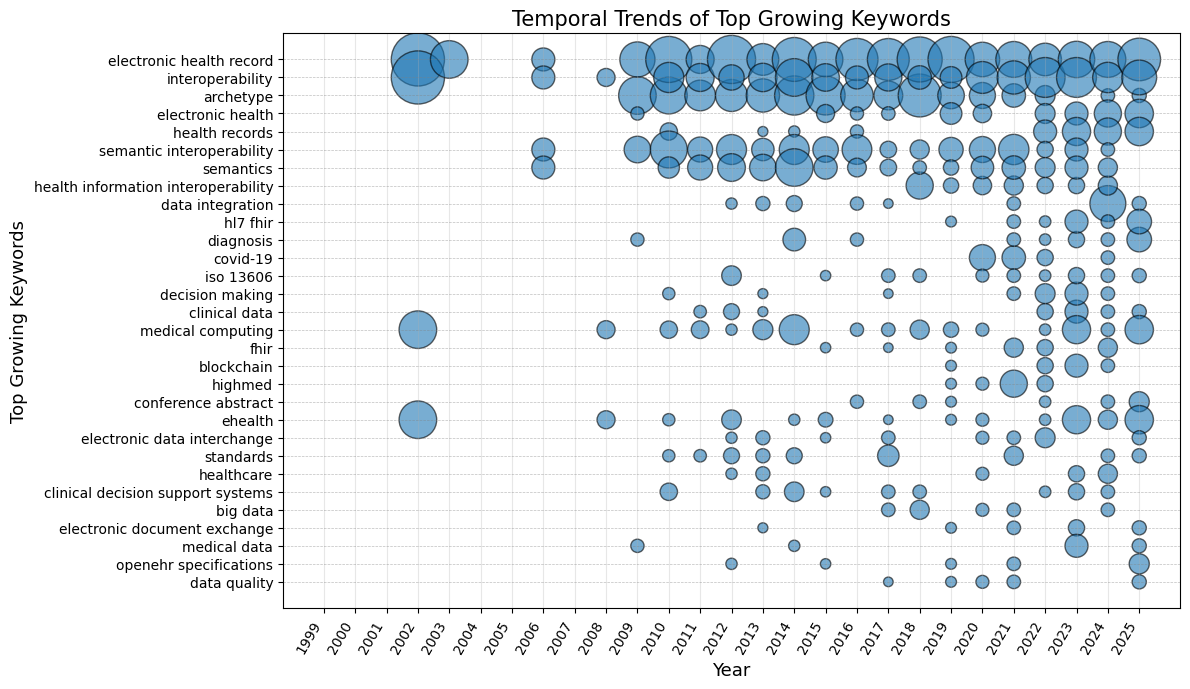

The keyword with the strongest positive temporal trend was 'electronic health record', with a slope of 0.011008 in normalized yearly frequency (R²=0.189, p=0.02663).


In [15]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

from src.lib_dataset import DATASET, keyword_map, unwanted_keywords
from src.lib_visualization import plt_savefig, dataframe_to_csv


# ============================================================
# Settings
# ============================================================

TOP_N_GROWING_KEYWORDS = 30
MIN_TOTAL_FREQ = 5
MIN_YEARS_PRESENT = 4

YEAR_MIN = 1999
YEAR_MAX = 2025

BUBBLE_SCALE = 2200


# ============================================================
# Load dataset
# ============================================================

df = DATASET().copy()


required_columns = {"year", "keywords"}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Required column(s) missing from dataset: "
        f"{sorted(missing_columns)}"
    )


# ============================================================
# Prepare keyword normalization resources
# ============================================================

KEYWORD_MAP = {
    str(key).strip().lower(): str(value).strip()
    for key, value in keyword_map().items()
}


UNWANTED_KEYWORDS = {
    str(keyword).strip().lower()
    for keyword in unwanted_keywords()
}


# ============================================================
# Helper functions
# ============================================================

def safe_eval(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if not isinstance(value, str):
        return []

    value = value.strip()

    if value == "":
        return []

    try:

        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, (tuple, set)):
            return list(parsed)

        return [parsed]

    except (ValueError, SyntaxError):

        return []


def clean_keywords(values):

    cleaned = []
    seen = set()

    for value in values:

        if pd.isna(value):
            continue

        keyword = str(value).strip()

        if keyword == "":
            continue

        keyword_lower = keyword.lower()


        # --------------------------------------------
        # Remove unwanted keywords before normalization
        # --------------------------------------------

        if keyword_lower in UNWANTED_KEYWORDS:
            continue


        # --------------------------------------------
        # Normalize synonyms / variants
        # --------------------------------------------

        keyword_normalized = KEYWORD_MAP.get(
            keyword_lower,
            keyword_lower
        ).strip()


        if keyword_normalized == "":
            continue


        # --------------------------------------------
        # Remove unwanted keywords after normalization
        # --------------------------------------------

        if keyword_normalized.lower() in UNWANTED_KEYWORDS:
            continue


        # --------------------------------------------
        # Each keyword should be counted only once
        # within a publication
        # --------------------------------------------

        dedup_key = keyword_normalized.lower()

        if dedup_key not in seen:

            seen.add(dedup_key)

            cleaned.append(
                keyword_normalized
            )


    return cleaned


# ============================================================
# Create publication identifier
# ============================================================

df = df.reset_index(drop=True)


if "DBUID" in df.columns:

    publication_id = (
        df["DBUID"]
        .astype("string")
        .str.strip()
    )

    missing_id = (
        publication_id.isna()
        |
        publication_id.eq("")
    )

    df["_publication_id"] = publication_id.astype(object)


    # Rows without DBUID receive a unique row-based identifier
    df.loc[
        missing_id,
        "_publication_id"
    ] = [

        f"__row_{i}"

        for i in df.index[missing_id]

    ]


else:

    df["_publication_id"] = [

        f"__row_{i}"

        for i in df.index

    ]


# ============================================================
# Clean publication year
# ============================================================

df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)


df = df.dropna(
    subset=["year"]
).copy()


df["year"] = df["year"].astype(int)


df = df[
    (df["year"] >= YEAR_MIN)
    &
    (df["year"] <= YEAR_MAX)
].copy()


if df.empty:

    raise ValueError(
        "No publications remained in the specified year range."
    )


# ============================================================
# Clean keywords
# ============================================================

df["keywords"] = (
    df["keywords"]
    .apply(safe_eval)
    .apply(clean_keywords)
)


# ============================================================
# Check publication-year consistency
# ============================================================

year_per_publication = (
    df.groupby("_publication_id")["year"]
    .nunique()
)


if (year_per_publication > 1).any():

    bad_ids = (
        year_per_publication[
            year_per_publication > 1
        ]
        .index
        .tolist()[:10]
    )

    raise ValueError(
        "Some publication IDs are associated with more than "
        "one publication year. "
        f"Examples: {bad_ids}"
    )


# ============================================================
# Yearly publication totals
# ============================================================
#
# IMPORTANT:
#
# The denominator is ALL publications in a year,
# not only publications containing valid keywords.
#
# ============================================================

calendar_years = np.arange(
    YEAR_MIN,
    YEAR_MAX + 1
)


yearly_totals = (
    df
    .groupby("year")["_publication_id"]
    .nunique()
    .reindex(
        calendar_years,
        fill_value=0
    )
    .rename("Total_Articles")
    .rename_axis("Year")
    .reset_index()
)


dataframe_to_csv(
    yearly_totals,
    "keyword_analysis_yearly_publication_totals.csv"
)


# ============================================================
# Create publication-keyword table
# ============================================================

keyword_long = (
    df[
        [
            "_publication_id",
            "year",
            "keywords"
        ]
    ]
    .explode("keywords")
    .rename(
        columns={
            "year": "Year",
            "keywords": "Keyword"
        }
    )
    .dropna(
        subset=["Keyword"]
    )
)


keyword_long["Keyword"] = (
    keyword_long["Keyword"]
    .astype(str)
    .str.strip()
)


keyword_long = keyword_long[
    keyword_long["Keyword"] != ""
].copy()


# ============================================================
# Prevent duplicate counting
# ============================================================
#
# A publication contributes at most once
# to a keyword in a given year.
#
# ============================================================

keyword_long = (
    keyword_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "Year",
            "Keyword"
        ]
    )
)


if keyword_long.empty:

    raise ValueError(
        "No valid keyword data remained after preprocessing."
    )


# ============================================================
# Keyword-year document counts
# ============================================================

keyword_year_counts = (
    keyword_long
    .groupby(
        ["Year", "Keyword"],
        as_index=False
    )
    .agg(
        Count=(
            "_publication_id",
            "nunique"
        )
    )
)


all_keywords = sorted(
    keyword_year_counts[
        "Keyword"
    ]
    .unique()
    .tolist()
)


if not all_keywords:

    raise ValueError(
        "No keywords were available for temporal trend analysis."
    )


# ============================================================
# Create COMPLETE Year × Keyword matrix
# ============================================================
#
# THIS IS THE MAIN CORRECTION.
#
# Example:
#
#           2010   2011   2012   2013
# keyword      0      0      3      5
#
# In the previous version, 2010 and 2011 were absent
# from the regression.
#
# Here they are explicitly represented as zero.
#
# ============================================================

full_index = pd.MultiIndex.from_product(
    [
        calendar_years,
        all_keywords
    ],
    names=[
        "Year",
        "Keyword"
    ]
)


trend_df = (
    keyword_year_counts
    .set_index(
        ["Year", "Keyword"]
    )
    .reindex(
        full_index,
        fill_value=0
    )
    .reset_index()
)


# Add total number of publications per year

trend_df = trend_df.merge(
    yearly_totals,
    on="Year",
    how="left"
)


trend_df["Count"] = (
    trend_df["Count"]
    .astype(int)
)


trend_df["Total_Articles"] = (
    trend_df["Total_Articles"]
    .astype(int)
)


# ============================================================
# Normalized keyword frequency
# ============================================================
#
# Normalized frequency:
#
# Number of publications containing keyword
# -----------------------------------------
# Total publications in that year
#
#
# IMPORTANT:
#
# If a year contains publications but the keyword does not
# occur:
#
#     Normalized_Frequency = 0
#
# If the year contains NO publications:
#
#     Normalized_Frequency = NaN
#
# because 0 / 0 is undefined.
#
# ============================================================

trend_df["Normalized_Frequency"] = np.where(

    trend_df["Total_Articles"] > 0,

    trend_df["Count"]
    /
    trend_df["Total_Articles"],

    np.nan

)


# ============================================================
# Save complete normalized-frequency dataset
# ============================================================

dataframe_to_csv(
    trend_df,
    "keyword_year_normalized_frequencies_all.csv"
)


# ============================================================
# Compute temporal growth slopes
# ============================================================

growth_rows = []


for keyword, subset in trend_df.groupby("Keyword"):

    subset = (
        subset
        .sort_values("Year")
        .copy()
    )


    # --------------------------------------------------------
    # Total number of publications containing keyword
    # --------------------------------------------------------

    total_freq = int(
        subset["Count"].sum()
    )


    # --------------------------------------------------------
    # Number of years in which keyword actually appeared
    # --------------------------------------------------------

    years_present = int(
        (subset["Count"] > 0).sum()
    )


    # --------------------------------------------------------
    # Minimum-frequency criteria
    # --------------------------------------------------------

    if total_freq < MIN_TOTAL_FREQ:
        continue


    if years_present < MIN_YEARS_PRESENT:
        continue


    # --------------------------------------------------------
    # Regression dataset
    # --------------------------------------------------------
    #
    # Keep every year that had publications.
    #
    # A keyword absent in that year stays as frequency = 0.
    #
    # Years with zero TOTAL publications are excluded because
    # normalized frequency is undefined.
    #
    # --------------------------------------------------------

    regression_df = subset[
        subset["Total_Articles"] > 0
    ].copy()


    if len(regression_df) < 2:
        continue


    x = (
        regression_df["Year"]
        .to_numpy(dtype=float)
    )


    y = (
        regression_df[
            "Normalized_Frequency"
        ]
        .to_numpy(dtype=float)
    )


    # --------------------------------------------------------
    # Linear temporal trend
    # --------------------------------------------------------

    result = linregress(
        x,
        y
    )


    first_year_present = int(
        subset.loc[
            subset["Count"] > 0,
            "Year"
        ].min()
    )


    last_year_present = int(
        subset.loc[
            subset["Count"] > 0,
            "Year"
        ].max()
    )


    growth_rows.append(
        {

            "Keyword":
                keyword,

            "Total_Count":
                total_freq,

            "Years_Present":
                years_present,

            "Years_Analyzed":
                int(len(regression_df)),

            "First_Year_Present":
                first_year_present,

            "Last_Year_Present":
                last_year_present,

            "Slope":
                float(result.slope),

            "Intercept":
                float(result.intercept),

            "R_squared":
                float(result.rvalue ** 2),

            "P_value":
                float(result.pvalue),

            "Std_Error":
                float(result.stderr),

            "Max_Normalized_Frequency":
                float(
                    regression_df[
                        "Normalized_Frequency"
                    ].max()
                ),

            "Mean_Normalized_Frequency":
                float(
                    regression_df[
                        "Normalized_Frequency"
                    ].mean()
                ),

        }
    )


# ============================================================
# Growth statistics dataframe
# ============================================================

growth_df = pd.DataFrame(
    growth_rows
)


if growth_df.empty:

    raise ValueError(
        "No keyword growth statistics could be computed."
    )


growth_df = (
    growth_df
    .sort_values(
        [
            "Slope",
            "Total_Count"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


dataframe_to_csv(
    growth_df,
    "keyword_growth_statistics.csv"
)


# ============================================================
# Select positively growing keywords
# ============================================================

top_growing_df = (
    growth_df[
        growth_df["Slope"] > 0
    ]
    .head(
        TOP_N_GROWING_KEYWORDS
    )
    .copy()
)


if top_growing_df.empty:

    raise ValueError(
        "No positively growing keywords were identified."
    )


top_keywords = (
    top_growing_df[
        "Keyword"
    ]
    .tolist()
)


dataframe_to_csv(
    top_growing_df,
    "top_growing_keywords.csv"
)


# ============================================================
# Data for bubble plot
# ============================================================
#
# trend_df is already complete:
#
# Year × Keyword
#
# Therefore no second reindex operation is required.
#
# ============================================================

plot_df = trend_df[
    trend_df[
        "Keyword"
    ].isin(
        top_keywords
    )
].copy()


dataframe_to_csv(
    plot_df,
    "temporal_top_growing_keywords_bubble.csv"
)


# ============================================================
# Bubble plot
# ============================================================

plt.figure(
    figsize=(12, 7)
)


keyword_order = (
    top_growing_df
    .sort_values(
        "Slope",
        ascending=True
    )
    ["Keyword"]
    .tolist()
)


y_map = {

    keyword: i

    for i, keyword
    in enumerate(
        keyword_order
    )

}


x = plot_df["Year"]

y = (
    plot_df["Keyword"]
    .map(y_map)
)


# ============================================================
# Bubble size
# ============================================================
#
# NaN occurs only if a year contains zero publications.
# Such years should have no visible bubble.
#
# ============================================================

sizes = (
    plot_df[
        "Normalized_Frequency"
    ]
    .fillna(0)
    *
    BUBBLE_SCALE
)


plt.scatter(
    x,
    y,
    s=sizes,
    alpha=0.6,
    edgecolors="black"
)


# ============================================================
# Horizontal guides
# ============================================================

for y_pos in y_map.values():

    plt.axhline(
        y=y_pos,
        color="gray",
        linestyle="--",
        linewidth=0.5,
        alpha=0.5
    )


# ============================================================
# Axis settings
# ============================================================

plt.yticks(
    list(
        y_map.values()
    ),
    keyword_order
)


plt.xlabel(
    "Year",
    fontsize=13
)


plt.ylabel(
    "Top Growing Keywords",
    fontsize=13
)


plt.title(
    "Temporal Trends of Top Growing Keywords",
    fontsize=15
)


plt.xticks(
    calendar_years,
    rotation=60,
    ha="right"
)


plt.grid(
    axis="x",
    alpha=0.3
)


plt.tight_layout()


# ============================================================
# Save plot
# ============================================================

plt_savefig(
    plt,
    "temporal_top_growing_keywords_bubble.png"
)


plt.show()

plt.close()


# ============================================================
# Main result
# ============================================================

top_row = (
    top_growing_df
    .iloc[0]
)


print(
    f"The keyword with the strongest positive temporal trend was "
    f"'{top_row['Keyword']}', "
    f"with a slope of {top_row['Slope']:.6f} "
    f"in normalized yearly frequency "
    f"(R²={top_row['R_squared']:.3f}, "
    f"p={top_row['P_value']:.4g})."
)

### Decomposition of Thematic Diversity (Richness and Evenness)
To further interpret thematic diversity, the Shannon index was decomposed into richness and evenness components. Richness was defined as the number of distinct thematic categories observed in each year, while evenness was calculated as the normalized Shannon index, reflecting the balance of thematic distribution. This decomposition enables a more nuanced understanding of whether increases in diversity are driven by the expansion of thematic scope or by a more even distribution of research efforts across existing themes.


✅ `thematic_diversity_decomposition.csv` as CSV saved. 


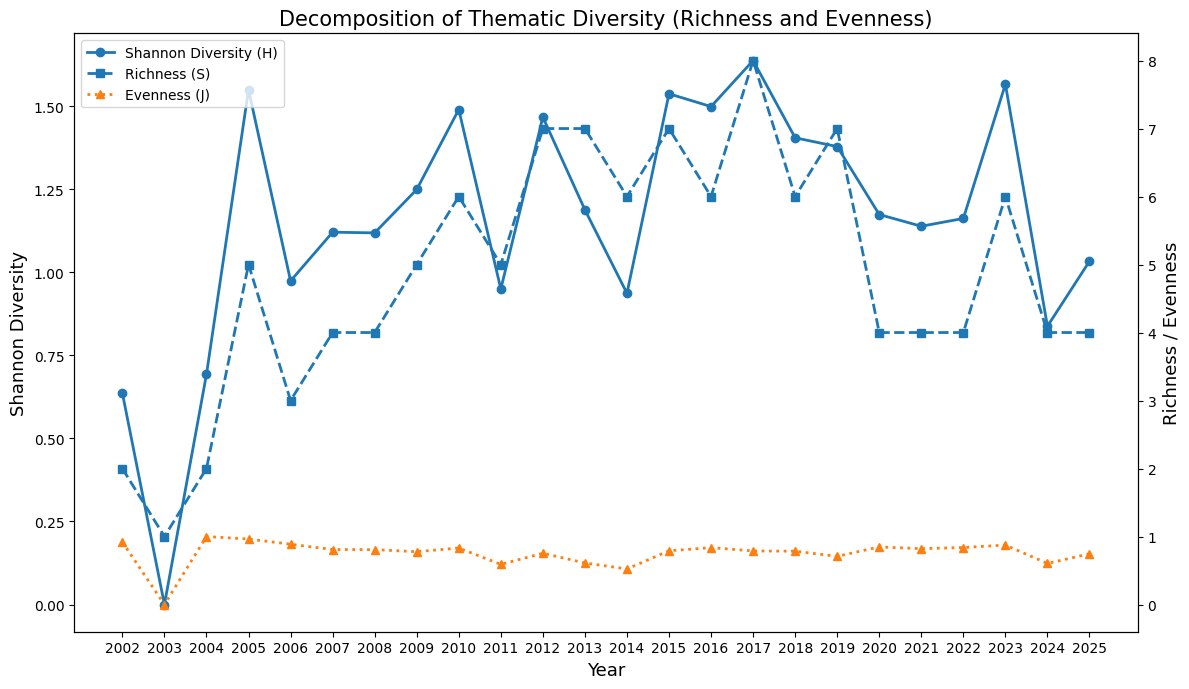

In [13]:
import ast
import math
import pandas as pd
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
YEAR_MIN = 2002
YEAR_MAX = 2025

CATEGORY_COL = "assigned_category"

df = DATASET()
df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

# Helper
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return []
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except:
        return []

def clean(values):
    return list(dict.fromkeys([
        str(v).strip()
        for v in values
        if pd.notna(v) and str(v).strip() != ""
    ]))

# Load
if CATEGORY_COL not in df.columns:
    raise ValueError(f"Column '{CATEGORY_COL}' is required.")

df["categories"] = df[CATEGORY_COL].apply(safe_eval).apply(clean)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)]
df = df[df["categories"].apply(len) > 0]

if df.empty:
    raise ValueError("No valid data for diversity decomposition.")

# Compute metrics
records = []

for year in sorted(df["year"].unique()):
    df_year = df[df["year"] == year]

    counts = (
        df_year.explode("categories")["categories"]
        .value_counts()
    )

    total = counts.sum()

    if total == 0:
        continue

    probs = counts / total

    # Shannon entropy
    H = -sum(p * math.log(p) for p in probs if p > 0)

    # Richness
    S = len(counts)

    # Evenness
    J = H / math.log(S) if S > 1 else 0

    records.append({
        "Year": year,
        "Shannon_Diversity": H,
        "Richness": S,
        "Evenness": J,
        "Total_Observations": int(total)
    })

div_df = pd.DataFrame(records)

dataframe_to_csv(div_df, "thematic_diversity_decomposition.csv")

# Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

# Shannon diversity
ax1.plot(
    div_df["Year"],
    div_df["Shannon_Diversity"],
    marker="o",
    linewidth=2,
    label="Shannon Diversity (H)"
)

ax1.set_xlabel("Year", fontsize=13)
ax1.set_ylabel("Shannon Diversity", fontsize=13)

# second axis
ax2 = ax1.twinx()

ax2.plot(
    div_df["Year"],
    div_df["Richness"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Richness (S)"
)

ax2.plot(
    div_df["Year"],
    div_df["Evenness"],
    marker="^",
    linestyle=":",
    linewidth=2,
    label="Evenness (J)"
)

ax2.set_ylabel("Richness / Evenness", fontsize=13)

# legend
lines = ax1.get_lines() + ax2.get_lines()
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Decomposition of Thematic Diversity (Richness and Evenness)", fontsize=15)
plt.xticks(div_df["Year"], rotation=60)
plt.tight_layout()

plt_savefig(plt, "thematic_diversity_decomposition.png")

plt.show()
plt.close()

The decomposition of thematic diversity indicates that the overall increase in Shannon diversity over time is primarily driven by fluctuations in thematic richness rather than substantial changes in evenness. Specifically, richness (S) shows a gradual upward trend with intermittent declines, reflecting the progressive introduction of new thematic categories into the field. In contrast, evenness (J) remains consistently low and relatively stable throughout the study period, suggesting that research output continues to be concentrated within a limited number of dominant themes.

Notably, periods of higher diversity—such as around 2009–2010 and 2016–2018—correspond to peaks in richness, indicating temporary expansions in thematic scope. However, the persistently low evenness values imply that these expansions did not translate into a balanced distribution of research activity across themes. Instead, a small number of categories continue to dominate the field.

Overall, these findings suggest that while the thematic landscape of archetype-based standards research has broadened over time, it remains structurally skewed toward a few central domains, with limited diffusion of attention across emerging areas.

## Network and Thematic Structures

### Keyword Co-occurrence Network (VOSviewer Visualization)
A keyword co-occurrence network was constructed to identify relationships between concepts. Nodes represent keywords and edges indicate co-occurrence frequency, revealing major thematic clusters.

| Parameter | Recommended Value |
|---|---|
|Unique keyword forms before cleaning| 2132|
|Unique keywords after cleaning| 1673|
|document-frequency threshold |(>= 5 documents)|
| Normalization | Association Strength |
| Attraction | 2 |
| Repulsion | 1 |
| Clustering Resolution | 1.00 |
| Minimum Cluster Size | 3 |
| Merge Small Clusters | On |
| Advanced Parameters | Leave unchanged |
| Edge weight | 2 |
| Node  | 126  |
| Edge  | 939 |
| Clusters  | 17 |

In [1]:
import ast
import json
import random
from collections import Counter
from itertools import combinations

import networkx as nx
import pandas as pd

from src.config import OUTPUT_DIR
from src.lib_dataset import (
    DATASET,
    keyword_map,
    unwanted_keywords,
)
from src.lib_visualization import dataframe_to_csv


# ============================================================
# Settings
# ============================================================

MIN_DOCUMENT_FREQUENCY = 5
MIN_EDGE_WEIGHT = 2
RANDOM_SEED = 42

CLEANED_KEYWORDS_FILENAME = "all_cleaned_keywords.csv"
RAW_KEYWORDS_FILENAME = "all_raw_keywords_before_cleaning.csv"
NETWORK_KEYWORDS_FILENAME = "keywords_in_cooccurrence_network.csv"

SUMMARY_FILENAME = "keyword_cleaning_summary.csv"

MATRIX_FILENAME = "keywords_co_occurrence_matrix.csv"
EDGE_FILENAME = "keyword_co_occurrence_edges.csv"
NODE_FILENAME = "keyword_co_occurrence_nodes.csv"

JSON_FILENAME = "vos_viewer_keyword_co_occurrence.json"


# ============================================================
# Reproducibility
# ============================================================

random.seed(RANDOM_SEED)


# ============================================================
# Load dataset
# ============================================================

df = DATASET().copy()
df = df.reset_index(drop=True)


# ============================================================
# Required column
# ============================================================

if "keywords" not in df.columns:

    raise ValueError(
        "Column 'keywords' is required "
        "for keyword co-occurrence analysis."
    )


# ============================================================
# Publication identifier
# ============================================================
#
# DBUID is preferred.
#
# If DBUID is unavailable or missing,
# a unique row-based identifier is created.
#
# ============================================================

if "DBUID" in df.columns:

    publication_id = (
        df["DBUID"]
        .astype("string")
        .str.strip()
    )

    missing_id = (
        publication_id.isna()
        | publication_id.eq("")
    )

    df["_publication_id"] = (
        publication_id.astype(object)
    )

    df.loc[
        missing_id,
        "_publication_id"
    ] = [
        f"__row_{i}"
        for i in df.index[missing_id]
    ]

else:

    df["_publication_id"] = [
        f"__row_{i}"
        for i in df.index
    ]


# ============================================================
# Prepare keyword normalization resources
# ============================================================
#
# Call keyword_map() and unwanted_keywords()
# only once.
#
# ============================================================

KEYWORD_MAP = {
    str(key).strip().lower():
        str(value).strip().lower()

    for key, value
    in keyword_map().items()
}


UNWANTED_KEYWORDS = {
    str(keyword).strip().lower()

    for keyword
    in unwanted_keywords()
}


# ============================================================
# Helper: safely convert keyword field to list
# ============================================================

def safe_eval_list(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if pd.isna(value):
        return []

    if not isinstance(value, str):
        return [value]

    value = value.strip()

    if value == "":
        return []

    try:

        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, (tuple, set)):
            return list(parsed)

        return [parsed]

    except (ValueError, SyntaxError):

        # Keep an ordinary string as a single keyword
        return [value]


# ============================================================
# Parse raw keyword lists
# ============================================================

df["_raw_keywords"] = (
    df["keywords"]
    .apply(safe_eval_list)
)


# ============================================================
# Helper: minimally clean raw keyword forms
# ============================================================
#
# This is ONLY for counting keywords before full cleaning.
#
# We remove:
# - missing values
# - empty values
# - repeated whitespace
#
# We DO NOT:
# - lowercase
# - use keyword_map()
# - remove unwanted_keywords()
#
# Therefore this represents the raw vocabulary before
# normalization and exclusion.
#
# ============================================================

def prepare_raw_keywords(values):

    raw = []

    for value in values:

        if pd.isna(value):
            continue

        keyword = str(value).strip()

        if keyword == "":
            continue

        keyword = " ".join(
            keyword.split()
        )

        raw.append(keyword)

    return raw


df["_raw_keywords_prepared"] = (
    df["_raw_keywords"]
    .apply(prepare_raw_keywords)
)


# ============================================================
# Raw keyword statistics BEFORE cleaning
# ============================================================

raw_keyword_long = (
    df[
        [
            "_publication_id",
            "_raw_keywords_prepared"
        ]
    ]
    .explode(
        "_raw_keywords_prepared"
    )
    .rename(
        columns={
            "_raw_keywords_prepared":
                "Raw_Keyword"
        }
    )
    .dropna(
        subset=["Raw_Keyword"]
    )
)


raw_keyword_long = raw_keyword_long[
    raw_keyword_long["Raw_Keyword"] != ""
].copy()


# Total raw keyword assignments
n_raw_assignments = len(
    raw_keyword_long
)


# Number of unique raw keyword forms
#
# Case-sensitive here intentionally:
# "EHR" and "ehr" are different raw forms.
#
n_unique_raw_keywords = (
    raw_keyword_long[
        "Raw_Keyword"
    ]
    .nunique()
)


# ============================================================
# Raw keyword frequency table
# ============================================================

raw_keyword_frequency_df = (
    raw_keyword_long
    .groupby(
        "Raw_Keyword",
        as_index=False
    )
    .agg(
        Document_Frequency=(
            "_publication_id",
            "nunique"
        ),
        Total_Occurrences=(
            "_publication_id",
            "size"
        )
    )
    .sort_values(
        [
            "Document_Frequency",
            "Total_Occurrences",
            "Raw_Keyword"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


dataframe_to_csv(
    raw_keyword_frequency_df,
    RAW_KEYWORDS_FILENAME
)


# ============================================================
# Keyword cleaning and normalization
# ============================================================
#
# Cleaning sequence:
#
# 1. Remove missing / empty values
# 2. Trim whitespace
# 3. Lowercase
# 4. Remove unwanted raw keywords
# 5. Normalize synonyms/variants with keyword_map()
# 6. Remove unwanted keywords again after mapping
# 7. Deduplicate within each publication
#
# ============================================================

def clean_keywords(values):

    cleaned = []
    seen = set()

    for value in values:

        if pd.isna(value):
            continue

        keyword = str(value).strip()

        if keyword == "":
            continue

        # Collapse repeated whitespace
        keyword = " ".join(
            keyword.split()
        )

        # Standard case
        keyword_lower = (
            keyword.lower()
        )


        # ----------------------------------------------------
        # Remove unwanted raw keyword
        # ----------------------------------------------------

        if keyword_lower in UNWANTED_KEYWORDS:
            continue


        # ----------------------------------------------------
        # Normalize synonymous forms
        # ----------------------------------------------------

        keyword_normalized = (
            KEYWORD_MAP.get(
                keyword_lower,
                keyword_lower
            )
        )


        keyword_normalized = (
            str(keyword_normalized)
            .strip()
            .lower()
        )


        keyword_normalized = (
            " ".join(
                keyword_normalized.split()
            )
        )


        if keyword_normalized == "":
            continue


        # ----------------------------------------------------
        # Remove unwanted normalized keyword
        # ----------------------------------------------------

        if (
            keyword_normalized
            in UNWANTED_KEYWORDS
        ):
            continue


        # ----------------------------------------------------
        # Deduplicate within publication
        # ----------------------------------------------------

        if keyword_normalized in seen:
            continue

        seen.add(
            keyword_normalized
        )

        cleaned.append(
            keyword_normalized
        )

    return cleaned


# ============================================================
# Apply keyword cleaning
# ============================================================

df["keywords_cleaned"] = (
    df["_raw_keywords"]
    .apply(clean_keywords)
)


# ============================================================
# Create publication-keyword long table AFTER cleaning
# ============================================================

clean_keyword_long = (
    df[
        [
            "_publication_id",
            "keywords_cleaned"
        ]
    ]
    .explode(
        "keywords_cleaned"
    )
    .rename(
        columns={
            "keywords_cleaned":
                "Keyword"
        }
    )
    .dropna(
        subset=["Keyword"]
    )
)


clean_keyword_long = clean_keyword_long[
    clean_keyword_long["Keyword"] != ""
].copy()


# Safety check:
# each publication-keyword pair should appear only once

clean_keyword_long = (
    clean_keyword_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "Keyword"
        ]
    )
)


if clean_keyword_long.empty:

    raise ValueError(
        "No valid keywords remained after cleaning."
    )


# ============================================================
# Keyword statistics AFTER cleaning
# ============================================================

n_clean_assignments = len(
    clean_keyword_long
)


n_unique_clean_keywords = (
    clean_keyword_long[
        "Keyword"
    ]
    .nunique()
)


# ============================================================
# COMPLETE list of ALL cleaned keywords
# ============================================================
#
# This is BEFORE applying MIN_DOCUMENT_FREQUENCY.
#
# Therefore this file contains the full cleaned vocabulary.
#
# ============================================================

cleaned_keyword_frequency_df = (
    clean_keyword_long
    .groupby(
        "Keyword",
        as_index=False
    )
    .agg(
        Document_Frequency=(
            "_publication_id",
            "nunique"
        )
    )
    .sort_values(
        [
            "Document_Frequency",
            "Keyword"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


cleaned_keyword_frequency_df.insert(
    0,
    "Rank",
    range(
        1,
        len(
            cleaned_keyword_frequency_df
        ) + 1
    )
)


dataframe_to_csv(
    cleaned_keyword_frequency_df,
    CLEANED_KEYWORDS_FILENAME
)


# ============================================================
# Keyword cleaning summary
# ============================================================

keyword_reduction_n = (
    n_unique_raw_keywords
    -
    n_unique_clean_keywords
)


keyword_reduction_pct = (
    100
    * keyword_reduction_n
    / n_unique_raw_keywords

    if n_unique_raw_keywords > 0

    else 0.0
)


assignment_reduction_n = (
    n_raw_assignments
    -
    n_clean_assignments
)


assignment_reduction_pct = (
    100
    * assignment_reduction_n
    / n_raw_assignments

    if n_raw_assignments > 0

    else 0.0
)


summary_df = pd.DataFrame(
    {
        "Metric": [

            "Raw unique keyword forms",
            "Cleaned unique keywords",

            "Reduction in unique vocabulary",
            "Reduction in unique vocabulary (%)",

            "Raw keyword assignments",
            "Cleaned document-keyword assignments",

            "Reduction in keyword assignments",
            "Reduction in keyword assignments (%)",
        ],

        "Value": [

            n_unique_raw_keywords,
            n_unique_clean_keywords,

            keyword_reduction_n,
            round(
                keyword_reduction_pct,
                2
            ),

            n_raw_assignments,
            n_clean_assignments,

            assignment_reduction_n,
            round(
                assignment_reduction_pct,
                2
            ),
        ]
    }
)


dataframe_to_csv(
    summary_df,
    SUMMARY_FILENAME
)


# ============================================================
# Print cleaning summary
# ============================================================

print(
    "\n=== Keyword Cleaning Summary ==="
)


print(
    f"Unique keyword forms before cleaning: "
    f"{n_unique_raw_keywords}"
)


print(
    f"Unique keywords after cleaning: "
    f"{n_unique_clean_keywords}"
)


print(
    f"Reduction in unique keyword vocabulary: "
    f"{keyword_reduction_n} "
    f"({keyword_reduction_pct:.1f}%)"
)


print(
    f"Raw keyword assignments before cleaning: "
    f"{n_raw_assignments}"
)


print(
    f"Document-keyword assignments after cleaning: "
    f"{n_clean_assignments}"
)


print(
    f"Reduction in keyword assignments: "
    f"{assignment_reduction_n} "
    f"({assignment_reduction_pct:.1f}%)"
)


# ============================================================
# Manuscript-ready sentence
# ============================================================

manuscript_text = (

    f"Before keyword cleaning, the dataset contained "
    f"{n_unique_raw_keywords:,} unique raw keyword forms. "
    f"After case normalization, synonym harmonization using "
    f"the predefined keyword mapping, removal of unwanted terms, "
    f"and within-publication deduplication, "
    f"{n_unique_clean_keywords:,} unique keywords remained, "
    f"representing a {keyword_reduction_pct:.1f}% reduction "
    f"in vocabulary size."

)


print(
    "\nManuscript-ready text:"
)

print(
    manuscript_text
)


# ============================================================
# Document frequency threshold for NETWORK only
# ============================================================
#
# IMPORTANT:
#
# The cleaned vocabulary above is NOT filtered.
#
# MIN_DOCUMENT_FREQUENCY is applied only to determine which
# keywords enter the co-occurrence network.
#
# ============================================================

network_keyword_df = (
    cleaned_keyword_frequency_df[
        cleaned_keyword_frequency_df[
            "Document_Frequency"
        ] >= MIN_DOCUMENT_FREQUENCY
    ]
    .copy()
)


if network_keyword_df.empty:

    raise ValueError(
        "No keywords remained after applying "
        f"MIN_DOCUMENT_FREQUENCY="
        f"{MIN_DOCUMENT_FREQUENCY}."
    )


allowed_keywords = set(
    network_keyword_df[
        "Keyword"
    ]
)


# ============================================================
# Save list of keywords eligible for network
# ============================================================

dataframe_to_csv(
    network_keyword_df,
    NETWORK_KEYWORDS_FILENAME
)


n_network_keywords_before_edge_filter = (
    len(
        network_keyword_df
    )
)


print(
    f"\nKeywords meeting document-frequency threshold "
    f"(>= {MIN_DOCUMENT_FREQUENCY} documents): "
    f"{n_network_keywords_before_edge_filter}"
)


# ============================================================
# Filter publication keyword lists for network
# ============================================================

df["network_keywords"] = (
    df["keywords_cleaned"]
    .apply(
        lambda values: [
            keyword
            for keyword in values
            if keyword in allowed_keywords
        ]
    )
)


# ============================================================
# Build co-occurrence edges manually
# ============================================================
#
# Edge weight =
# number of publications in which two distinct keywords
# co-occur.
#
# Each keyword can contribute only once per publication.
#
# ============================================================

edge_counter = Counter()


for keywords in df["network_keywords"]:

    keywords = sorted(
        set(
            keywords
        )
    )

    if len(keywords) < 2:
        continue


    for keyword_a, keyword_b in combinations(
        keywords,
        2
    ):

        edge_counter[
            (
                keyword_a,
                keyword_b
            )
        ] += 1


# ============================================================
# Edge dataframe
# ============================================================

edge_df = pd.DataFrame(
    [
        {
            "Source": source,
            "Target": target,
            "Weight": weight,
        }

        for (
            source,
            target
        ), weight
        in edge_counter.items()
    ]
)


if edge_df.empty:

    raise ValueError(
        "No keyword co-occurrence edges "
        "could be generated."
    )


edge_df = (
    edge_df
    .sort_values(
        [
            "Weight",
            "Source",
            "Target"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .reset_index(drop=True)
)


# Save ALL observed edges before edge filtering

dataframe_to_csv(
    edge_df,
    EDGE_FILENAME
)


# ============================================================
# Apply edge threshold
# ============================================================

filtered_edge_df = edge_df[
    edge_df["Weight"]
    >= MIN_EDGE_WEIGHT
].copy()


if filtered_edge_df.empty:

    raise ValueError(
        "No keyword co-occurrence edges remained "
        f"after applying MIN_EDGE_WEIGHT="
        f"{MIN_EDGE_WEIGHT}."
    )


# ============================================================
# Keyword document-frequency mapping
# ============================================================

keyword_frequency_map = dict(
    zip(
        cleaned_keyword_frequency_df[
            "Keyword"
        ],
        cleaned_keyword_frequency_df[
            "Document_Frequency"
        ]
    )
)


# ============================================================
# Build NetworkX graph
# ============================================================

G = nx.Graph()


# Add all threshold-eligible keywords first

for keyword in allowed_keywords:

    G.add_node(

        keyword,

        label=keyword,

        documents=int(
            keyword_frequency_map.get(
                keyword,
                0
            )
        ),
    )


# Add filtered edges

for _, row in filtered_edge_df.iterrows():

    G.add_edge(

        row["Source"],

        row["Target"],

        weight=int(
            row["Weight"]
        ),
    )


# ============================================================
# Remove isolates
# ============================================================
#
# Keywords with sufficient frequency but without any edge
# meeting MIN_EDGE_WEIGHT are excluded from the final network.
#
# ============================================================

isolates = list(
    nx.isolates(G)
)


G.remove_nodes_from(
    isolates
)


if G.number_of_nodes() == 0:

    raise ValueError(
        "No connected keywords remained "
        "after edge filtering."
    )


# ============================================================
# Final network node statistics
# ============================================================

node_rows = []


for node in G.nodes():

    weighted_degree = sum(

        G[node][neighbor].get(
            "weight",
            0
        )

        for neighbor
        in G.neighbors(node)

    )


    node_rows.append(
        {

            "Keyword":
                node,

            "Document_Frequency":
                int(
                    G.nodes[node].get(
                        "documents",
                        0
                    )
                ),

            "Degree":
                int(
                    G.degree(node)
                ),

            "Weighted_Degree":
                int(
                    weighted_degree
                ),
        }
    )


node_df = pd.DataFrame(
    node_rows
)


node_df = (
    node_df
    .sort_values(
        [
            "Weighted_Degree",
            "Document_Frequency",
            "Keyword"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


dataframe_to_csv(
    node_df,
    NODE_FILENAME
)


# ============================================================
# Build full co-occurrence matrix
# ============================================================
#
# Matrix includes all keywords that passed the document
# frequency threshold.
#
# Diagonal:
# document frequency of keyword
#
# Off-diagonal:
# number of documents in which the two keywords co-occurred
#
# ============================================================

matrix_keywords = (
    network_keyword_df[
        "Keyword"
    ]
    .tolist()
)


co_occurrence_matrix = pd.DataFrame(

    0,

    index=matrix_keywords,

    columns=matrix_keywords,

    dtype=int
)


# Diagonal = keyword document frequency

for keyword in matrix_keywords:

    co_occurrence_matrix.loc[
        keyword,
        keyword
    ] = int(
        keyword_frequency_map.get(
            keyword,
            0
        )
    )


# Off-diagonal = co-occurrence frequency

for _, row in edge_df.iterrows():

    source = row["Source"]
    target = row["Target"]

    weight = int(
        row["Weight"]
    )


    if (
        source in co_occurrence_matrix.index
        and
        target in co_occurrence_matrix.columns
    ):

        co_occurrence_matrix.loc[
            source,
            target
        ] = weight

        co_occurrence_matrix.loc[
            target,
            source
        ] = weight


# ============================================================
# Save co-occurrence matrix
# ============================================================

matrix_export = (
    co_occurrence_matrix
    .reset_index()
    .rename(
        columns={
            "index":
                "Keyword"
        }
    )
)


dataframe_to_csv(
    matrix_export,
    MATRIX_FILENAME
)


# ============================================================
# Build reproducible VOSviewer-compatible JSON
# ============================================================

graph_data = {

    "network": {

        "items": [

            {

                "id":
                    node,

                "label":
                    node,

                "x":
                    round(
                        random.uniform(
                            -1.1515,
                            0.2000
                        ),
                        4
                    ),

                "y":
                    round(
                        random.uniform(
                            -1.1515,
                            0.2000
                        ),
                        4
                    ),

                # Node weight = document frequency
                "weight":
                    int(
                        G.nodes[node].get(
                            "documents",
                            0
                        )
                    ),

            }

            for node
            in G.nodes()

        ],

        "links": [

            {

                "source_id":
                    source,

                "target_id":
                    target,

                "strength":
                    int(
                        data["weight"]
                    ),

            }

            for (
                source,
                target,
                data
            )
            in G.edges(
                data=True
            )

        ],

    }

}


# ============================================================
# Save JSON
# ============================================================

json_path = (
    OUTPUT_DIR
    / JSON_FILENAME
)


with open(
    json_path,
    "w",
    encoding="utf-8"
) as outfile:

    json.dump(
        graph_data,
        outfile,
        indent=4,
        ensure_ascii=False
    )


print(
    f"\n`{JSON_FILENAME}` saved."
)


# ============================================================
# Final network summary
# ============================================================

print(
    "\n=== Keyword Co-occurrence Network Summary ==="
)


print(
    f"Unique raw keyword forms before cleaning: "
    f"{n_unique_raw_keywords}"
)


print(
    f"Unique keywords after cleaning: "
    f"{n_unique_clean_keywords}"
)


print(
    f"Keywords meeting document-frequency threshold "
    f"(>= {MIN_DOCUMENT_FREQUENCY}): "
    f"{n_network_keywords_before_edge_filter}"
)


print(
    f"Connected keywords in final network: "
    f"{G.number_of_nodes()}"
)


print(
    f"Observed keyword pairs before edge filtering: "
    f"{len(edge_df)}"
)


print(
    f"Edges retained with weight >= "
    f"{MIN_EDGE_WEIGHT}: "
    f"{G.number_of_edges()}"
)


# ============================================================
# Strongest keyword relationships
# ============================================================

print(
    "\nStrongest keyword co-occurrences:"
)


print(
    filtered_edge_df
    .head(20)
    .to_string(
        index=False
    )
)

✅ `all_raw_keywords_before_cleaning.csv` as CSV saved. 
✅ `all_cleaned_keywords.csv` as CSV saved. 
✅ `keyword_cleaning_summary.csv` as CSV saved. 

=== Keyword Cleaning Summary ===
Unique keyword forms before cleaning: 2132
Unique keywords after cleaning: 1673
Reduction in unique keyword vocabulary: 459 (21.5%)
Raw keyword assignments before cleaning: 4563
Document-keyword assignments after cleaning: 3820
Reduction in keyword assignments: 743 (16.3%)

Manuscript-ready text:
Before keyword cleaning, the dataset contained 2,132 unique raw keyword forms. After case normalization, synonym harmonization using the predefined keyword mapping, removal of unwanted terms, and within-publication deduplication, 1,673 unique keywords remained, representing a 21.5% reduction in vocabulary size.
✅ `keywords_in_cooccurrence_network.csv` as CSV saved. 

Keywords meeting document-frequency threshold (>= 5 documents): 126
✅ `keyword_co_occurrence_edges.csv` as CSV saved. 
✅ `keyword_co_occurrence_nodes.

![vos_viewer_keyword_co_occurrence](./output/vos_viewer_keyword_co_occurrence.png)

### Thematic Co-occurrence Heatmap
A heatmap was used to visualize co-occurrence frequencies between thematic categories, highlighting strong associations between research domains.

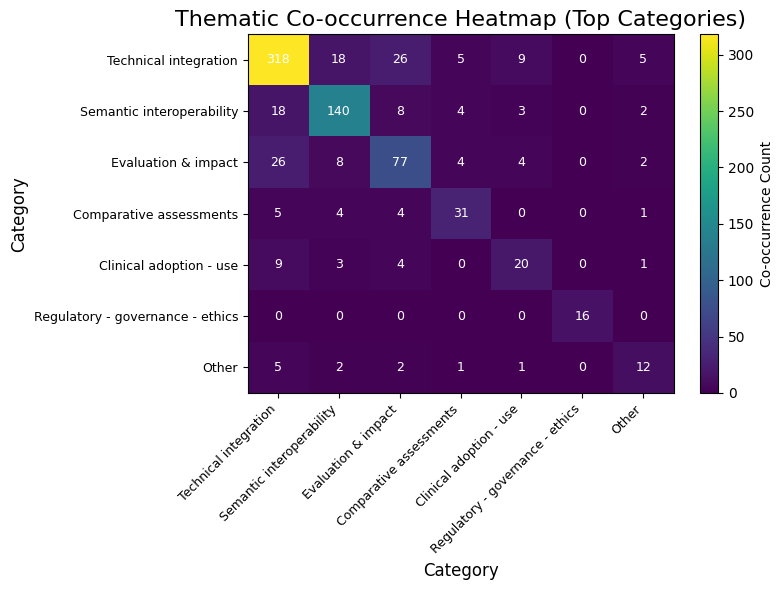

✅ `thematic_cooccurrence_heatmap_top7.csv` as CSV saved. 


In [11]:
import ast
import itertools

import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

TOP_N = 7

df = DATASET()
df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


# df = df.rename(
#     columns={
#         "DEFA_assigned_category_v3": "assigned_category",
#     }
# )

df["assigned_category"] = df["assigned_category"].apply(safe_eval)

df_exploded = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

df_exploded = df_exploded[df_exploded["assigned_category"] != ""]

top_categories = (
    df_exploded["assigned_category"]
    .value_counts()
    .head(TOP_N)
    .index
    .tolist()
)

if not top_categories:
    raise ValueError("No thematic categories found to build a co-occurrence matrix.")

coocc_df = pd.DataFrame(0, index=top_categories, columns=top_categories, dtype=int)

for categories in df["assigned_category"]:
    if not isinstance(categories, (list, tuple, set)):
        continue

    filtered = sorted({category for category in categories if category in top_categories})
    if not filtered:
        continue

    for category in filtered:
        coocc_df.loc[category, category] += 1

    for cat_a, cat_b in itertools.combinations(filtered, 2):
        coocc_df.loc[cat_a, cat_b] += 1
        coocc_df.loc[cat_b, cat_a] += 1

plt.figure(figsize=(8, 6))
plt.imshow(coocc_df, aspect="auto")
plt.colorbar(label="Co-occurrence Count")
plt.title("Thematic Co-occurrence Heatmap (Top Categories)", fontsize=16)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Category", fontsize=12)
plt.xticks(range(len(coocc_df.columns)), coocc_df.columns, rotation=45, ha="right", fontsize=9)
plt.yticks(range(len(coocc_df.index)), coocc_df.index, fontsize=9)

for i in range(len(coocc_df.index)):
    for j in range(len(coocc_df.columns)):
        plt.text(j, i, f"{coocc_df.iloc[i, j]}", ha="center", va="center", fontsize=9, color="white")

plt.subplots_adjust(bottom=0.25, left=0.25)

plt_savefig(plt, "thematic_cooccurrence_heatmap_top7.png")
plt.show()
plt.close()

dataframe_to_csv(
    coocc_df.reset_index().rename(columns={"index": "Category"}),
    "thematic_cooccurrence_heatmap_top7.csv",
)

### Three-Field Plot (Authors–Keywords–Journals)
A three-field plot was constructed to visualize the relationships between prolific authors, high-frequency keywords, and leading journals. Links represent co-occurrence at the document level, thereby illustrating how key contributors, research topics, and publication venues are interconnected across the corpus.

In [28]:
import ast
import pandas as pd
import plotly.graph_objects as go

from src.config import OUTPUT_DIR
from src.lib_dataset import (
    DATASET,
    keyword_map,
    unwanted_keywords,
)
from src.lib_visualization import dataframe_to_csv


# ============================================================
# Settings
# ============================================================

TOP_N_AUTHORS = 5
TOP_N_KEYWORDS = 10
TOP_N_JOURNALS = 7

MIN_EDGE_WEIGHT = 2
MAX_LABEL_LENGTH = 40


# ============================================================
# Load dataset
# ============================================================

df = DATASET().copy()
df = df.reset_index(drop=True)


# ============================================================
# Required fields
# ============================================================

required_columns = {
    "authors",
    "keywords",
    "journal_title",
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Required column(s) missing from dataset: "
        f"{sorted(missing_columns)}"
    )


# ============================================================
# Publication identifier
# ============================================================
#
# Using a publication-level identifier prevents accidental
# double counting if the same publication appears more than
# once in the source dataframe.
#
# ============================================================

if "DBUID" in df.columns:

    publication_id = (
        df["DBUID"]
        .astype("string")
        .str.strip()
    )

    missing_id = (
        publication_id.isna()
        | publication_id.eq("")
    )

    df["_publication_id"] = publication_id.astype(object)

    df.loc[
        missing_id,
        "_publication_id"
    ] = [
        f"__row_{i}"
        for i in df.index[missing_id]
    ]

else:

    df["_publication_id"] = [
        f"__row_{i}"
        for i in df.index
    ]


# ============================================================
# Prepare keyword normalization resources
# ============================================================
#
# IMPORTANT:
# Call keyword_map() and unwanted_keywords() only once.
#
# ============================================================

KEYWORD_MAP = {
    str(key).strip().lower(): str(value).strip()
    for key, value in keyword_map().items()
}


UNWANTED_KEYWORDS = {
    str(keyword).strip().lower()
    for keyword in unwanted_keywords()
}


# ============================================================
# Helper: safely convert values to list
# ============================================================

def safe_eval_list(value):

    if isinstance(value, list):
        return value

    if isinstance(value, (tuple, set)):
        return list(value)

    if pd.isna(value):
        return []

    if not isinstance(value, str):
        return [value]

    value = value.strip()

    if value == "":
        return []

    try:

        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        if isinstance(parsed, (tuple, set)):
            return list(parsed)

        return [parsed]

    except (ValueError, SyntaxError):

        # Keep ordinary strings rather than discarding them
        return [value]


# ============================================================
# Clean authors
# ============================================================

def clean_authors(values):

    cleaned = []
    seen = set()

    for value in values:

        if pd.isna(value):
            continue

        author = str(value).strip()

        if author == "":
            continue

        # Collapse repeated whitespace
        author = " ".join(author.split())

        dedup_key = author.lower()

        if dedup_key in seen:
            continue

        seen.add(dedup_key)
        cleaned.append(author)

    return cleaned


# ============================================================
# Clean and normalize keywords
# ============================================================
#
# Same general normalization policy used in the other keyword
# analyses:
#
# 1. trim
# 2. lowercase raw form
# 3. remove unwanted terms
# 4. map synonyms / variants using keyword_map()
# 5. remove unwanted terms again after mapping
# 6. deduplicate within publication
#
# ============================================================

def clean_keywords(values):

    cleaned = []
    seen = set()

    for value in values:

        if pd.isna(value):
            continue

        keyword = str(value).strip()

        if keyword == "":
            continue

        keyword_lower = keyword.lower()


        # ----------------------------------------------------
        # Remove unwanted raw keyword
        # ----------------------------------------------------

        if keyword_lower in UNWANTED_KEYWORDS:
            continue


        # ----------------------------------------------------
        # Normalize keyword
        # ----------------------------------------------------

        keyword_normalized = KEYWORD_MAP.get(
            keyword_lower,
            keyword_lower
        )

        keyword_normalized = str(
            keyword_normalized
        ).strip()


        if keyword_normalized == "":
            continue


        # ----------------------------------------------------
        # Remove unwanted normalized keyword
        # ----------------------------------------------------

        if (
            keyword_normalized.lower()
            in UNWANTED_KEYWORDS
        ):
            continue


        # ----------------------------------------------------
        # Deduplicate within publication
        # ----------------------------------------------------

        dedup_key = keyword_normalized.lower()

        if dedup_key in seen:
            continue

        seen.add(dedup_key)

        cleaned.append(
            keyword_normalized
        )

    return cleaned


# ============================================================
# Clean journal title
# ============================================================

def clean_journal(value):

    if pd.isna(value):
        return ""

    journal = str(value).strip()

    if journal == "":
        return ""

    # Collapse repeated whitespace
    journal = " ".join(
        journal.split()
    )

    return journal


# ============================================================
# Apply preprocessing
# ============================================================

df["authors"] = (
    df["authors"]
    .apply(safe_eval_list)
    .apply(clean_authors)
)


df["keywords"] = (
    df["keywords"]
    .apply(safe_eval_list)
    .apply(clean_keywords)
)


df["journal_title"] = (
    df["journal_title"]
    .apply(clean_journal)
)


# ============================================================
# Create publication-author table
# ============================================================

author_long = (
    df[
        [
            "_publication_id",
            "authors"
        ]
    ]
    .explode("authors")
    .rename(
        columns={
            "authors": "Author"
        }
    )
    .dropna(
        subset=["Author"]
    )
)


author_long["Author"] = (
    author_long["Author"]
    .astype(str)
    .str.strip()
)


author_long = author_long[
    author_long["Author"] != ""
].copy()


# Each publication contributes at most once to each author
author_long = (
    author_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "Author"
        ]
    )
)


# ============================================================
# Create publication-keyword table
# ============================================================

keyword_long = (
    df[
        [
            "_publication_id",
            "keywords"
        ]
    ]
    .explode("keywords")
    .rename(
        columns={
            "keywords": "Keyword"
        }
    )
    .dropna(
        subset=["Keyword"]
    )
)


keyword_long["Keyword"] = (
    keyword_long["Keyword"]
    .astype(str)
    .str.strip()
)


keyword_long = keyword_long[
    keyword_long["Keyword"] != ""
].copy()


# Each publication contributes at most once to each keyword
keyword_long = (
    keyword_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "Keyword"
        ]
    )
)


# ============================================================
# Create publication-journal table
# ============================================================

journal_long = (
    df[
        [
            "_publication_id",
            "journal_title"
        ]
    ]
    .rename(
        columns={
            "journal_title": "Journal"
        }
    )
    .copy()
)


journal_long = journal_long[
    journal_long["Journal"] != ""
].copy()


journal_long = (
    journal_long
    .drop_duplicates(
        subset=[
            "_publication_id",
            "Journal"
        ]
    )
)


# ============================================================
# Check availability
# ============================================================

if author_long.empty:
    raise ValueError(
        "No valid author data remained after preprocessing."
    )

if keyword_long.empty:
    raise ValueError(
        "No valid keyword data remained after preprocessing."
    )

if journal_long.empty:
    raise ValueError(
        "No valid journal data remained after preprocessing."
    )


# ============================================================
# Global entity frequencies
# ============================================================
#
# IMPORTANT:
#
# Top authors, keywords, and journals are determined from
# their respective publication-level frequencies across the
# corpus BEFORE complete-case filtering.
#
# This avoids defining "top" entities only from publications
# having all three fields simultaneously available.
#
# ============================================================

author_freq = (
    author_long
    .groupby(
        "Author",
        as_index=False
    )
    .agg(
        Documents=(
            "_publication_id",
            "nunique"
        )
    )
    .sort_values(
        [
            "Documents",
            "Author"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


keyword_freq = (
    keyword_long
    .groupby(
        "Keyword",
        as_index=False
    )
    .agg(
        Documents=(
            "_publication_id",
            "nunique"
        )
    )
    .sort_values(
        [
            "Documents",
            "Keyword"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


journal_freq = (
    journal_long
    .groupby(
        "Journal",
        as_index=False
    )
    .agg(
        Documents=(
            "_publication_id",
            "nunique"
        )
    )
    .sort_values(
        [
            "Documents",
            "Journal"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Save global frequencies
# ============================================================

dataframe_to_csv(
    author_freq,
    "three_field_author_frequency.csv"
)


dataframe_to_csv(
    keyword_freq,
    "three_field_keyword_frequency.csv"
)


dataframe_to_csv(
    journal_freq,
    "three_field_journal_frequency.csv"
)


# ============================================================
# Select top global entities
# ============================================================

top_authors = (
    author_freq
    .head(TOP_N_AUTHORS)
    ["Author"]
    .tolist()
)


top_keywords = (
    keyword_freq
    .head(TOP_N_KEYWORDS)
    ["Keyword"]
    .tolist()
)


top_journals = (
    journal_freq
    .head(TOP_N_JOURNALS)
    ["Journal"]
    .tolist()
)


# ============================================================
# Complete-case publication IDs for Three-Field structure
# ============================================================
#
# Only publications containing:
#
#   author + keyword + journal
#
# can contribute to the actual Three-Field relationships.
#
# This restriction is applied AFTER determining the global
# top entities.
#
# ============================================================

author_publications = set(
    author_long["_publication_id"]
)

keyword_publications = set(
    keyword_long["_publication_id"]
)

journal_publications = set(
    journal_long["_publication_id"]
)


complete_publications = (
    author_publications
    & keyword_publications
    & journal_publications
)


if not complete_publications:

    raise ValueError(
        "No publications contain valid authors, "
        "keywords, and journal information simultaneously."
    )


print(
    f"Publications with complete author-keyword-journal data: "
    f"{len(complete_publications)}"
)


# ============================================================
# Restrict long tables to complete publications
# ============================================================

author_complete = author_long[
    author_long["_publication_id"].isin(
        complete_publications
    )
].copy()


keyword_complete = keyword_long[
    keyword_long["_publication_id"].isin(
        complete_publications
    )
].copy()


journal_complete = journal_long[
    journal_long["_publication_id"].isin(
        complete_publications
    )
].copy()


# ============================================================
# Keep top entities
# ============================================================

author_selected = author_complete[
    author_complete["Author"].isin(
        top_authors
    )
].copy()


keyword_selected = keyword_complete[
    keyword_complete["Keyword"].isin(
        top_keywords
    )
].copy()


journal_selected = journal_complete[
    journal_complete["Journal"].isin(
        top_journals
    )
].copy()


# ============================================================
# Author -> Keyword document-level links
# ============================================================

author_keyword_pairs = (
    author_selected
    .merge(
        keyword_selected,
        on="_publication_id",
        how="inner"
    )
    [
        [
            "_publication_id",
            "Author",
            "Keyword"
        ]
    ]
    .drop_duplicates()
)


author_keyword_df = (
    author_keyword_pairs
    .groupby(
        [
            "Author",
            "Keyword"
        ],
        as_index=False
    )
    .agg(
        Weight=(
            "_publication_id",
            "nunique"
        )
    )
)


author_keyword_df = author_keyword_df[
    author_keyword_df["Weight"]
    >= MIN_EDGE_WEIGHT
].copy()


# ============================================================
# Keyword -> Journal document-level links
# ============================================================

keyword_journal_pairs = (
    keyword_selected
    .merge(
        journal_selected,
        on="_publication_id",
        how="inner"
    )
    [
        [
            "_publication_id",
            "Keyword",
            "Journal"
        ]
    ]
    .drop_duplicates()
)


keyword_journal_df = (
    keyword_journal_pairs
    .groupby(
        [
            "Keyword",
            "Journal"
        ],
        as_index=False
    )
    .agg(
        Weight=(
            "_publication_id",
            "nunique"
        )
    )
)


keyword_journal_df = keyword_journal_df[
    keyword_journal_df["Weight"]
    >= MIN_EDGE_WEIGHT
].copy()


# ============================================================
# Validate edge structure
# ============================================================

if author_keyword_df.empty:

    raise ValueError(
        "No Author–Keyword links remained after applying "
        f"MIN_EDGE_WEIGHT={MIN_EDGE_WEIGHT}. "
        "Try lowering the threshold."
    )


if keyword_journal_df.empty:

    raise ValueError(
        "No Keyword–Journal links remained after applying "
        f"MIN_EDGE_WEIGHT={MIN_EDGE_WEIGHT}. "
        "Try lowering the threshold."
    )


# ============================================================
# Keep only keywords connected on BOTH sides
# ============================================================

connected_keywords = sorted(
    set(
        author_keyword_df["Keyword"]
    )
    &
    set(
        keyword_journal_df["Keyword"]
    )
)


if not connected_keywords:

    raise ValueError(
        "No keywords connect both the Author and Journal "
        "fields after edge filtering."
    )


author_keyword_df = author_keyword_df[
    author_keyword_df["Keyword"].isin(
        connected_keywords
    )
].copy()


keyword_journal_df = keyword_journal_df[
    keyword_journal_df["Keyword"].isin(
        connected_keywords
    )
].copy()


if (
    author_keyword_df.empty
    or keyword_journal_df.empty
):

    raise ValueError(
        "No connected Author–Keyword–Journal structure "
        "could be constructed."
    )


# ============================================================
# Re-rank connected authors
# ============================================================

author_rank = (
    author_keyword_df
    .groupby(
        "Author",
        as_index=False
    )
    .agg(
        Weight=(
            "Weight",
            "sum"
        )
    )
    .sort_values(
        [
            "Weight",
            "Author"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Re-rank connected keywords
# ============================================================

keyword_rank_left = (
    author_keyword_df
    .groupby(
        "Keyword",
        as_index=False
    )
    ["Weight"]
    .sum()
    .rename(
        columns={
            "Weight":
                "Author_Keyword_Weight"
        }
    )
)


keyword_rank_right = (
    keyword_journal_df
    .groupby(
        "Keyword",
        as_index=False
    )
    ["Weight"]
    .sum()
    .rename(
        columns={
            "Weight":
                "Keyword_Journal_Weight"
        }
    )
)


keyword_rank = (
    keyword_rank_left
    .merge(
        keyword_rank_right,
        on="Keyword",
        how="inner"
    )
)


keyword_rank["Total_Weight"] = (
    keyword_rank[
        "Author_Keyword_Weight"
    ]
    +
    keyword_rank[
        "Keyword_Journal_Weight"
    ]
)


keyword_rank = (
    keyword_rank
    .sort_values(
        [
            "Total_Weight",
            "Keyword"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Re-rank connected journals
# ============================================================

journal_rank = (
    keyword_journal_df
    .groupby(
        "Journal",
        as_index=False
    )
    .agg(
        Weight=(
            "Weight",
            "sum"
        )
    )
    .sort_values(
        [
            "Weight",
            "Journal"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Save connected rankings
# ============================================================

dataframe_to_csv(
    author_rank,
    "three_field_author_rank_connected.csv"
)


dataframe_to_csv(
    keyword_rank,
    "three_field_keyword_rank_connected.csv"
)


dataframe_to_csv(
    journal_rank,
    "three_field_journal_rank_connected.csv"
)


# ============================================================
# Save edges
# ============================================================

dataframe_to_csv(
    author_keyword_df,
    "three_field_author_keyword_edges.csv"
)


dataframe_to_csv(
    keyword_journal_df,
    "three_field_keyword_journal_edges.csv"
)


# ============================================================
# Ordered connected entities
# ============================================================

connected_authors = (
    author_rank["Author"]
    .tolist()
)


connected_keywords = (
    keyword_rank["Keyword"]
    .tolist()
)


connected_journals = (
    journal_rank["Journal"]
    .tolist()
)


# ============================================================
# Label helper
# ============================================================

def truncate_label(
    text,
    max_len=40
):

    text = str(text).strip()

    if len(text) <= max_len:
        return text

    return (
        text[:max_len - 3]
        + "..."
    )


# ============================================================
# Build node indices
# ============================================================
#
# IMPORTANT:
#
# Internal IDs are based on the full entity values rather
# than truncated display labels.
#
# This avoids collisions if two long labels have the same
# truncated text.
#
# ============================================================

author_node_map = {
    author: i
    for i, author
    in enumerate(
        connected_authors
    )
}


keyword_offset = len(
    connected_authors
)


keyword_node_map = {
    keyword:
        keyword_offset + i

    for i, keyword
    in enumerate(
        connected_keywords
    )
}


journal_offset = (
    len(connected_authors)
    +
    len(connected_keywords)
)


journal_node_map = {
    journal:
        journal_offset + i

    for i, journal
    in enumerate(
        connected_journals
    )
}


# ============================================================
# Display labels
# ============================================================

node_labels = (

    [
        "Author | "
        + truncate_label(
            author,
            MAX_LABEL_LENGTH
        )
        for author
        in connected_authors
    ]

    +

    [
        "Keyword | "
        + truncate_label(
            keyword,
            MAX_LABEL_LENGTH
        )
        for keyword
        in connected_keywords
    ]

    +

    [
        "Journal | "
        + truncate_label(
            journal,
            MAX_LABEL_LENGTH
        )
        for journal
        in connected_journals
    ]

)


# ============================================================
# Build Sankey links
# ============================================================

sources = []
targets = []
values = []


# ------------------------------------------------------------
# Author -> Keyword
# ------------------------------------------------------------

for _, row in author_keyword_df.iterrows():

    sources.append(
        author_node_map[
            row["Author"]
        ]
    )

    targets.append(
        keyword_node_map[
            row["Keyword"]
        ]
    )

    values.append(
        int(
            row["Weight"]
        )
    )


# ------------------------------------------------------------
# Keyword -> Journal
# ------------------------------------------------------------

for _, row in keyword_journal_df.iterrows():

    sources.append(
        keyword_node_map[
            row["Keyword"]
        ]
    )

    targets.append(
        journal_node_map[
            row["Journal"]
        ]
    )

    values.append(
        int(
            row["Weight"]
        )
    )


# ============================================================
# Plot
# ============================================================

fig = go.Figure(

    data=[

        go.Sankey(

            arrangement="snap",

            node=dict(

                pad=16,

                thickness=18,

                line=dict(
                    color="black",
                    width=0.4
                ),

                label=node_labels,

            ),

            link=dict(

                source=sources,

                target=targets,

                value=values,

            ),

        )

    ]

)


fig.update_layout(

    title={

        "text":
            "Three-Field Plot (Authors–Keywords–Journals)",

        "x": 0.5,

    },

    font=dict(
        size=10
    ),

)


# ============================================================
# Save interactive HTML
# ============================================================

html_path = (
    OUTPUT_DIR
    / "three_field_plot_authors_keywords_journals.html"
)


fig.write_html(
    str(html_path)
)


print(
    "Saved HTML: "
    "three_field_plot_authors_keywords_journals.html"
)


# ============================================================
# Save PNG
# ============================================================

png_path = (
    OUTPUT_DIR
    / "three_field_plot_authors_keywords_journals.png"
)


try:

    fig.write_image(

        str(png_path),

        format="png",

        scale=2,

    )

    print(
        "Saved PNG: "
        "three_field_plot_authors_keywords_journals.png"
    )

except Exception as e:

    print(
        "Could not save PNG "
        "(Plotly static export error):"
    )

    print(e)


# ============================================================
# Summary
# ============================================================

print("\n=== Three-Field Plot Summary ===")

print(
    f"Top authors initially selected: "
    f"{len(top_authors)}"
)

print(
    f"Top normalized keywords initially selected: "
    f"{len(top_keywords)}"
)

print(
    f"Top journals initially selected: "
    f"{len(top_journals)}"
)

print(
    f"Connected authors displayed: "
    f"{len(connected_authors)}"
)

print(
    f"Connected keywords displayed: "
    f"{len(connected_keywords)}"
)

print(
    f"Connected journals displayed: "
    f"{len(connected_journals)}"
)

print(
    f"Author–Keyword edges: "
    f"{len(author_keyword_df)}"
)

print(
    f"Keyword–Journal edges: "
    f"{len(keyword_journal_df)}"
)


# ============================================================
# Display
# ============================================================

fig.show()

✅ `three_field_author_frequency.csv` as CSV saved. 
✅ `three_field_keyword_frequency.csv` as CSV saved. 
✅ `three_field_journal_frequency.csv` as CSV saved. 
Publications with complete author-keyword-journal data: 437
✅ `three_field_author_rank_connected.csv` as CSV saved. 
✅ `three_field_keyword_rank_connected.csv` as CSV saved. 
✅ `three_field_journal_rank_connected.csv` as CSV saved. 
✅ `three_field_author_keyword_edges.csv` as CSV saved. 
✅ `three_field_keyword_journal_edges.csv` as CSV saved. 
Saved HTML: three_field_plot_authors_keywords_journals.html
Saved PNG: three_field_plot_authors_keywords_journals.png

=== Three-Field Plot Summary ===
Top authors initially selected: 5
Top normalized keywords initially selected: 10
Top journals initially selected: 7
Connected authors displayed: 5
Connected keywords displayed: 6
Connected journals displayed: 7
Author–Keyword edges: 18
Keyword–Journal edges: 26
